In [ ]:
sub_tot[2]

In [98]:
taus[0]

np.float64(0.3981071705534972)

In [100]:
np.asarray(my_info_ec[:]).shape

(1013, 50)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat
import os
from scipy import signal
import pandas as pd
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.metrics.pairwise import cosine_similarity
from tqdm import tqdm
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import zscore

In [2]:
import numpy as np
from scipy.linalg import expm, sqrtm, norm
import networkx as nx
#import community as community_louvain
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
from scipy import signal

In [3]:
import sys

sys.path.append('/home/benedetta/Scripts/Insight_project/')


In [4]:
from my_module import *
import sys
sys.path.append('/home/benedetta/Scripts/Insight_project/pyMOU-master/pymou/')
from mou_model import *

In [ ]:
np.asarray(taus_est_62).shape

In [6]:

for sub in sub_tot[1000:1001]:
    print(sub)

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.7],btype ='bandpass',fs = 1/0.7)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)

NameError: name 'sub_tot' is not defined

In [7]:
b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.7)
data_ref=signal.filtfilt(b,a,data_1,axis = 0)
Y = data_ref
Q0 = calc_Q0(Y)
Q1 = calc_Qlag(Y,1)
lag=1

ac = np.hstack((Q0.diagonal(), Q1.diagonal()))
log_ac = np.log( np.maximum( ac, ac.max() * 1e-6 ) )
v_lag = np.hstack(([0]*Q0.shape[0], [lag]*Q0.shape[0]))
lin_reg = np.polyfit(v_lag, log_ac, 1)
tau_obj=-1.0 / lin_reg[0]
print(tau_obj)


#Y = data_ref
Q0 = calc_Corr0(Y)
Q1 = calc_Corrlag(Y,2)
lag=2

ac = np.hstack((Q0.diagonal(), Q1.diagonal()))
log_ac = np.log( np.maximum( ac, ac.max() * 1e-6 ) )
v_lag = np.hstack(([0]*Q0.shape[0], [lag]*Q0.shape[0]))
lin_reg = np.polyfit(v_lag, log_ac, 1)
tau_obj_=-1.0 / lin_reg[0]
tau_obj_

NameError: name 'data_1' is not defined

0.8340953088759164 0.4377537706574123


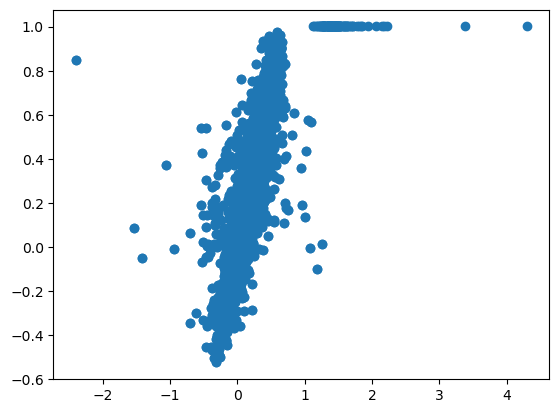

In [13]:
Y = data_ref
Q0 = calc_Corr0(Y)
Q1 = calc_Corrlag(Y,1)
mou_LO = MOU()
#tau_ = 0.3
mou_LO.fit_LO(Q0,Q1, prior=0,tau = float(tau_obj),lag=1,eta_C = 0.005,max_iter = 3000,)
#print(tau_)
J_LO = np.copy(mou_LO.J)



print(mou_LO.d_fit['correlation'],mou_LO.d_fit['distance'])

Q0m = mou_LO.model_covariance(0)
Q1m = mou_LO.model_covariance(0)

plt.scatter(Q0m,Q0)
plt.show()


In [11]:
mou_LO.d_fit['correlation'],mou_LO.d_fit['distance']

(np.float64(0.8340953088759164), np.float64(0.4377537706574123))

979984


In [5]:


pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))
nparcel = 100
if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
"""
for sub in sub_tot[1000:1001]:
    print(sub)

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
"""
sub_tot=[]
for sub in tqdm(pat):
    #print(sub)

    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        data_2 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        if len(data_1) ==1200 and len(data_2) ==1200:
            sub_tot.append(sub)
        

100%|██████████| 1097/1097 [00:01<00:00, 751.16it/s]


In [12]:
corr_=np.load('correlations_74_tau.npy')
corr_.shape
corr=np.load('precisionmatrix_74_tau.npy')
corr.shape

(1013, 22)

In [13]:
#np.save('correlations_74_tau.npy', corr_)
#np.save('precisionmatrix_74_tau.npy', corr)


## Verifica di Tau per i vari soggetti

In [23]:
pat = np.sort(os.listdir('/home/benedetta/hcp_parcellated/'))
nparcel=100
if nparcel == 100:
    source = '/home/benedetta/hcp_parcellated/'
elif nparcel == 200:
    source = '/home/benedetta/hcp_parcellated/Schaefer200+AAL/'
from tqdm import tqdm
sub_tot=[]
for sub in tqdm(pat[:]):
    if os.path.exists(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy') and os.path.exists(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy'):
        data_1 = np.load(f'{source}{sub}/{sub}_REST1_LR_Schaefer{nparcel}+AAL.npy')
        b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref=signal.filtfilt(b,a,data_1,axis = 0)
        data_2 = np.load(f'{source}{sub}/{sub}_REST2_LR_Schaefer{nparcel}+AAL.npy')
        b,a =signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
        data_ref_2=signal.filtfilt(b,a,data_2,axis = 0)

        if data_ref.shape[0]==1200 and data_ref_2.shape[0]==1200:
            sub_tot.append(sub)

100%|██████████| 1097/1097 [00:09<00:00, 111.81it/s]


In [6]:
len(sub_tot)#sub_tot

1013

## verifica autocorrelation time

In [18]:
from statsmodels.tsa.stattools import acf, ccf
cc=[]
for i in range(Y.shape[1]):
    auto_corr = acf(Y[:,i], nlags=100, fft=True)
    cc.append(auto_corr) 
#auto_corr = acf(Y[:,10], nlags=100, fft=True)
cc=np.asarray(cc)
x=np.arange(0,len(auto_corr),1)
plt.plot(x, cc.T);
#plt.plot(x, np.exp(-x/tau_obj), color='red');

plt.plot(x, np.exp(-x/tau_obj), color='purple', label =r'$e^{-x/\tau}$, $\tau$='+ f'{round(tau_obj,2)}');

plt.plot([x[0], x[1]], [auto_corr[0],auto_corr[1]], 'o', color='purple')

plt.plot([x[0], x[2]], [auto_corr[0],auto_corr[2]], 'o', color='orange')

plt.plot(x, np.exp(-x/tau_obj_), color='orange', label =r'$e^{-x/\tau}$, $\tau$='+ f'{round(tau_obj_,2)}');
#plt.legend()
plt.xlim(0,20)
plt.yscale('log');
plt.ylim(.001,1)

NameError: name 'Y' is not defined

In [ ]:
plt.plot8n

In [11]:
taus

np.float64(0.44668359215096315)

In [30]:
cd pyMOU-master/pymou/

/home/benedetta/Scripts/Insight_project/pyMOU-master/pymou


In [7]:
from mou_model import *

In [37]:
number = 112
mask_ = np.eye(number)
mask = np.logical_not(mask_)
norm = False
#for sub in range(len(iss_ms[:20])):
sub = 0


corr =[]
dist=[]
corr_=[]

taus =[0.7]
for tau_ in taus:
    dataset_i = data_2
    if norm == False:
        Q0_data = calc_Q0(dataset_i)
        Q1_data = calc_Qlag(dataset_i,1)
    else:
        Q0_data = calc_Corr0(dataset_i)
        Q1_data = calc_Corrlag(dataset_i,1)

    mou_LO = MOU()
    #tau_ = 0.3
    mou_LO.fit_LO(Q0_data,Q1_data, prior=0,lag=1,eta_C = 0.005,max_iter = 3000,)
    print(tau_)
    J_LO = np.copy(mou_LO.J)
    corr.append(np.corrcoef((J_LO[mask]).flatten(), (Q0_data[mask]).flatten())[0,1])
    #corr.append(mou_LO.)

    dist.append(mou_LO.d_fit['distance'])
    corr_.append(mou_LO.d_fit['correlation'])
    

0.7


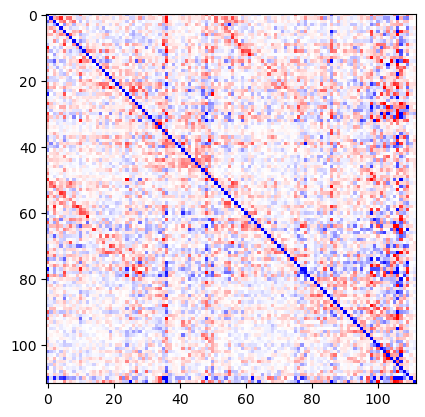

In [39]:
plt.imshow((J_LO), vmin=-.1, vmax=.1, cmap='bwr');

In [9]:
Y = data_ref
Q0 = calc_Q0(Y)
Q1 = calc_Qlag(Y,1)
lag=1

ac = np.hstack((Q0.diagonal(), Q1.diagonal()))
log_ac = np.log( np.maximum( ac, ac.max() * 1e-6 ) )
v_lag = np.hstack(([0]*Q0.shape[0], [lag]*Q0.shape[0]))
lin_reg = np.polyfit(v_lag, log_ac, 1)
tau_obj=-1.0 / lin_reg[0]
print(tau_obj)


#Y = data_ref
Q0 = calc_Corr0(Y)
Q1 = calc_Corrlag(Y,2)
lag=2

ac = np.hstack((Q0.diagonal(), Q1.diagonal()))
log_ac = np.log( np.maximum( ac, ac.max() * 1e-6 ) )
v_lag = np.hstack(([0]*Q0.shape[0], [lag]*Q0.shape[0]))
lin_reg = np.polyfit(v_lag, log_ac, 1)
tau_obj_=-1.0 / lin_reg[0]
tau_obj_

NameError: name 'data_ref' is not defined

In [12]:
pwd

'/home/benedetta/Scripts/Insight_project/Notebook figure'

In [11]:
cd ..

/home/benedetta/Scripts/Insight_project


In [10]:
from my_module import *

In [7]:
cd pyMOU-master/pymou/

/home/benedetta/Scripts/Insight_project/pyMOU-master/pymou


In [8]:
from mou_model import *

In [7]:
def asym(a):
    return np.sum(np.abs(a - a.T))




In [6]:
def asym_norm(a):
    #a = dediag(a)
    return np.sum(np.abs(a - a.T))/np.sum(np.abs(a))/2

In [ ]:
taus = np.arange(0.4,1.2,0.05)
taus.shape

In [8]:
from my_module import *
import sys
sys.path.append('../pyMOU-master/')
from pymou.mou_model import *

In [23]:
from scipy import signal

corr=[[] for i in range(len(sub_tot))]
corr_=[[] for i in range(len(sub_tot))]
ass =  [[] for i in range(len(sub_tot))]
taus = np.arange(0.4,1.5,0.05)
MAX_ITER =100
for l, sub in enumerate(tqdm(sub_tot[::100])):
    for tau_ in taus:
        if os.path.exists(f'/home/benedetta/hcp_parcellated/{sub}/{sub}_REST1_LR_Schaefer100+AAL.npy'):
            if os.path.exists(f'/home/benedetta/hcp_parcellated/{sub}/{sub}_REST1_LR_Schaefer100+AAL.npy'):
                data_1 = np.load(f'/home/benedetta/hcp_parcellated/{sub}/{sub}_REST1_LR_Schaefer100+AAL.npy')
                b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
                data_ref=signal.filtfilt(b,a,data_1,axis = 0)
                Y = cluster_regions(data_ref, aggregate)
                
                m = MOU()
                Q0 = calc_Corr0(Y)
                Q1 = calc_Corrlag(Y,1)
            
                m.fit_LO(Q0,Q1,lag = 1,prior =0.,tau=float(tau_), eta_C=0.005, max_iter = MAX_ITER)
                J_prior = m.J;

                if m.d_fit['iterations'] == MAX_ITER:
                    print(tau_, "", MAX_ITER, "iterations")

                ass[l].append(asym_norm((J_prior)))
                
                corr[l].append(np.corrcoef(dediag(J_prior).flatten(), dediag(np.linalg.inv(Q0)).flatten())[0,1])
                corr_[l].append(np.corrcoef(dediag(J_prior).flatten(), dediag((Q0)).flatten())[0,1])
                #orr[l].append(np.corrcoef(dediag(J_prior).flatten(), dediag(np.linalg.inv(Q0)).flatten())[0,1])


  0%|          | 0/11 [00:00<?, ?it/s]

Optimization did not converge. Maximum number of iterations arrived.
1.15  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.1999999999999997  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.25  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.2999999999999998  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.3499999999999996  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.4  100 iterations


  9%|▉         | 1/11 [00:17<02:52, 17.22s/it]

Optimization did not converge. Maximum number of iterations arrived.
1.4499999999999997  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.4  100 iterations


 18%|█▊        | 2/11 [00:34<02:34, 17.13s/it]

...

 73%|███████▎  | 8/11 [02:09<00:47, 15.85s/it]

Optimization did not converge. Maximum number of iterations arrived.
1.4499999999999997  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.1999999999999997  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.25  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.2999999999999998  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.3499999999999996  100 iterations
Optimization did not converge. Maximum number of iterations arrived.
1.4  100 iterations


 82%|████████▏ | 9/11 [02:24<00:31, 15.58s/it]

Optimization did not converge. Maximum number of iterations arrived.
1.4499999999999997  100 iterations


/home/benedetta/miniconda_temp/envs/graph_tool_env/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/benedetta/miniconda_temp/envs/graph_tool_env/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
100%|██████████| 11/11 [02:44<00:00, 14.99s/it]


In [ ]:
list(map(len, corr))[:12]

In [26]:
c = np.asarray(corr[:11])

c_ = np.asarray(corr_[:11])
c_.shape
c.shape


assy = np.asarray(ass[:11])
assy.shape

(11, 22)

In [30]:
corr = np.asarray(corr[:102])
corr_ = np.asarray(corr_[:102])

ass = np.asarray(ass[:102])

In [ ]:
corr_S_Q1asym.shape

In [221]:
import sys
sys.path.append('numpy files')
np.save('../numpy files/ass_100_1013_log.npy',ass100)
np.save('../numpy files/corr_100_1013_log.npy',corr100)
np.save('../numpy files/corr__100_1013_log.npy', corr100_)
np.save('../numpy files/corr_S_Q1asym_100_1013_log.npy', corr_S_Q1asym)

In [176]:
import sys
sys.path.append('numpy files')
np.save('../numpy files/ass_62_1013_log.npy',ass100)
np.save('../numpy files/corr_62_1013_log.npy',corr100)
np.save('../numpy files/corr__62_1013_log.npy', corr100_)
np.save('../numpy files/corr_S_Q1asym_62_1013_log.npy', corr_S_Q1asym)

In [144]:
import sys
sys.path.append('numpy files')
np.save('../numpy files/ass_62_102sub_log.npy',ass)
np.save('../numpy files/corr_62_102sub_log.npy',corr)
np.save('../numpy files/corr__62_102sub_log.npy', corr_)
np.save('../numpy files/corr_S_Q1asym_62_102sub_log.npy', corr_S_Q1asym)

#corr_S_Q1asym
#corr.shape

In [94]:
#np.save('ass_74_102sub.npy',ass)
#np.save('corr_74_102sub.npy',corr)
#np.save('corr__74_102sub.npy',corr_)

In [16]:
ass = np.asarray(ass)
ass.shape

(102, 22)

In [41]:
asym(J_prior), asym(dediag(J_prior)), 

(np.float64(0.10458083854209689), np.float64(0.16998619590986197))

In [124]:
import numpy as np
from scipy.linalg import schur

def measure_non_normality(A):
    # 1. Indice di Henrici tramite Decomposizione di Schur
    # A = Z T Z* dove T è triangolare superiore (Schur form)
    T, Z = schur(A, output='complex')
    
    # La parte non diagonale di T rappresenta la deviazione dalla normalità
    diag_T = np.diag(np.diag(T))
    N = T - diag_T
    henrici_index = np.linalg.norm(N, ord='fro')
    
    # 2. Commutatore di Normalità: ||A*A - AA*||
    A_h = A.conj().T
    commutator = A_h @ A - A @ A_h
    norm_commutator = np.linalg.norm(commutator, ord='fro')
    
    # 3. Rapporto di Henrici (Normalizzato)
    norm_A_sq = np.linalg.norm(A, ord='fro')**2
    relative_index = norm_commutator / norm_A_sq if norm_A_sq != 0 else 0
    #henrici_index = np.linalg.norm(N, ord='fro') / np.linalg.norm(T, ord='fro')
    return {
        "henrici_index": henrici_index,
        "norm_commutator": norm_commutator,
        "relative_index": relative_index
    }

# Esempio d'uso
A = np.array([[1, 2], 
              [0, 1]])  # Matrice non normale (shear matrix)

results = measure_non_normality(A)

print(f"Indice di Henrici (||N||_F): {results['henrici_index']:.4f}")
print(f"Norma del Commutatore: {results['norm_commutator']:.4f}")
print(f"Indice Relativo: {results['relative_index']:.4f}")


Indice di Henrici (||N||_F): 2.0000
Norma del Commutatore: 5.6569
Indice Relativo: 0.9428


### Runnare questo per fare figure

In [79]:
def plot_fc_matrix(fc, labels, ax, cmap="bwr", vmin=-0.2, vmax=0.2, fontsize = 13, pos = 7, plot_networks=False,plot_emi_x =True,plot_emi_y =True):

    def parse_label(lab):
        return lab.split("_")[0], lab.split("_")[1]

    # ---- grouping ----
    groups = OrderedDict()
    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        groups.setdefault(f"{hemi}_{net}", []).append(i)

    new_order, bounds, names = [], [], []
    start = 0

    for key, idxs in groups.items():
        new_order.extend(idxs)
        end = start + len(idxs)
        bounds.append((start, end))
        names.append(key)
        start = end

    fc_ord = fc[np.ix_(new_order, new_order)]
    n = fc_ord.shape[0]

    im = ax.imshow(fc_ord, cmap=cmap, vmin=vmin, vmax=vmax)

    # ---- boundaries ----
    ticks = [0] + [end for _, end in bounds]

    ax.set_xticks(np.array(ticks)-.5)
    ax.set_yticks(np.array(ticks)-.5)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.tick_params(axis='x', bottom=True, labelbottom=True)
    if plot_networks:
        for t in ticks:
            ax.axhline(t - 0.5, color="black", linewidth=0.2)
            ax.axvline(t - 0.5, color="black", linewidth=0.2)

    # ---- LH / RH separation ----
    lh_count = sum(lab.startswith("LH_") for lab in labels)
    ax.axhline(lh_count - 0.5, color="black", linewidth=0.5)
    ax.axvline(lh_count - 0.5, color="black", linewidth=0.5)

        # ---- labels ----
    if plot_networks:
        for (start, end), name in zip(bounds, names):
            center = (start + end) / 2
            hemi, net = name.split("_")
        
            ax.text(center-.5, n + 1, f"{net}",
                    ha="center", va="top",
                    rotation=70, clip_on=False,fontsize = fontsize)
        
            ax.text(-1, center-.5, f"{net}",
                    ha="right", va="center", clip_on=False,fontsize = fontsize )
        
            ax.set_xlim(-0.5, n - 0.5)
            ax.set_ylim(n - 0.5, -0.5)
            
    # ---- LH / RH labels ----
    lh_center = lh_count / 2
    rh_center = lh_count + (n - lh_count) / 2
    
    offset_x = n + 1   # distanza sull'asse x (sopra le label dei network)
    offset_y = -1    # distanza sull'asse y (a sinistra delle label dei network)
    
    # Asse X (sopra)
    if plot_emi_x:
        ax.text(lh_center 
                , offset_x+pos, "LH",
                ha="center", va="top",
                fontweight='bold', clip_on=False, fontsize = 20)
        ax.text(rh_center , offset_x+pos, "RH",
                ha="center", va="top",
                fontweight='bold', clip_on=False, fontsize = 20)
    if plot_emi_y:
        # Asse Y (sinistra)
        ax.text(offset_y-pos, lh_center , "LH",
                ha="right", va="center",
                fontweight='bold', clip_on=False, fontsize = 20)
        ax.text(offset_y-pos, rh_center , "RH",
                ha="right", va="center",
                fontweight='bold', clip_on=False, fontsize = 20)

    return im

import numpy as np
from collections import OrderedDict

def plot_fc_matrix(
    fc,
    labels,
    ax,
    cmap="bwr",
    vmin=-0.2,
    vmax=0.2,
    fontsize=13,
    pos=7,
    plot_networks=False,
    plot_emi_x=True,
    plot_emi_y=True
):

    fc = np.asarray(fc)
    labels = np.asarray(labels)

    if fc.shape != (62, 62):
        raise ValueError(f"fc deve essere 62x62, invece è {fc.shape}")

    if len(labels) != 62:
        raise ValueError(f"labels deve contenere 62 elementi, invece ne contiene {len(labels)}")

    def parse_label(lab):
        parts = str(lab).split("_")
        hemi = parts[0]
        net = parts[1]
        return hemi, net

    # ============================================================
    # GROUPING: hemisphere + network
    # ============================================================

    groups = OrderedDict()

    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        key = f"{hemi}_{net}"
        groups.setdefault(key, []).append(i)

    new_order = []
    bounds = []
    names = []

    start = 0

    for key, idxs in groups.items():

        new_order.extend(idxs)

        end = start + len(idxs)

        bounds.append((start, end))
        names.append(key)

        start = end

    # ============================================================
    # REORDER MATRIX AND LABELS
    # ============================================================

    fc_ord = fc[np.ix_(new_order, new_order)]
    labels_ord = labels[new_order]

    n = fc_ord.shape[0]

    # ============================================================
    # PLOT
    # ============================================================

    im = ax.imshow(
        fc_ord,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        interpolation="none"
    )

    # ============================================================
    # NETWORK BOUNDARIES
    # ============================================================

    ticks = [0] + [end for _, end in bounds]

    ax.set_xticks(np.array(ticks) - 0.5)
    ax.set_yticks(np.array(ticks) - 0.5)

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.tick_params(
        axis="both",
        length=0
    )

    if plot_networks:

        for t in ticks:

            ax.axhline(
                t - 0.5,
                color="black",
                linewidth=0.2
            )

            ax.axvline(
                t - 0.5,
                color="black",
                linewidth=0.2
            )

    # ============================================================
    # LH / RH SEPARATION
    # ============================================================

    # IMPORTANT: use reordered labels
    lh_count = np.sum(
        [str(lab).startswith("LH_") for lab in labels_ord]
    )

    if 0 < lh_count < n:

        ax.axhline(
            lh_count - 0.5,
            color="black",
            linewidth=0.8
        )

        ax.axvline(
            lh_count - 0.5,
            color="black",
            linewidth=0.8
        )

    # ============================================================
    # NETWORK LABELS
    # ============================================================

    if plot_networks:

        for (start, end), name in zip(bounds, names):

            center = (start + end) / 2

            hemi, net = name.split("_", 1)

            # X axis
            ax.text(
                center - 0.5,
                n + 1,
                net,
                ha="center",
                va="top",
                rotation=70,
                clip_on=False,
                fontsize=fontsize
            )

            # Y axis
            ax.text(
                -1,
                center - 0.5,
                net,
                ha="right",
                va="center",
                clip_on=False,
                fontsize=fontsize
            )

    # ============================================================
    # LH / RH LABELS
    # ============================================================

    lh_center = lh_count / 2 - 0.5
    rh_center = lh_count + (n - lh_count) / 2 - 0.5

    offset_x = n + 1
    offset_y = -1

    if plot_emi_x:

        if lh_count > 0:
            ax.text(
                lh_center,
                offset_x + pos,
                "LH",
                ha="center",
                va="top",
                fontweight="bold",
                clip_on=False,
                fontsize=20
            )

        if lh_count < n:
            ax.text(
                rh_center,
                offset_x + pos,
                "RH",
                ha="center",
                va="top",
                fontweight="bold",
                clip_on=False,
                fontsize=20
            )

    if plot_emi_y:

        if lh_count > 0:
            ax.text(
                offset_y - pos,
                lh_center,
                "LH",
                ha="right",
                va="center",
                fontweight="bold",
                clip_on=False,
                fontsize=20
            )

        if lh_count < n:
            ax.text(
                offset_y - pos,
                rh_center,
                "RH",
                ha="right",
                va="center",
                fontweight="bold",
                clip_on=False,
                fontsize=20
            )

    # ============================================================
    # LIMITS
    # ============================================================

    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    return im

In [66]:
sys.path.append('../pyMOU-master/')
from pymou.mou_model import *
from my_module import *

In [11]:
taus=[1]

In [12]:
for l, sub in enumerate(sub_tot[2:3]):
    for tau_ in taus:
        if os.path.exists(f'/home/benedetta/hcp_parcellated/{sub}/{sub}_REST1_LR_Schaefer100+AAL.npy'):
            if os.path.exists(f'/home/benedetta/hcp_parcellated/{sub}/{sub}_REST1_LR_Schaefer100+AAL.npy'):
                data_1 = np.load(f'/home/benedetta/hcp_parcellated/{sub}/{sub}_REST1_LR_Schaefer100+AAL.npy')
                b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
                data_ref=signal.filtfilt(b,a,data_1,axis = 0)[:,:100]

In [13]:
Y = cluster_regions(data_ref[:,:100], aggregate[:100])
Q0 = calc_Corr0(Y)
Q1 = calc_Corrlag(Y,1)
lag=1

ac = np.hstack((Q0.diagonal(), Q1.diagonal()))
log_ac = np.log( np.maximum( ac, ac.max() * 1e-6 ) )
v_lag = np.hstack(([0]*Q0.shape[0], [lag]*Q0.shape[0]))
lin_reg = np.polyfit(v_lag, log_ac, 1)
tau_obj=-1.0 / lin_reg[0]
tau_obj

np.float64(51.613831023538)

In [65]:
data_ref.shape

(1200, 112)

In [14]:
lag=2
Q0 = calc_Corr0(Y)
Q1 = calc_Corrlag(Y,lag)

ac = np.hstack((Q0.diagonal(), Q1.diagonal()))
log_ac = np.log( np.maximum( ac, ac.max() * 1e-6 ) )
v_lag = np.hstack(([0]*Q0.shape[0], [lag]*Q0.shape[0]))
lin_reg = np.polyfit(v_lag, log_ac, 1)
tau_obj_=-1.0 / lin_reg[0]
tau_obj_


np.float64(25.717435705836145)

In [138]:
m.J.shape

(62, 62)

0.05965437923689013
0.06145912981463603
0.07242205294402666
0.08633915297994924
Optimization did not converge. Maximum number of iterations arrived.
5  100 iterations
0.36987392794286283
Optimization did not converge. Maximum number of iterations arrived.
25.717435705836145  100 iterations
0.745966702444599
Optimization did not converge. Maximum number of iterations arrived.
51.613831023538  100 iterations
0.8110669273847088


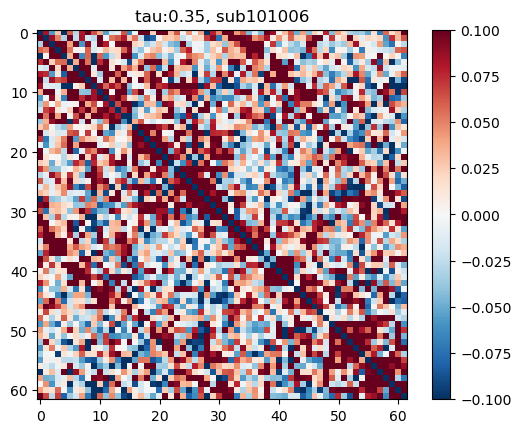

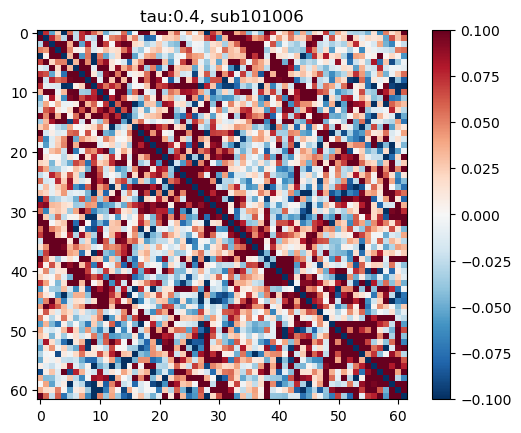

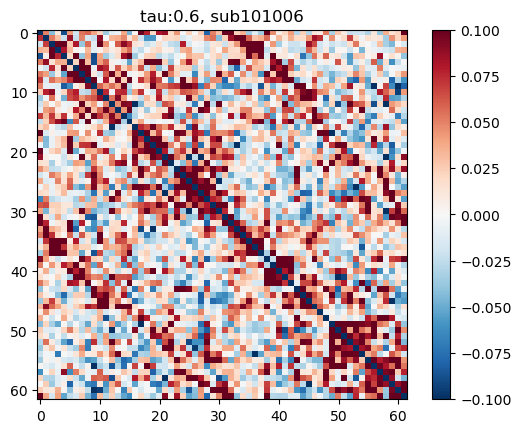

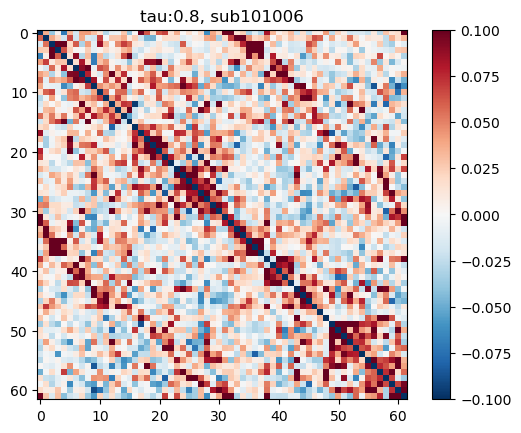

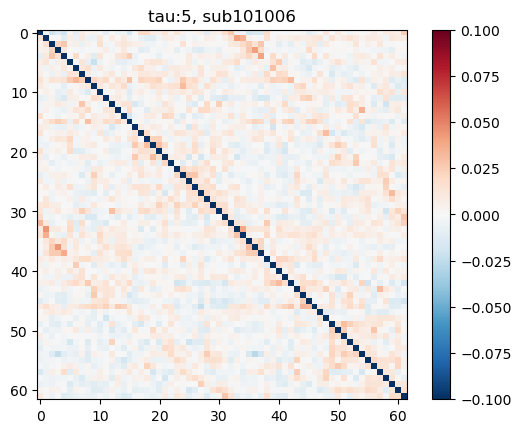

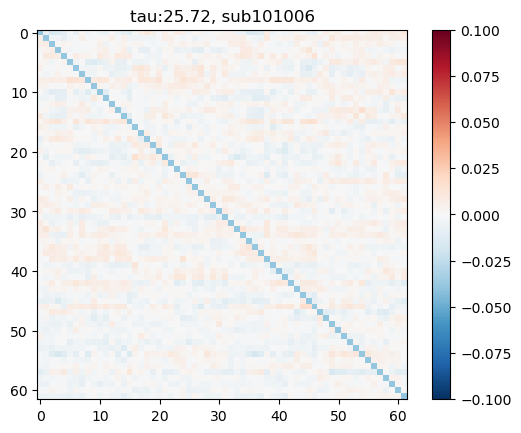

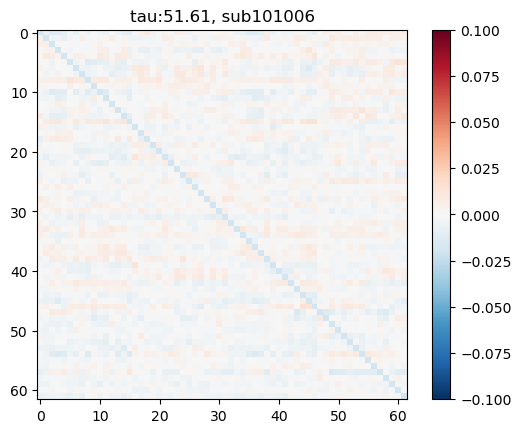

In [26]:
from scipy import signal

#corr=[[] for i in range(len(sub_tot))]
#corr_=[[] for i in range(len(sub_tot))]
js =[]
taus = [0.35,0.4,0.6,0.8,5,float(tau_obj_),float(tau_obj)]
MAX_ITER =100
for l, sub in enumerate(sub_tot[4:5]):
#(sub_tot[2:3]):
    for tau_ in taus:
        if os.path.exists(f'/home/benedetta/hcp_parcellated/{sub}/{sub}_REST1_LR_Schaefer100+AAL.npy'):
            if os.path.exists(f'/home/benedetta/hcp_parcellated/{sub}/{sub}_REST1_LR_Schaefer100+AAL.npy'):
                data_1 = np.load(f'/home/benedetta/hcp_parcellated/{sub}/{sub}_REST1_LR_Schaefer100+AAL.npy')
                b,a = signal.butter(2,[0.01,0.1],btype ='bandpass',fs = 1/0.72)
                data_ref=signal.filtfilt(b,a,data_1,axis = 0)
                Y = cluster_regions(data_ref[:,:100], aggregate[:100])
                #kkk
                m = MOU()
                Q0 = calc_Corr0(Y)
                Q1 = calc_Corrlag(Y,1)
            
                m.fit_LO(Q0,Q1,lag = 1,prior =0.,tau=float(tau_), eta_C=0.005, max_iter = MAX_ITER)
                J_prior = m.J;
                js.append(J_prior)
                if m.d_fit['iterations'] == MAX_ITER:
                    print(tau_, "", MAX_ITER, "iterations")
                
                #corr[l].append(np.corrcoef(dediag(J_prior).flatten(), dediag(np.linalg.inv(Q0)).flatten())[0,1])
                #corr_[l].append(np.corrcoef(dediag(J_prior).flatten(), dediag((Q0)).flatten())[0,1])
                plt.figure()
                plt.imshow(J_prior, cmap='RdBu_r', vmin=-.1,vmax=.1);
                print(np.sum(np.abs(J_prior -J_prior.T))/np.sum(np.abs(J_prior))/2)
                #print(
                plt.title(f'tau:{round(tau_,2)}, sub{sub}')
                plt.colorbar()

In [82]:
Y.shape

(1200, 62)

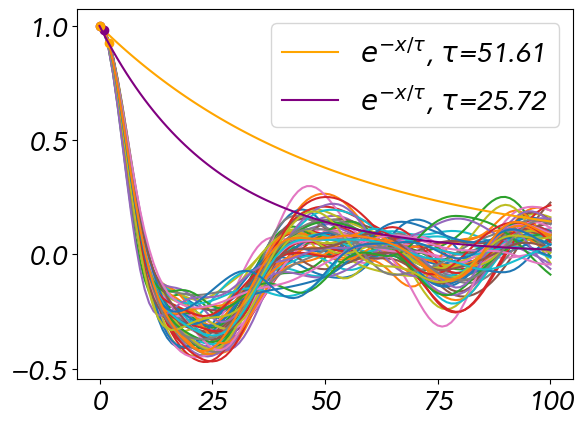

In [81]:
from statsmodels.tsa.stattools import acf, ccf
cc=[]
for i in range(Y.shape[1]):
    auto_corr = acf(Y[:,i], nlags=100, fft=True)
    cc.append(auto_corr) 
#auto_corr = acf(Y[:,10], nlags=100, fft=True)
cc=np.asarray(cc)
x=np.arange(0,len(auto_corr),1)
plt.plot(x, cc.T);
#plt.plot(x, np.exp(-x/tau_obj), color='red');

plt.plot(x, np.exp(-x/tau_obj), color='orange', label =r'$e^{-x/\tau}$, $\tau$='+ f'{round(tau_obj,2)}');

plt.plot([x[0], x[1]], [auto_corr[0],auto_corr[1]], 'o', color='purple')

plt.plot([x[0], x[2]], [auto_corr[0],auto_corr[2]], 'o', color='orange')

plt.plot(x, np.exp(-x/tau_obj_), color='purple', label =r'$e^{-x/\tau}$, $\tau$='+ f'{round(tau_obj_,2)}');
plt.legend()

In [80]:
np.logspace(-.35,2)[0]

np.float64(0.44668359215096315)

In [201]:
corr100= -corr100

In [26]:
vmin = min([np.percentile(dediag(js[i]), 1) for i in range(6)])
vmax = max([ np.percentile(dediag(js[i]), 90) for i in range(6)])
vmin, vmax

(np.float64(-0.046709757010153875), np.float64(0.053298483310358774))

In [83]:
from nilearn.datasets import fetch_atlas_schaefer_2018

N = 100  # Schaefer-100

# =========================
# 1. Carica Schaefer 100 (7 networks)
# =========================
atlas = fetch_atlas_schaefer_2018(
    n_rois=100,
    yeo_networks=7,
    resolution_mm=2
)
from sklearn.metrics import normalized_mutual_info_score

labels = atlas.labels  # lista di stringhe, lunghezza 100
labels = [lab.decode("utf-8") if isinstance(lab, bytes) else lab
          for lab in atlas.labels]
labels = np.asarray(labels)

In [78]:
labels100=[]
for i in labels:
    labels100.append(i[10:])

In [19]:
(ecs2)= np.asarray(ecs2)

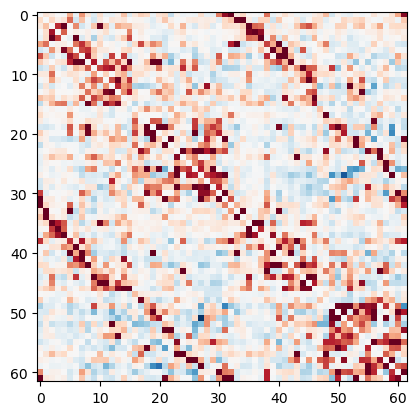

In [23]:
plt.imshow(dediag(np.mean(ecs2,0)), vmin=-.1,vmax=.1,cmap='RdBu_r');

In [83]:
plt.plot(corr

(100, 50)

Mapping: (100,) range = 1 - 62
(0, 2)
62
(0, 2)
62
(0, 2)
62
(0, 2)
62
(0, 2)
62
(0, 2)
62


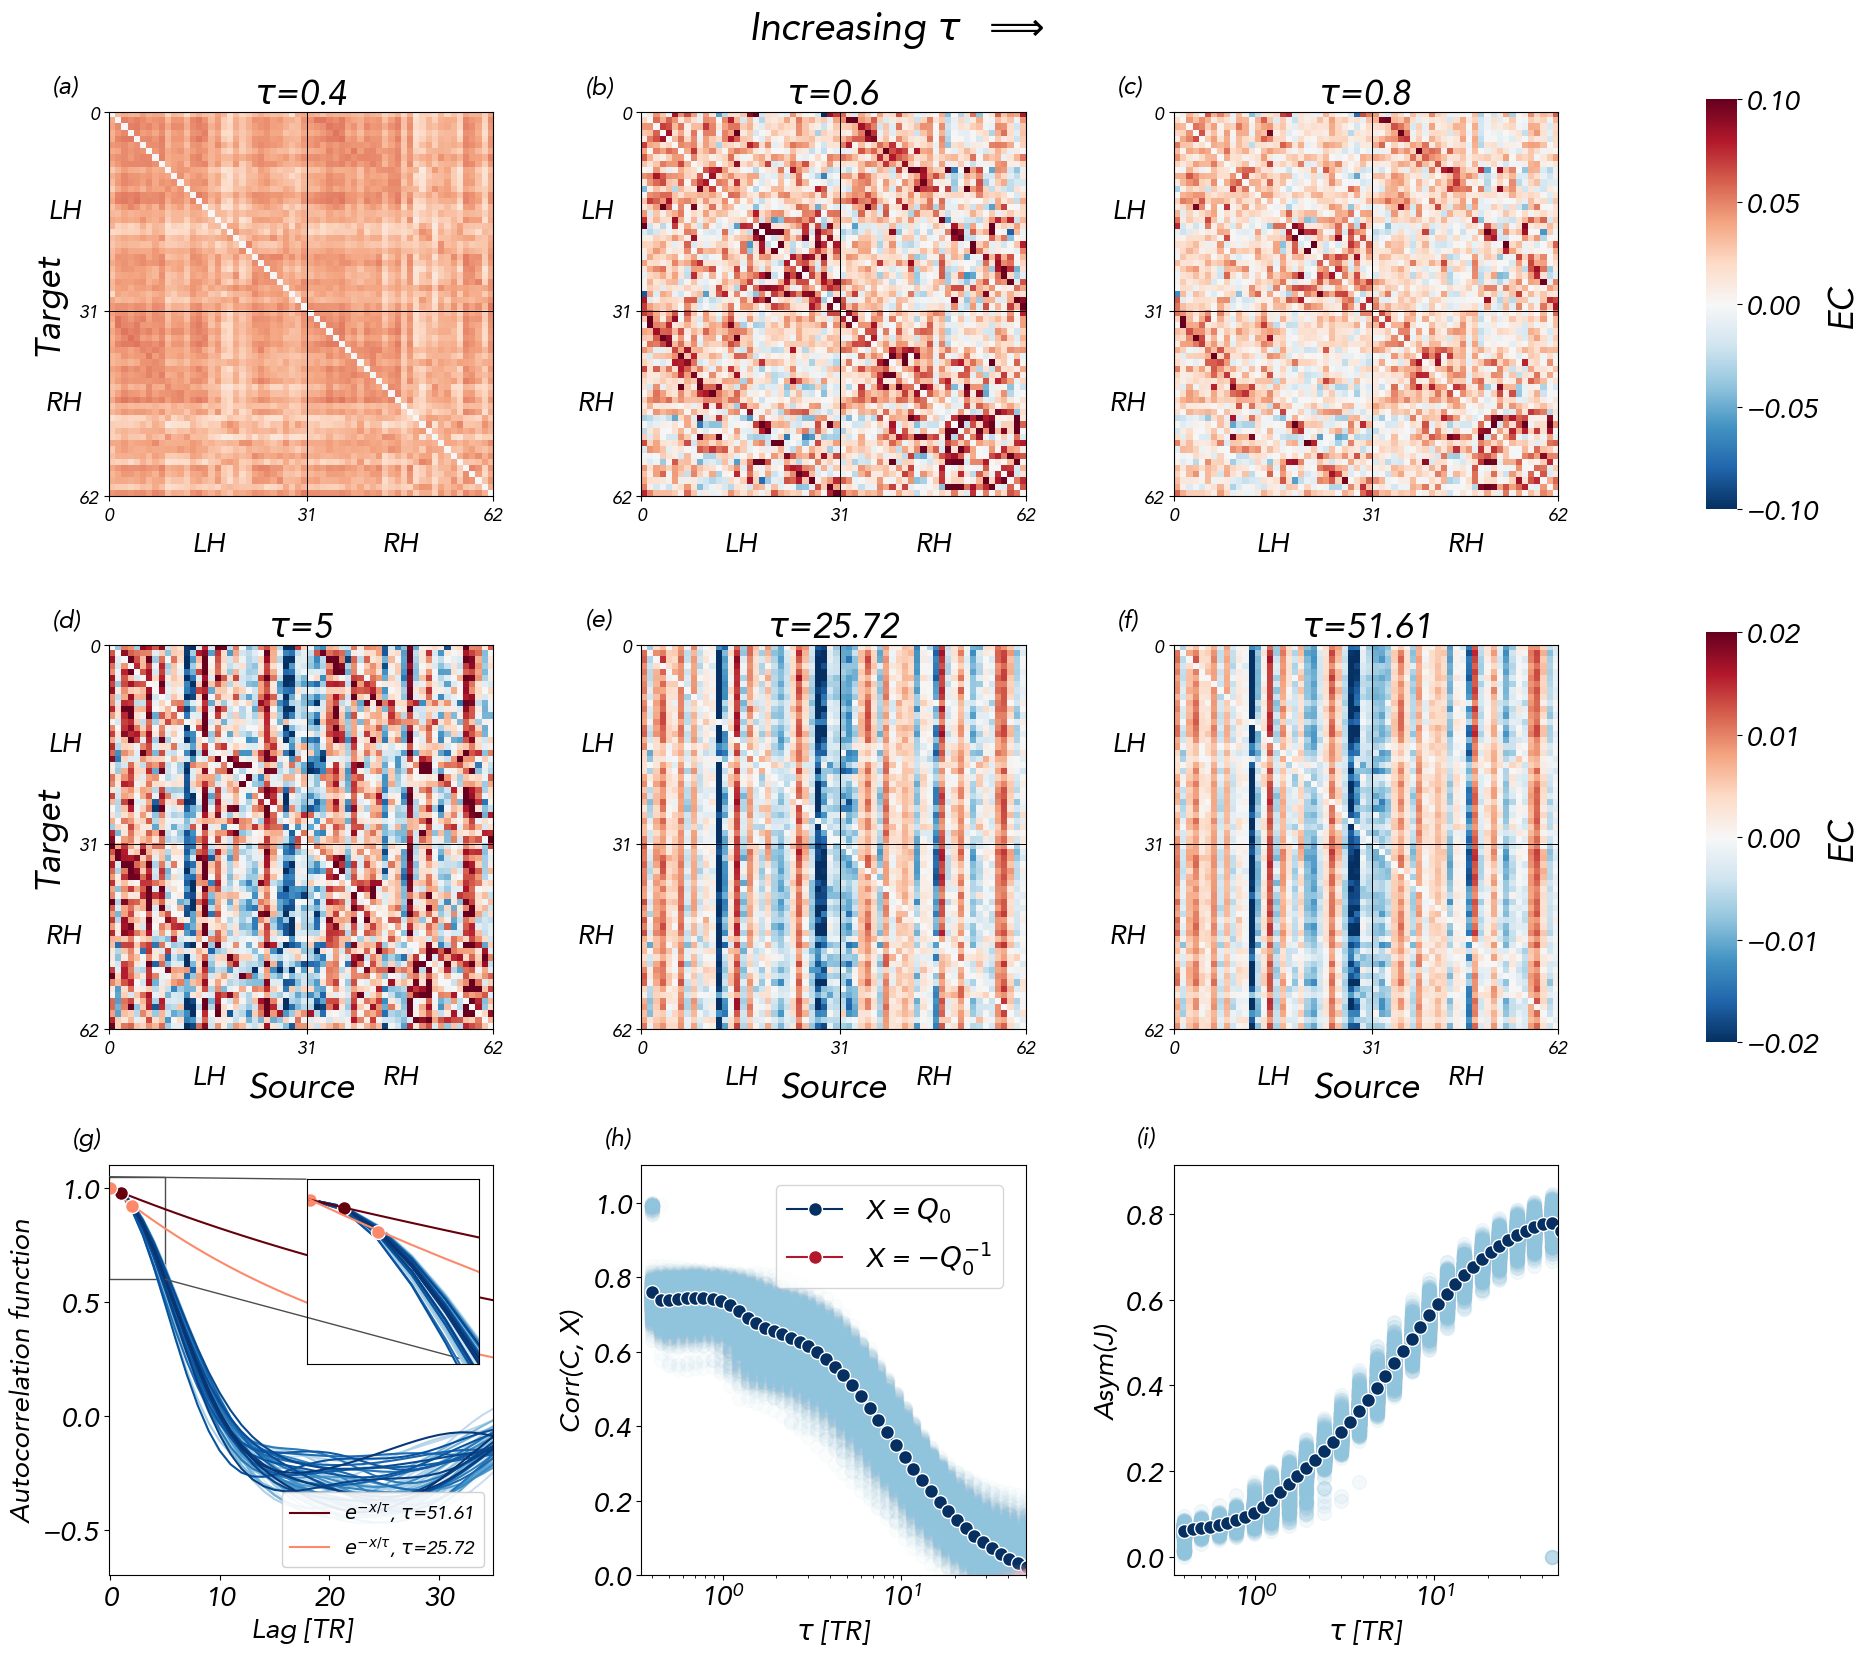

In [101]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from collections import OrderedDict
import numpy as np
import matplotlib.pyplot as plt
from collections import OrderedDict, Counter

# ============================================================
# MAPPING: SCHAEFER 100 -> 62 PARCELS
# ============================================================

mapping_100_to_62 = np.array([
     1,  2,  2,  2,  2,  2,  2,  2,  2,  3,
     3,  3,  4,  5,  5,  6,  7,  8,  7,  8,
     7,  9,  9, 10, 11, 12, 13, 14, 15, 16,
    17, 18, 19, 20, 21, 22, 23, 24, 24, 25,
    24, 26, 27, 28, 29, 28, 30, 31, 32, 32,
    33, 34, 34, 34, 35, 35, 34, 35, 36, 36,
    36, 37, 38, 38, 38, 38, 39, 40, 41, 41,
    42, 43, 43, 44, 45, 46, 47, 47, 48, 49,
    50, 51, 52, 52, 53, 52, 54, 55, 54, 56,
    57, 58, 58, 59, 59, 60, 60, 61, 62, 62
])

print("Mapping:", mapping_100_to_62.shape,
      "range =", mapping_100_to_62.min(), "-", mapping_100_to_62.max())


# ============================================================
# AGGREGATE FC: 100 x 100 -> 62 x 62
# ============================================================

def aggregate_fc(fc_100, mapping=mapping_100_to_62):

    fc_62 = np.full((62, 62), np.nan)

    for i in range(1, 63):
        ii = np.where(mapping == i)[0]

        for j in range(1, 63):
            jj = np.where(mapping == j)[0]

            fc_62[i-1, j-1] = np.nanmean(
                fc_100[np.ix_(ii, jj)]
            )

    return fc_62


# ============================================================
# AGGREGATE SCHAEFER LABELS: 100 -> 62
#
# Assumes labels like:
# LH_Vis_...
# LH_Default_...
# RH_Cont_...
# ============================================================

def aggregate_labels(labels_100, mapping=mapping_100_to_62):

    labels_100 = np.asarray(labels_100)
    labels_62 = []

    for k in range(1, 63):

        idx = np.where(mapping == k)[0]
        labs = labels_100[idx]

        hemis = [str(x).split("_")[0] for x in labs]
        nets  = [str(x).split("_")[1] for x in labs]

        # majority hemisphere/network
        hemi = Counter(hemis).most_common(1)[0][0]
        net  = Counter(nets).most_common(1)[0][0]

        labels_62.append(f"{hemi}_{net}_{k}")

    return np.array(labels_62)


# ============================================================
# PLOT
# ============================================================

def plot_fc_matrix(
    fc, labels, ax,
    cmap="bwr",
    vmin=-0.2,
    vmax=0.2,
    fontsize=13,
    pos=7,
    plot_networks=False,
    plot_emi_x=True,
    plot_emi_y=True
):

    labels = np.asarray(labels)

    def parse_label(lab):
        p = str(lab).split("_")
        return p[0], p[1]

    # group by hemisphere + network
    groups = OrderedDict()

    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        groups.setdefault(f"{hemi}_{net}", []).append(i)

    new_order = []
    bounds = []
    names = []

    start = 0

    for key, idxs in groups.items():
        new_order.extend(idxs)

        end = start + len(idxs)

        bounds.append((start, end))
        names.append(key)

        start = end

    # reorder
    fc_ord = fc[np.ix_(new_order, new_order)]
    labels_ord = labels[new_order]

    n = len(labels_ord)

    im = ax.imshow(
        fc_ord,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    # ------------------------------------------------------------
    # NETWORK BOUNDARIES
    # ------------------------------------------------------------
    #print(bounds[0])
    if plot_networks:

        for start, end in bounds:

            ax.axhline(end - .5, color="black", lw=.2)
            ax.axvline(end - .5, color="black", lw=.2)

        for (start, end), name in zip(bounds, names):
            #print(start)
            center = (start + end) / 2 - .5
            net = name.split("_", 1)[1]

            ax.text(
                center, n + 1, net,
                ha="center",
                va="top",
                rotation=70,
                fontsize=fontsize,
                clip_on=False
            )

            ax.text(
                -1, center, net,
                ha="right",
                va="center",
                fontsize=fontsize,
                clip_on=False
            )

    # ------------------------------------------------------------
    # LH / RH
    # ------------------------------------------------------------

    lh_count = np.sum([
        str(x).startswith("LH_")
        for x in labels_ord
    ])

    ax.axhline(lh_count - .5, color="black", lw=.7)
    ax.axvline(lh_count - .5, color="black", lw=.7)
    #print(lh_count)
    lh_center = lh_count / 2 - .5
    rh_center = lh_count + (n - lh_count) / 2 - .5

    if plot_emi_x:

        ax.text(
            lh_center, n + 1 + pos, "LH",
            ha="center", va="top",
            fontsize=20,
            fontweight="bold",
            clip_on=False
        )

        ax.text(
            rh_center, n + 1 + pos, "RH",
            ha="center", va="top",
            fontsize=20,
            fontweight="bold",
            clip_on=False
        )

    if plot_emi_y:

        ax.text(
            -1-pos, lh_center, "LH",
            ha="right", va="center",
            fontsize=20,
            fontweight="bold",
            clip_on=False
        )

        ax.text(
            -1-pos, rh_center, "RH",
            ha="right", va="center",
            fontsize=20,
            fontweight="bold",
            clip_on=False
        )

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_xlim(0, n-1)
    ax.set_ylim(n-1, 0)
    print(n)
    return im


# ============================================================
# USE
# ============================================================

# Le tue variabili:
# fc_100     -> matrice FC (100 x 100)
# labels_100 -> 100 Schaefer labels

#fc_62 = aggregate_fc(fc_100)
labels_62 = aggregate_labels(labels100)

#print("FC:", fc_100.shape, "->", fc_62.shape)
#print("Labels:", len(labels_100), "->", len(labels_62))
#print(labels_62)


# -----------------------
# STYLE
# -----------------------

vmin = min([np.percentile(js[i], 2) for i in range(6)])
vmax = max([ np.percentile(js[i], 98) for i in range(6)])


plt.rcParams['font.size'] = 20
fontsize = 25

cmap_div = cm.RdBu_r
cmap_blue = cm.Blues
colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))

# -----------------------
# FIGURE + GRID (WITH COLORBAR COLUMN)
# -----------------------
fig = plt.figure(figsize=(21, 18), constrained_layout=False)
fig.suptitle(
    r'Increasing $\tau$  $\Longrightarrow$',
    fontsize=28,
    fontweight='bold',
    y=0.98
)
gs = gridspec.GridSpec(
    3, 4,
    height_ratios=[1, 1, 1],
    width_ratios=[1, 1, 1,0.08],
    hspace=0.3,
    wspace=0.5
)

# -----------------------
# (a)-(f): MATRICES
# -----------------------
panel_labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']
taus = [0.4, 0.6, 0.8, 5, round(tau_obj_, 2), round(tau_obj, 2)]

axes_mat = []
ims = []

for i in range(6):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    axes_mat.append(ax)

    ax.text(-0.15, 1.05, panel_labels[i],
            transform=ax.transAxes,
            fontsize=18, fontweight='bold')

    if i % 3 == 0:
        ax.set_ylabel('Target', fontsize=fontsize,labelpad =10)
    if i // 3 == 1:
        ax.set_xlabel('Source', fontsize=fontsize,labelpad = 10)
    vmaxss=[0.1,0.1,0.1,0.02,0.02,0.02]

    im = plot_fc_matrix(dediag(js[i]).T,labels_62,ax,'RdBu_r',-vmaxss[i],vmaxss[i], plot_networks=False, pos=4)
    """
    im = ax.imshow(
        dediag(js[i]).T,
        cmap='RdBu_r',
        vmin=-vmaxss[i],
        #np.percentile(js[i], 98),
        vmax=vmaxss[i], # ànp.percentile(js[i], 98),
        aspect='equal'
    )
    """
    ims.append(im)
    ax.set_xticks([0-.5,31+.5,62-.5])
    ax.set_yticks([0-.5,31+.5,62-.5])
    ax.set_xticklabels([0,31,62], fontsize = 13)
    ax.set_yticklabels([0,31,62], fontsize = 13)
    

    ax.set_title(r'$\tau$=' + f'{taus[i]}', fontsize=fontsize)

# -----------------------
# GLOBAL COLORBAR (OUTSIDE GRID)
# -----------------------
cax = fig.add_subplot(gs[:1, 3])

cbar = fig.colorbar(ims[0], cax=cax)
cbar.set_label("EC", fontsize=fontsize)
cbar.outline.set_visible(False)



cax = fig.add_subplot(gs[1:2, 3])

cbar = fig.colorbar(ims[4], cax=cax)
cbar.set_label("EC", fontsize=fontsize)
cbar.outline.set_visible(False)
# -----------------------
# (g): AUTOCORRELATION
# -----------------------
ax0 = fig.add_subplot(gs[2, 0])

num_series = cc.shape[0]
x = np.arange(cc.shape[1])

for i in range(num_series):
    ax0.plot(x, cc[i, :], color=cmap_blue(i / num_series))

ax0.plot(x, np.exp(-x / tau_obj), color=kk[5],
         label=r'$e^{-x/\tau}$, $\tau$=' + f'{round(tau_obj,2)}')

ax0.plot(x, np.exp(-x / tau_obj_), color=kk[2],
         label=r'$e^{-x/\tau}$, $\tau$=' + f'{round(tau_obj_,2)}')

ax0.plot([x[0], x[1]], [cc[10, 0], cc[10, 1]],
         'o', color=kk[5], markersize=10, markeredgecolor='white')

ax0.plot([x[0], x[2]], [cc[10, 0], cc[10, 2]],
         'o', color=kk[2], markersize=10, markeredgecolor='white')

ax0.set_xlim(-0.1, 35)
ax0.set_ylim(-0.7, 1.1)
ax0.set_xlabel('Lag [TR]')
ax0.set_ylabel('Autocorrelation function')
ax0.text(-0.1, 1.05, '(g)', transform=ax0.transAxes,
         fontsize=18, fontweight='bold')

ax0.legend(fontsize=14, loc=(0.45, 0.02), framealpha=0.9)

# -----------------------
# INSET (ZOOM AUTOCORRELATION)
# -----------------------
axins = inset_axes(ax0, width="45%", height="45%", loc="upper right")

for i in range(num_series):
    axins.plot(x, cc[i, :], color=cmap_blue(i / num_series))
axins.plot([x[0], x[1]], [cc[10, 0], cc[10, 1]],
         'o', color=kk[5], markersize=10, markeredgecolor='white')

axins.plot([x[0], x[2]], [cc[10, 0], cc[10, 2]],
         'o', color=kk[2], markersize=10, markeredgecolor='white')

axins.plot(x, np.exp(-x / tau_obj), color=kk[5])
axins.plot(x, np.exp(-x / tau_obj_), color=kk[2])

axins.set_xlim(-0.1, 5)
axins.set_ylim(0.6, 1.05)

axins.set_xticks([])
axins.set_yticks([])

mark_inset(ax0, axins, loc1=2, loc2=4, fc="none", ec="0.3")
taus = np.round(np.logspace(-0.4, 2),2)

# -----------------------
# (h): CORRELATION C vs Q0
# -----------------------
#taus = np.arange(0.4, 1.5, 0.05)

ax2 = fig.add_subplot(gs[2, 1])

ax2.plot(taus[:], corr100_[:, :].T, 'o', markersize = 10, color=colors[3], alpha=0.03,)
ax2.plot(taus, np.nanmean(corr100_, 0), '-o', ms=10,
         color=colors[0], markeredgecolor='white', label = r"X = $Q_0$")

threshold = 0.95
high_tau, high_corr = [], []

for i, t in enumerate(taus[::2]):
    for c in corr100_[:, ::2][:, i]:
        if c >= threshold:
            high_tau.append(t)
            high_corr.append(c)

#ax2.scatter(high_tau, high_corr, s=200,
 #           facecolors='none', edgecolors=colors[0])

#ax2.set_xlim(0.2, 20)
ax2.set_xlabel(r'$\tau$ [TR]')
ax2.set_ylabel(r"Corr(C, X)")#, color=colors[0])
#ax2.tick_params(axis='y', labelcolor=colors[0])

ax2.text(-0.1, 1.05, '(h)', transform=ax2.transAxes,
         fontsize=18, fontweight='bold')

# -----------------------
# (i): ASYMMETRY
# -----------------------


# -----------------------
# SECONDARY AXIS (optional overlay)
# -----------------------
#ax_ = ax2.twinx()
ax_ = ax2
ax_.plot(taus[:], corr100[:, :].T, 'o', markersize = 10,color='pink', alpha=0.03)
ax_.plot(taus, np.nanmean(corr100, 0), '-o', ms=10,
          color=colors[9], markeredgecolor='white', label = r"X = $-Q_0^{-1}$")

ax_.set_ylabel(r'Corr(C, X)')#, color=colors[9])
#ax_.tick_params(axis='y', labelcolor=colors[9])
ax_.set_ylim(0., 1.1)

ax_.legend(loc = (0.35,0.7))

ax_.set_xlim(0.35,40)
ax_.set_xlim(0.35,50)

ax2.set_xscale('log')
ax_.set_xscale('log')


ax1 = fig.add_subplot(gs[2, 2])

ax1.plot(taus[::2], ass100[:, ::2].T, 'o', color=colors[3], alpha=0.1, markersize = 10)
ax1.plot(taus, np.mean(ass100, 0), '-o', ms=10,
         color=colors[0], markeredgecolor='white')

ax1.set_xscale('log')
ax1.set_xlabel(r'$\tau$ [TR]')
ax1.set_ylabel("Asym(J)")
ax1.text(-0.1, 1.05, '(i)', transform=ax1.transAxes,
         fontsize=18, fontweight='bold')
ax1.set_xlim(0.35, 49)
plt.subplots_adjust(top=0.93, hspace =.8)
#plt.savefig('Figure#s/figura1_revised.jpg', dpi = 300, bbox_inches ='tight');
#plt.tight_layout()

In [155]:
corr100=-corr100

Automatic sweet spot: 0.45 1.51
Plotted sweet spot: 0.45 1.51
Highlighted Q0 points at tau=0.45: 1
Highlighted precision points at tau=0.45: 1
Highlighted asymmetry points at tau=0.45: 83


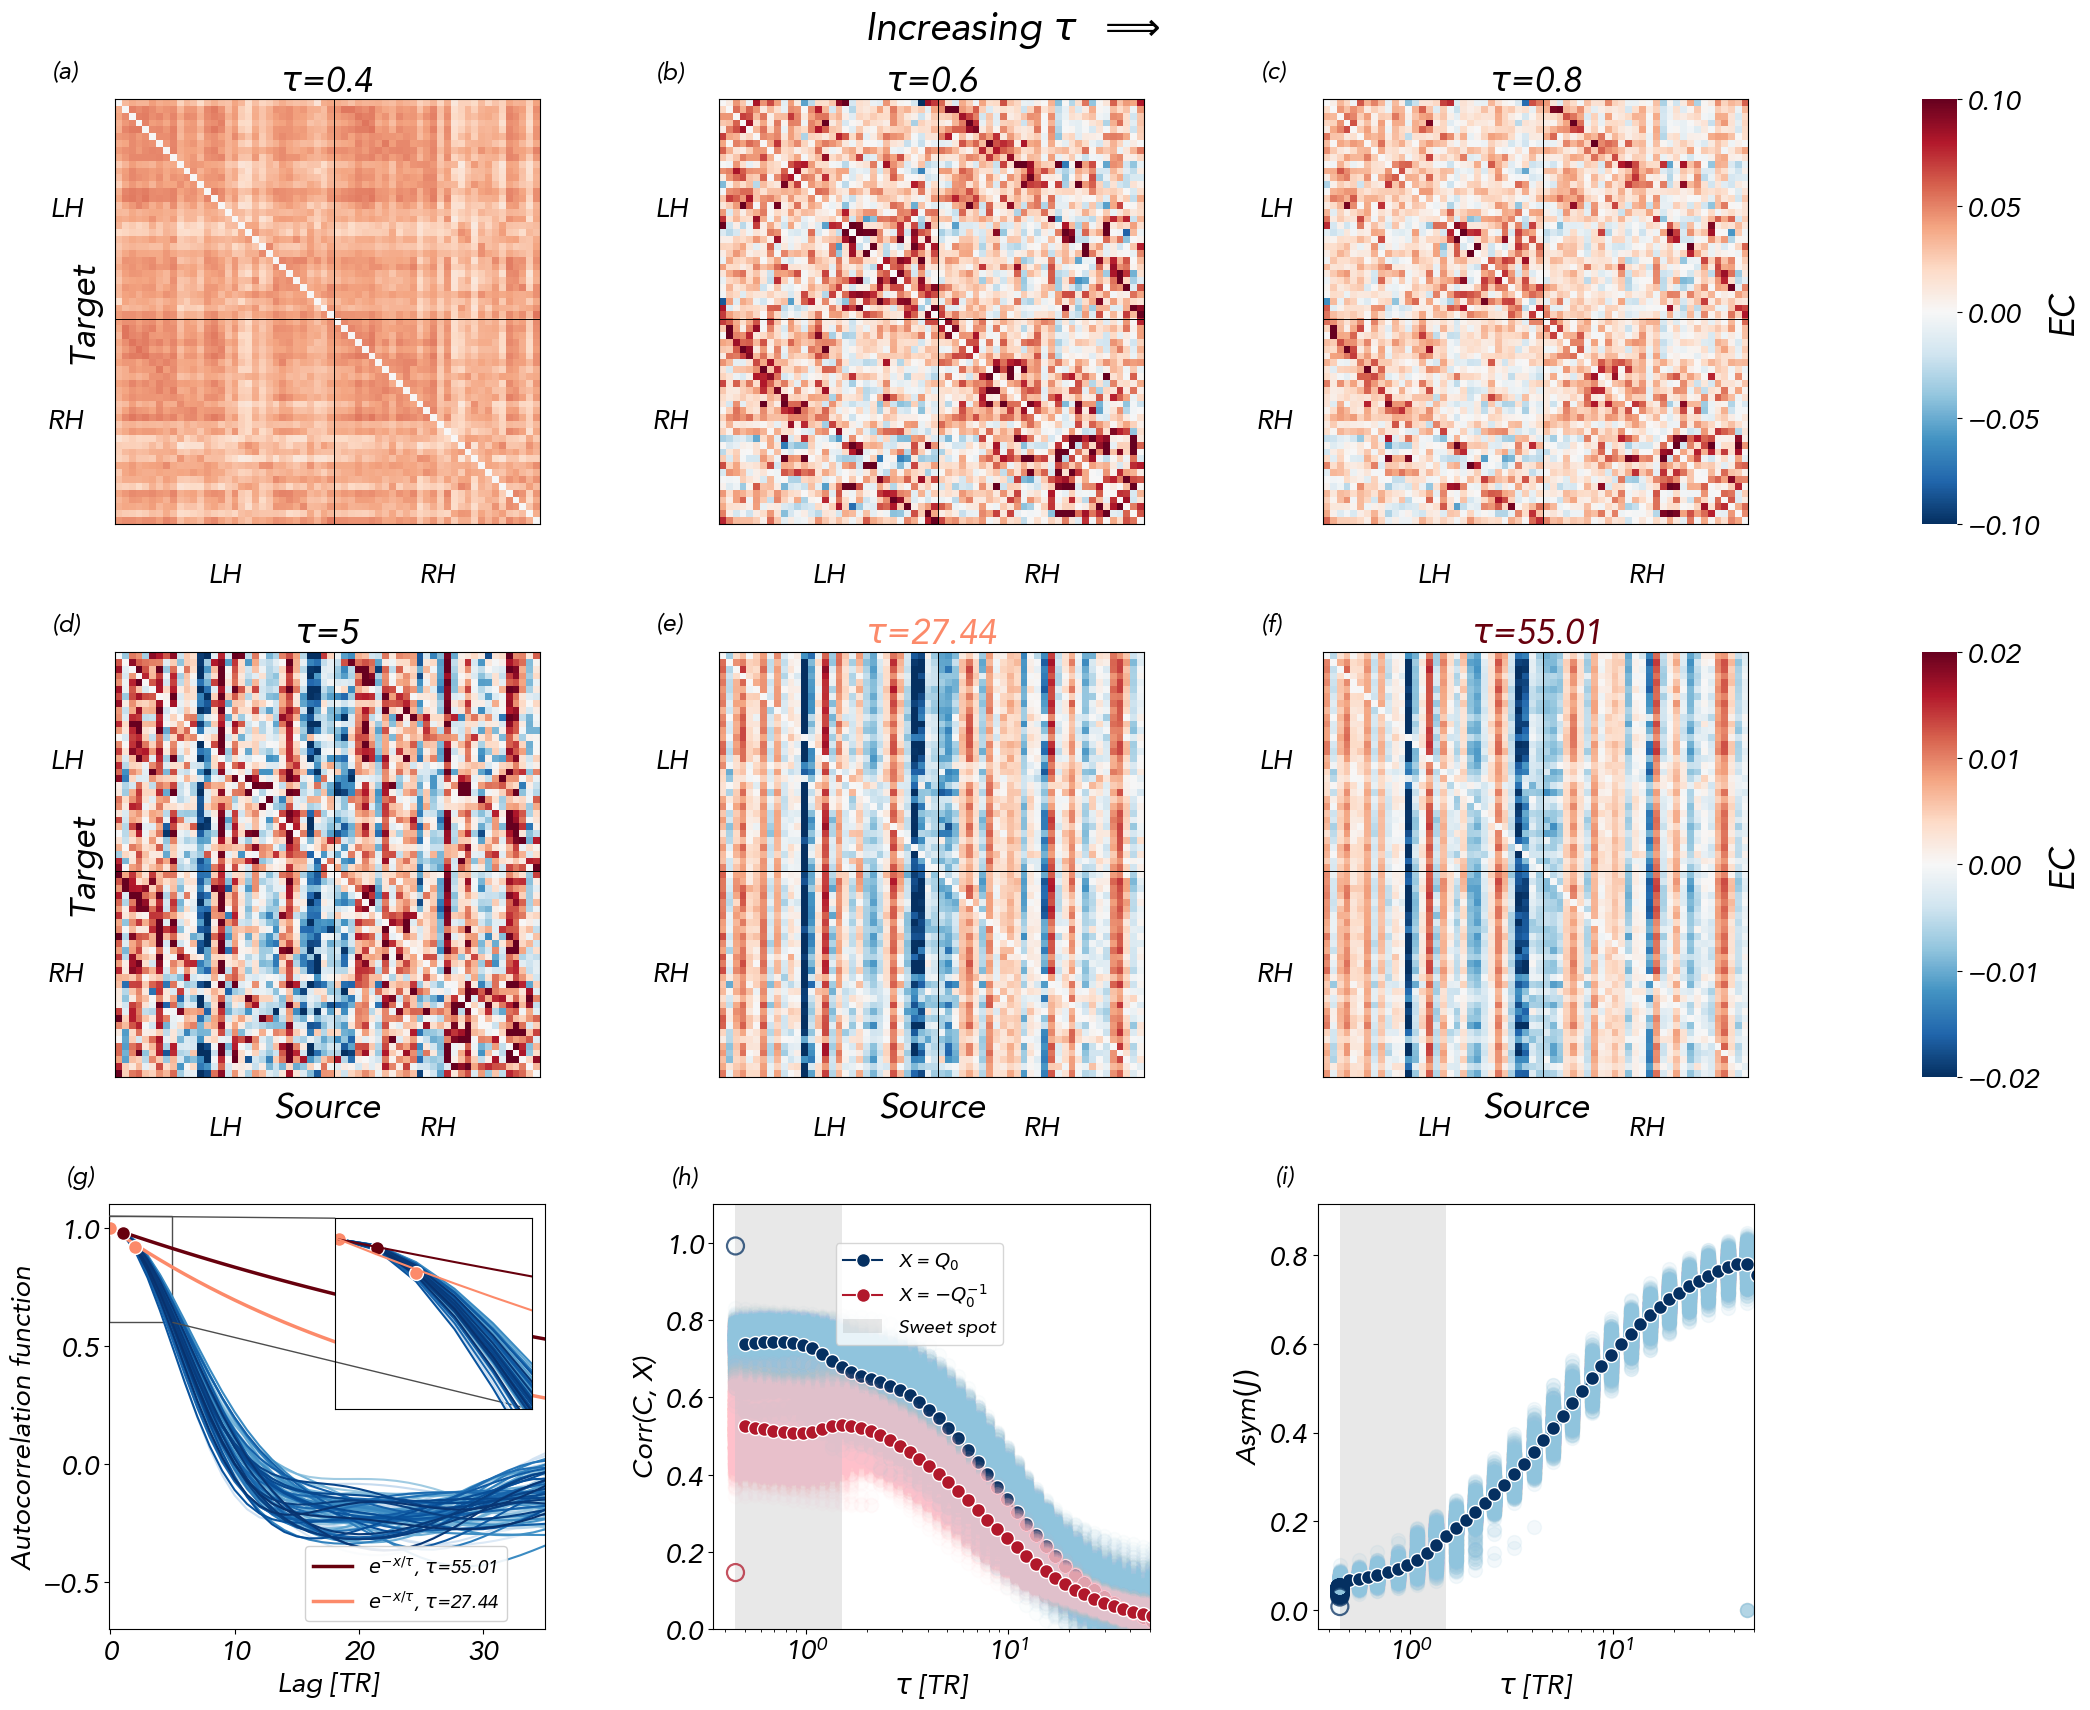

In [164]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset


# ==========================================================
# STYLE
# ==========================================================

vmin = min(np.percentile(js[i], 2) for i in range(6))
vmax = max(np.percentile(js[i], 98) for i in range(6))

plt.rcParams['font.size'] = 20
fontsize = 25

cmap_div = cm.RdBu_r
cmap_blue = cm.Blues

colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))


# ==========================================================
# THRESHOLDS FOR HIGHLIGHTING THE FIRST TAU POINT
# ==========================================================

q0_threshold = 0.85
precision_threshold = 0.25
asymmetry_threshold = 0.05

highlight_size = 150
highlight_linewidth = 1.6
highlight_alpha = 0.75


# ==========================================================
# FUNCTION TO IDENTIFY THE SWEET SPOT
# ==========================================================

def get_sweet_spot(
    taus,
    correlation,
    fraction_of_peak=0.5
):
    """
    Return the contiguous tau interval around the maximum correlation
    for which the curve remains above a specified fraction of its peak.
    """

    taus = np.asarray(taus, dtype=float)
    correlation = np.asarray(correlation, dtype=float)

    valid = np.isfinite(taus) & np.isfinite(correlation)

    taus_valid = taus[valid]
    corr_valid = correlation[valid]

    if len(taus_valid) == 0:
        return np.nan, np.nan

    peak_index = np.nanargmax(corr_valid)
    peak_value = corr_valid[peak_index]

    threshold = fraction_of_peak * peak_value

    high_mask = corr_valid >= threshold

    left_index = peak_index

    while left_index > 0 and high_mask[left_index - 1]:
        left_index -= 1

    right_index = peak_index

    while (
        right_index < len(corr_valid) - 1
        and high_mask[right_index + 1]
    ):
        right_index += 1

    return (
        taus_valid[left_index],
        taus_valid[right_index]
    )


# ==========================================================
# FIGURE + GRID
# ==========================================================

fig = plt.figure(
    figsize=(21, 18),
    constrained_layout=False
)

fig.suptitle(
    r'Increasing $\tau$  $\Longrightarrow$',
    fontsize=28,
    fontweight='bold',
    y=0.98
)

gs = gridspec.GridSpec(
    3,
    4,
    height_ratios=[1, 1, 1],
    width_ratios=[1, 1, 1, 0.08],
    hspace=0.30,
    wspace=0.50
)


# ==========================================================
# (a)-(f): EC MATRICES
# ==========================================================

panel_labels = [
    '(a)', '(b)', '(c)',
    '(d)', '(e)', '(f)'
]

matrix_taus = [
    0.4,
    0.6,
    0.8,
    5,
    round(tau_obj_, 2),
    round(tau_obj, 2)
]

axes_mat = []
ims = []

vmaxss = [
    0.1,
    0.1,
    0.1,
    0.02,
    0.02,
    0.02
]

for i in range(6):

    ax = fig.add_subplot(
        gs[i // 3, i % 3]
    )

    axes_mat.append(ax)

    ax.text(
        -0.15,
        1.05,
        panel_labels[i],
        transform=ax.transAxes,
        fontsize=18,
        fontweight='bold'
    )

    if i % 3 == 0:
        ax.set_ylabel(
            'Target',
            fontsize=fontsize,
            labelpad=10
        )

    if i // 3 == 1:
        ax.set_xlabel(
            'Source',
            fontsize=fontsize,
            labelpad=10
        )

    im = plot_fc_matrix(
        dediag(js[i]).T,
        labels_62,
        ax,
        'RdBu_r',
        -vmaxss[i],
        vmaxss[i],
        plot_networks=False,
        pos=4
    )

    ims.append(im)

    #ax.set_xticks([0, 50, 100])
    #ax.set_yticks([0, 50, 100])

  #  ax.set_xticklabels(
   #     [0, 50, 100],
   #     fontsize=13
   # )

    #ax.set_yticklabels(
    #    [0, 50, 100],
    #    fontsize=13
    #)

    title_color = 'black'

    # Panel (e): same color as tau_obj_ in panel (g)
    if i == 4:
        title_color = kk[2]

    # Panel (f): same color as tau_obj in panel (g)
    elif i == 5:
        title_color = kk[5]

    ax.set_title(
        r'$\tau$=' + f'{matrix_taus[i]}',
        fontsize=fontsize,
        color=title_color,
        fontweight='bold' if i in [4, 5] else 'normal'
    )


# ==========================================================
# COLORBARS
# ==========================================================

cax_top = fig.add_subplot(
    gs[:1, 3]
)

cbar_top = fig.colorbar(
    ims[0],
    cax=cax_top
)

cbar_top.set_label(
    "EC",
    fontsize=fontsize
)

cbar_top.outline.set_visible(False)


cax_middle = fig.add_subplot(
    gs[1:2, 3]
)

cbar_middle = fig.colorbar(
    ims[4],
    cax=cax_middle
)

cbar_middle.set_label(
    "EC",
    fontsize=fontsize
)

cbar_middle.outline.set_visible(False)


# ==========================================================
# (g): AUTOCORRELATION
# ==========================================================

ax0 = fig.add_subplot(
    gs[2, 0]
)

num_series = cc.shape[0]
x = np.arange(cc.shape[1])

for i in range(num_series):

    ax0.plot(
        x,
        cc[i, :],
        color=cmap_blue(i / num_series)
    )


ax0.plot(
    x,
    np.exp(-x / tau_obj),
    color=kk[5],
    linewidth=2.5,
    label=(
        r'$e^{-x/\tau}$, $\tau$='
        + f'{round(tau_obj, 2)}'
    )
)

ax0.plot(
    x,
    np.exp(-x / tau_obj_),
    color=kk[2],
    linewidth=2.5,
    label=(
        r'$e^{-x/\tau}$, $\tau$='
        + f'{round(tau_obj_, 2)}'
    )
)

ax0.plot(
    [x[0], x[1]],
    [cc[10, 0], cc[10, 1]],
    'o',
    color=kk[5],
    markersize=10,
    markeredgecolor='white'
)

ax0.plot(
    [x[0], x[2]],
    [cc[10, 0], cc[10, 2]],
    'o',
    color=kk[2],
    markersize=10,
    markeredgecolor='white'
)

ax0.set_xlim(-0.1, 35)
ax0.set_ylim(-0.7, 1.1)

ax0.set_xlabel('Lag [TR]')
ax0.set_ylabel('Autocorrelation function')

ax0.text(
    -0.1,
    1.05,
    '(g)',
    transform=ax0.transAxes,
    fontsize=18,
    fontweight='bold'
)

ax0.legend(
    fontsize=14,
    loc=(0.45, 0.02),
    framealpha=0.9
)


# ==========================================================
# INSET: AUTOCORRELATION ZOOM
# ==========================================================

axins = inset_axes(
    ax0,
    width="45%",
    height="45%",
    loc="upper right"
)

for i in range(num_series):

    axins.plot(
        x,
        cc[i, :],
        color=cmap_blue(i / num_series)
    )

axins.plot(
    [x[0], x[1]],
    [cc[10, 0], cc[10, 1]],
    'o',
    color=kk[5],
    markersize=10,
    markeredgecolor='white'
)

axins.plot(
    [x[0], x[2]],
    [cc[10, 0], cc[10, 2]],
    'o',
    color=kk[2],
    markersize=10,
    markeredgecolor='white'
)

axins.plot(
    x,
    np.exp(-x / tau_obj),
    color=kk[5]
)

axins.plot(
    x,
    np.exp(-x / tau_obj_),
    color=kk[2]
)

axins.set_xlim(-0.1, 5)
axins.set_ylim(0.6, 1.05)

axins.set_xticks([])
axins.set_yticks([])

mark_inset(
    ax0,
    axins,
    loc1=2,
    loc2=4,
    fc="none",
    ec="0.3"
)


# ==========================================================
# TAU VALUES FOR PANELS (h) AND (i)
# ==========================================================

taus = np.round(
    np.logspace(
        -0.35,
        2,
        corr100_.shape[1]
    ),
    2
)


# ==========================================================
# MEAN CURVES
# ==========================================================

mean_corr_q0 = np.nanmean(
    corr100_,
    axis=0
)

mean_corr_precision = np.nanmean(
    corr100,
    axis=0
)

mean_asymmetry = np.nanmean(
    ass100,
    axis=0
)


# ==========================================================
# SWEET-SPOT INTERVAL
# ==========================================================

sweet_tau_left, sweet_tau_right = get_sweet_spot(
    taus[:],
    mean_corr_q0[:],
    fraction_of_peak=0.90
)

print(
    "Automatic sweet spot:",
    sweet_tau_left,
    sweet_tau_right
)

# Manual lower boundary
#sweet_tau_left = 0.42

print(
    "Plotted sweet spot:",
    sweet_tau_left,
    sweet_tau_right
)


# ==========================================================
# MASKS FOR FIRST-TAU HIGHLIGHTED POINTS
# ==========================================================

first_q0_values = corr100_[:, 0]
first_precision_values = corr100[:, 0]
first_asymmetry_values = ass100[:, 0]

# Q0: highlight only correlations greater than 0.85
mask_q0_first = (
    np.isfinite(first_q0_values)
    & (first_q0_values > q0_threshold)
)

# Precision: highlight only correlations lower than 0.10
mask_precision_first = (
    np.isfinite(first_precision_values)
    & (first_precision_values < precision_threshold)
)

# Asymmetry: highlight only values lower than 0.10
mask_asymmetry_first = (
    np.isfinite(first_asymmetry_values)
    & (first_asymmetry_values < asymmetry_threshold)
)

print(
    f"Highlighted Q0 points at tau={taus[0]}:",
    np.sum(mask_q0_first)
)

print(
    f"Highlighted precision points at tau={taus[0]}:",
    np.sum(mask_precision_first)
)

print(
    f"Highlighted asymmetry points at tau={taus[0]}:",
    np.sum(mask_asymmetry_first)
)


# ==========================================================
# (h): CORRELATION WITH Q0 AND -Q0^-1
# ==========================================================

ax2 = fig.add_subplot(
    gs[2, 1]
)


# ----------------------------------------------------------
# Individual values: correlation with Q0
# ----------------------------------------------------------

ax2.plot(
    taus,
    corr100_.T,
    'o',
    markersize=10,
    color=colors[3],
    alpha=0.03
)


# Highlight only first-tau Q0 correlations > 0.85
ax2.scatter(
    np.full(
        np.sum(mask_q0_first),
        taus[0]
    ),
    first_q0_values[mask_q0_first],
    s=highlight_size,
    facecolors='none',
    edgecolors=colors[0],
    linewidths=highlight_linewidth,
    alpha=highlight_alpha,
    zorder=6
)


# Mean curve, excluding the trivial first point
ax2.plot(
    taus[1:],
    mean_corr_q0[1:],
    '-o',
    ms=10,
    color=colors[0],
    markeredgecolor='white',
    label=r"X = $Q_0$"
)


# ----------------------------------------------------------
# Individual values: correlation with -Q0^-1
# ----------------------------------------------------------

ax2.plot(
    taus,
    corr100.T,
    'o',
    markersize=10,
    color='pink',
    alpha=0.03
)


# Highlight only first-tau precision correlations < 0.10
ax2.scatter(
    np.full(
        np.sum(mask_precision_first),
        taus[0]
    ),
    first_precision_values[mask_precision_first],
    s=highlight_size,
    facecolors='none',
    edgecolors=colors[9],
    linewidths=highlight_linewidth,
    alpha=highlight_alpha,
    zorder=6
)


# Mean curve, excluding the trivial first point
ax2.plot(
    taus[1:],
    mean_corr_precision[1:],
    '-o',
    ms=10,
    color=colors[9],
    markeredgecolor='white',
    label=r"X = $-Q_0^{-1}$"
)


# Sweet-spot shaded region
ax2.axvspan(
    sweet_tau_left,
    sweet_tau_right,
    color='grey',
    alpha=0.18,
    linewidth=0,
    label='Sweet spot'
)


ax2.set_xlabel(r'$\tau$ [TR]')
ax2.set_ylabel(r'Corr(C, X)')

ax2.set_ylim(0.0, 1.1)
ax2.set_xlim(0.35, 50)
ax2.set_xscale('log')

ax2.text(
    -0.1,
    1.05,
    '(h)',
    transform=ax2.transAxes,
    fontsize=18,
    fontweight='bold'
)

ax2.legend(
    loc=(0.28, 0.67),
    fontsize=14
)


# ==========================================================
# (i): ASYMMETRY
# ==========================================================

ax1 = fig.add_subplot(
    gs[2, 2]
)


# Individual asymmetry values
ax1.plot(
    taus[::2],
    ass100[:, ::2].T,
    'o',
    color=colors[3],
    alpha=0.10,
    markersize=10
)


# Highlight only first-tau asymmetry values < 0.10
ax1.scatter(
    np.full(
        np.sum(mask_asymmetry_first),
        taus[0]
    ),
    first_asymmetry_values[mask_asymmetry_first],
    s=highlight_size,
    facecolors='none',
    edgecolors=colors[0],
    linewidths=highlight_linewidth,
    alpha=highlight_alpha,
    zorder=6
)


# Mean curve, excluding the trivial first point
ax1.plot(
    taus[1:],
    mean_asymmetry[1:],
    '-o',
    ms=10,
    color=colors[0],
    markeredgecolor='white'
)


# Same sweet-spot shaded region
ax1.axvspan(
    sweet_tau_left,
    sweet_tau_right,
    color='grey',
    alpha=0.18,
    linewidth=0
)


ax1.set_xscale('log')

ax1.set_xlabel(r'$\tau$ [TR]')
ax1.set_ylabel(r'Asym$(J)$')

ax1.set_xlim(0.35, 50)

ax1.text(
    -0.1,
    1.05,
    '(i)',
    transform=ax1.transAxes,
    fontsize=18,
    fontweight='bold'
)


# ==========================================================
# FINAL LAYOUT
# ==========================================================

plt.subplots_adjust(
    top=0.93,
    bottom=0.08,
    left=0.07,
    right=0.95
)

plt.show()

In [30]:
10**-.35

0.44668359215096315

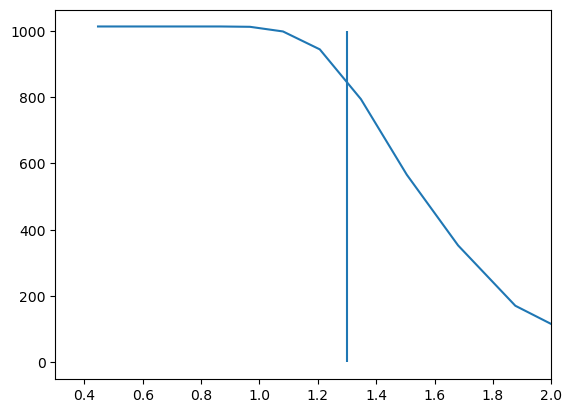

In [38]:
tau_ = np.logspace(-.35,2,)
p = np.load('../numpy files/converged.npy')
plt.plot(tau_,np.sum(p,0))
plt.xlim(0.3,2);
plt.vlines(1.3,0,1000);

Sweet spot: 0.4 0.88


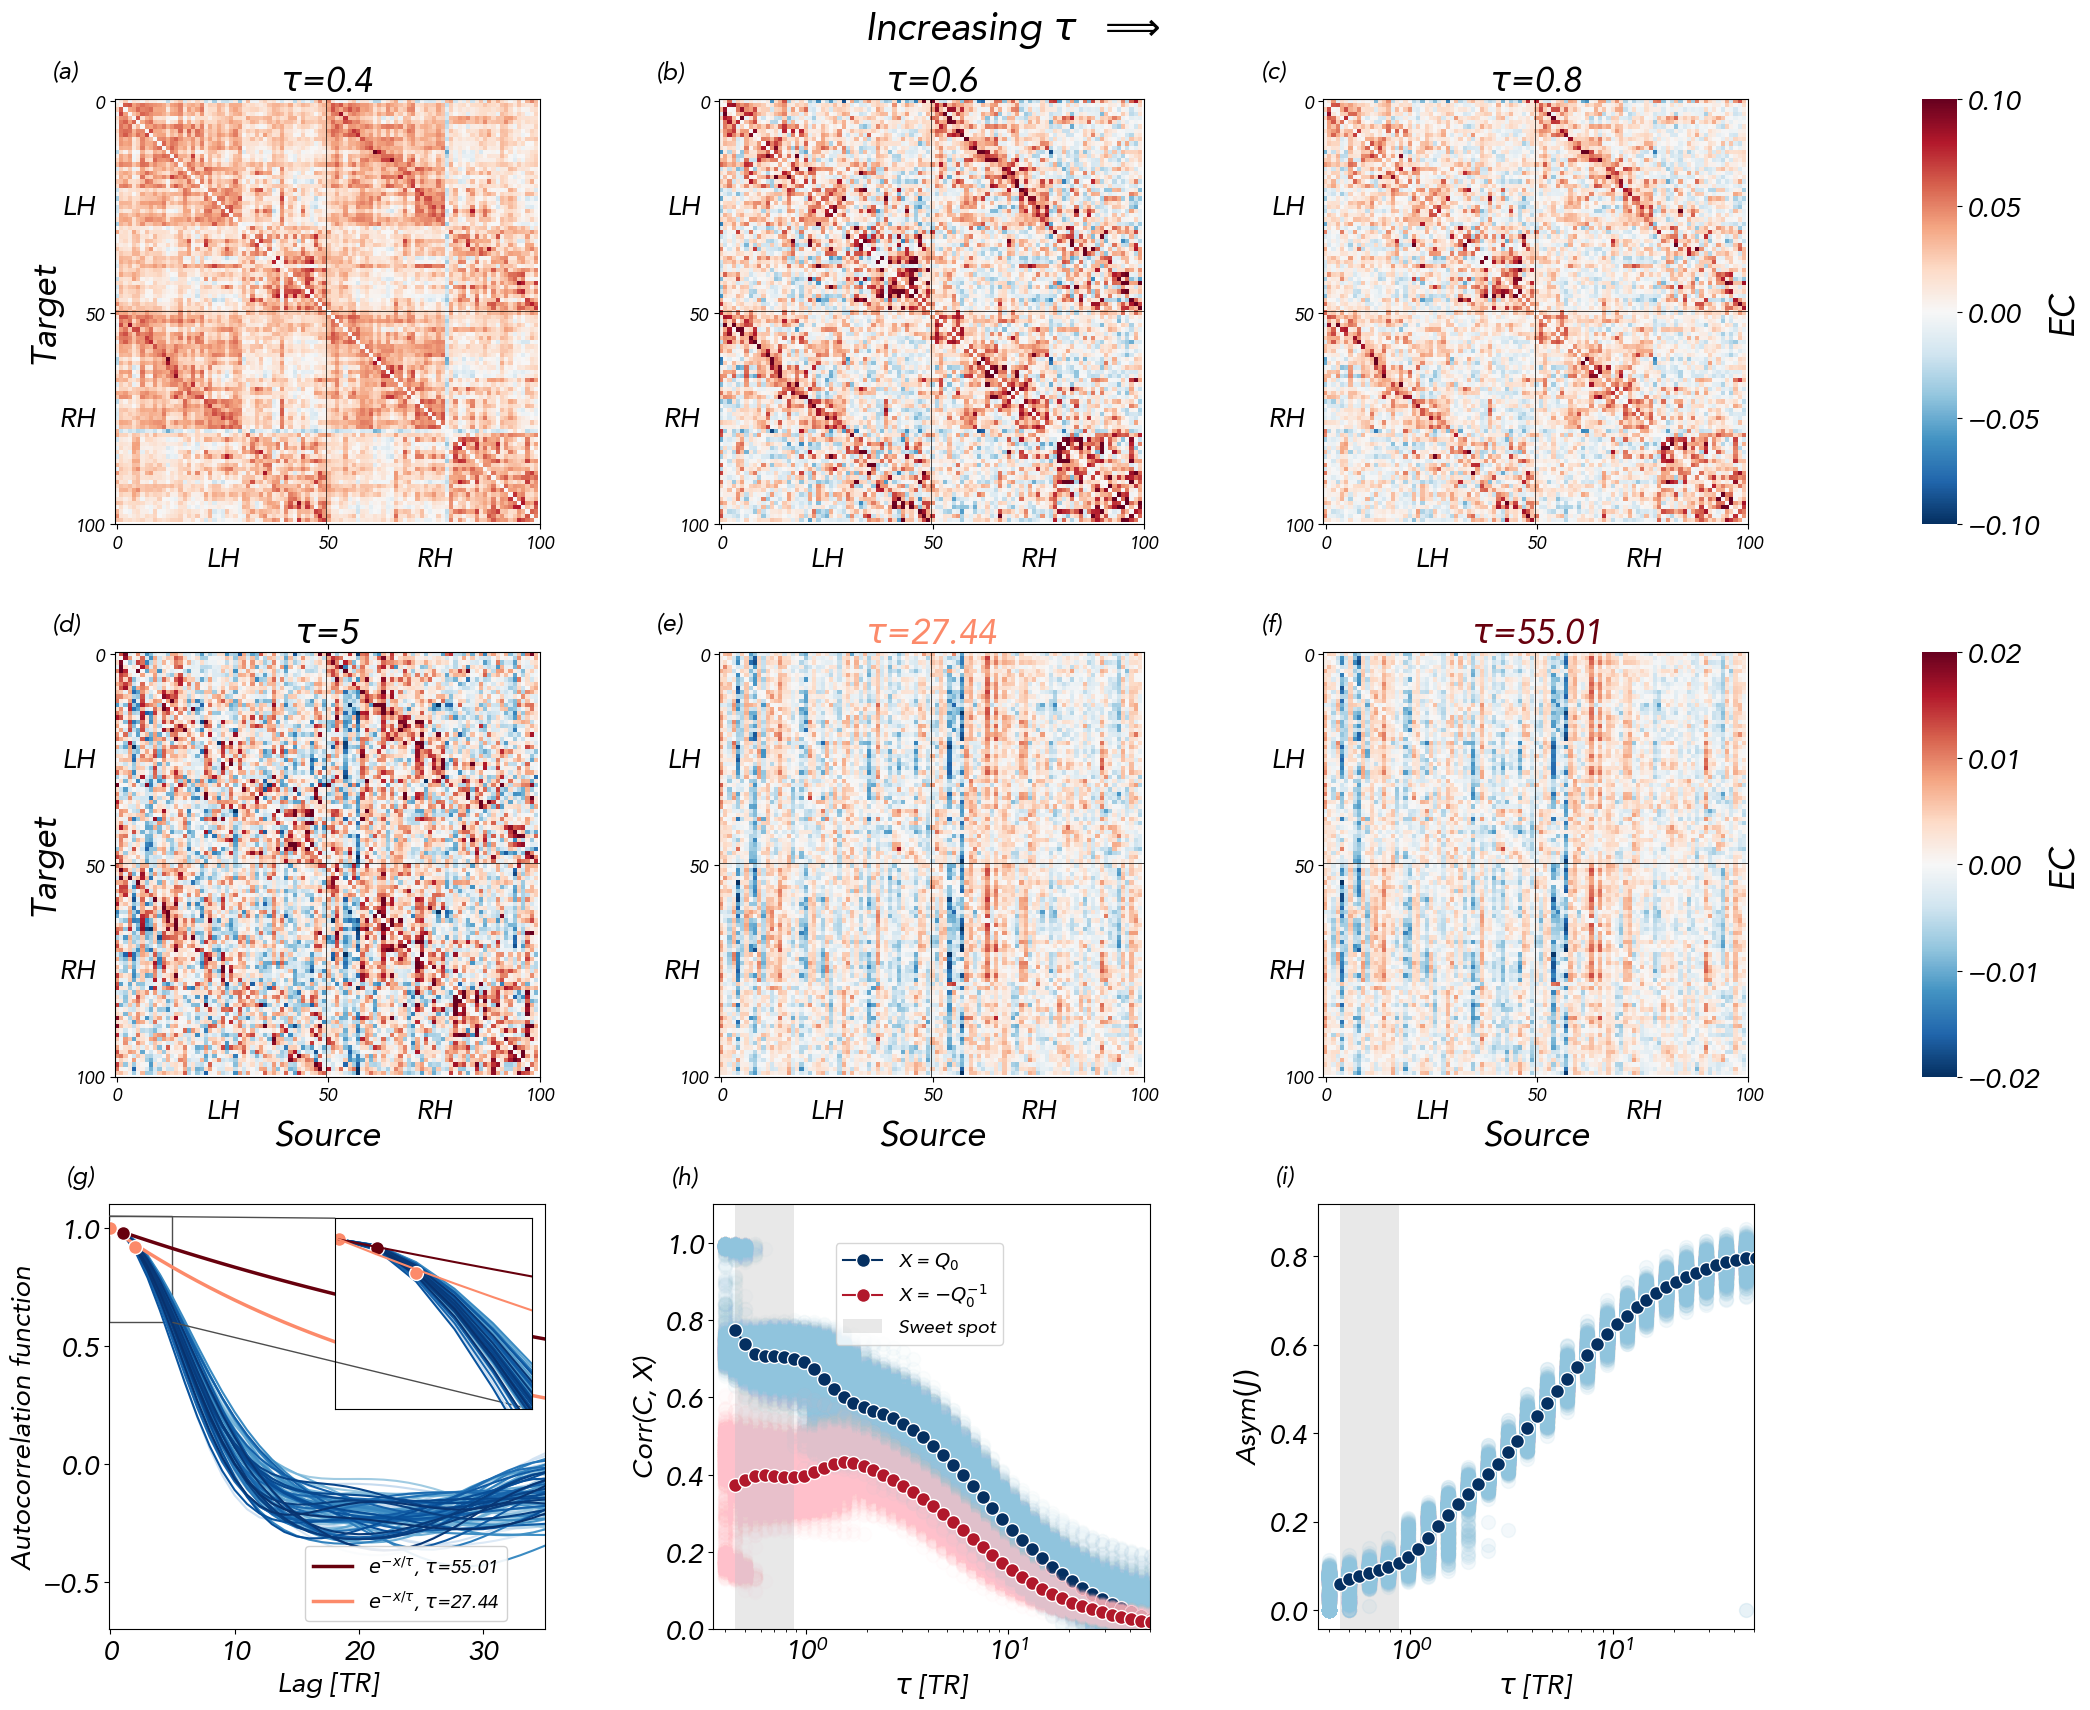

In [203]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset


# ==========================================================
# STYLE
# ==========================================================

vmin = min(np.percentile(js[i], 2) for i in range(6))
vmax = max(np.percentile(js[i], 98) for i in range(6))

plt.rcParams['font.size'] = 20
fontsize = 25

cmap_div = cm.RdBu_r
cmap_blue = cm.Blues

colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))


# ==========================================================
# FUNCTION TO IDENTIFY THE SWEET SPOT
# ==========================================================

def get_sweet_spot(
    taus,
    correlation,
    fraction_of_peak=0.5
):
    """
    Return the contiguous tau interval around the maximum correlation
    for which the curve remains above a specified fraction of its peak.

    Parameters
    ----------
    taus : array-like
        Tau values.

    correlation : array-like
        Mean correlation curve.

    fraction_of_peak : float
        Fraction of the maximum correlation used to define the
        high-correlation region.

    Returns
    -------
    tau_left, tau_right : float
        Boundaries of the sweet-spot interval.
    """

    taus = np.asarray(taus, dtype=float)
    correlation = np.asarray(correlation, dtype=float)

    valid = np.isfinite(taus) & np.isfinite(correlation)

    taus_valid = taus[valid]
    corr_valid = correlation[valid]

    if len(taus_valid) == 0:
        return np.nan, np.nan

    peak_index = np.nanargmax(corr_valid)#[::-1]
    #print(corr_valid[peak_index[0]],corr_valid[peak_index[1]])
    peak_value = corr_valid[peak_index]

    threshold = fraction_of_peak * peak_value

    high_mask = corr_valid >= threshold

    left_index = peak_index
    while left_index > 0 and high_mask[left_index - 1]:
        left_index -= 1

    right_index = peak_index
    while (
        right_index < len(corr_valid) - 1
        and high_mask[right_index + 1]
    ):
        right_index += 1

    return (
        taus_valid[left_index],
        taus_valid[right_index]
    )


# ==========================================================
# FIGURE + GRID
# ==========================================================

fig = plt.figure(
    figsize=(21, 18),
    constrained_layout=False
)

fig.suptitle(
    r'Increasing $\tau$  $\Longrightarrow$',
    fontsize=28,
    fontweight='bold',
    y=0.98
)

gs = gridspec.GridSpec(
    3,
    4,
    height_ratios=[1, 1, 1],
    width_ratios=[1, 1, 1, 0.08],
    hspace=0.30,
    wspace=0.50
)


# ==========================================================
# (a)-(f): EC MATRICES
# ==========================================================

panel_labels = [
    '(a)', '(b)', '(c)',
    '(d)', '(e)', '(f)'
]

matrix_taus = [
    0.4,
    0.6,
    0.8,
    5,
    round(tau_obj_, 2),
    round(tau_obj, 2)
]

axes_mat = []
ims = []

vmaxss = [
    0.1,
    0.1,
    0.1,
    0.02,
    0.02,
    0.02
]

for i in range(6):

    ax = fig.add_subplot(
        gs[i // 3, i % 3]
    )

    axes_mat.append(ax)

    ax.text(
        -0.15,
        1.05,
        panel_labels[i],
        transform=ax.transAxes,
        fontsize=18,
        fontweight='bold'
    )

    if i % 3 == 0:
        ax.set_ylabel(
            'Target',
            fontsize=fontsize,
            labelpad=10
        )

    if i // 3 == 1:
        ax.set_xlabel(
            'Source',
            fontsize=fontsize,
            labelpad=10
        )

    im = plot_fc_matrix(
        dediag(js[i]).T,
        labels100,
        ax,
        'RdBu_r',
        -vmaxss[i],
        vmaxss[i],
        plot_networks=False,
        pos=4
    )

    ims.append(im)

    ax.set_xticks([0, 50, 100])
    ax.set_yticks([0, 50, 100])

    ax.set_xticklabels(
        [0, 50, 100],
        fontsize=13
    )

    ax.set_yticklabels(
        [0, 50, 100],
        fontsize=13
    )

    # Default title color
    title_color = 'black'

    # Panel (e): same color as tau_obj_ in panel (g)
    if i == 4:
        title_color = kk[2]

    # Panel (f): same color as tau_obj in panel (g)
    elif i == 5:
        title_color = kk[5]

    ax.set_title(
        r'$\tau$=' + f'{matrix_taus[i]}',
        fontsize=fontsize,
        color=title_color,
        fontweight='bold' if i in [4, 5] else 'normal'
    )


# ==========================================================
# COLORBARS
# ==========================================================

cax_top = fig.add_subplot(
    gs[:1, 3]
)

cbar_top = fig.colorbar(
    ims[0],
    cax=cax_top
)

cbar_top.set_label(
    "EC",
    fontsize=fontsize
)

cbar_top.outline.set_visible(False)


cax_middle = fig.add_subplot(
    gs[1:2, 3]
)

cbar_middle = fig.colorbar(
    ims[4],
    cax=cax_middle
)

cbar_middle.set_label(
    "EC",
    fontsize=fontsize
)

cbar_middle.outline.set_visible(False)


# ==========================================================
# (g): AUTOCORRELATION
# ==========================================================

ax0 = fig.add_subplot(
    gs[2, 0]
)

num_series = cc.shape[0]
x = np.arange(cc.shape[1])

for i in range(num_series):

    ax0.plot(
        x,
        cc[i, :],
        color=cmap_blue(i / num_series)
    )


ax0.plot(
    x,
    np.exp(-x / tau_obj),
    color=kk[5],
    linewidth=2.5,
    label=(
        r'$e^{-x/\tau}$, $\tau$='
        + f'{round(tau_obj, 2)}'
    )
)

ax0.plot(
    x,
    np.exp(-x / tau_obj_),
    color=kk[2],
    linewidth=2.5,
    label=(
        r'$e^{-x/\tau}$, $\tau$='
        + f'{round(tau_obj_, 2)}'
    )
)

ax0.plot(
    [x[0], x[1]],
    [cc[10, 0], cc[10, 1]],
    'o',
    color=kk[5],
    markersize=10,
    markeredgecolor='white'
)

ax0.plot(
    [x[0], x[2]],
    [cc[10, 0], cc[10, 2]],
    'o',
    color=kk[2],
    markersize=10,
    markeredgecolor='white'
)

ax0.set_xlim(-0.1, 35)
ax0.set_ylim(-0.7, 1.1)

ax0.set_xlabel('Lag [TR]')
ax0.set_ylabel('Autocorrelation function')

ax0.text(
    -0.1,
    1.05,
    '(g)',
    transform=ax0.transAxes,
    fontsize=18,
    fontweight='bold'
)

ax0.legend(
    fontsize=14,
    loc=(0.45, 0.02),
    framealpha=0.9
)


# ==========================================================
# INSET: AUTOCORRELATION ZOOM
# ==========================================================

axins = inset_axes(
    ax0,
    width="45%",
    height="45%",
    loc="upper right"
)

for i in range(num_series):

    axins.plot(
        x,
        cc[i, :],
        color=cmap_blue(i / num_series)
    )

axins.plot(
    [x[0], x[1]],
    [cc[10, 0], cc[10, 1]],
    'o',
    color=kk[5],
    markersize=10,
    markeredgecolor='white'
)

axins.plot(
    [x[0], x[2]],
    [cc[10, 0], cc[10, 2]],
    'o',
    color=kk[2],
    markersize=10,
    markeredgecolor='white'
)

axins.plot(
    x,
    np.exp(-x / tau_obj),
    color=kk[5]
)

axins.plot(
    x,
    np.exp(-x / tau_obj_),
    color=kk[2]
)

axins.set_xlim(-0.1, 5)
axins.set_ylim(0.6, 1.05)

axins.set_xticks([])
axins.set_yticks([])

mark_inset(
    ax0,
    axins,
    loc1=2,
    loc2=4,
    fc="none",
    ec="0.3"
)


# ==========================================================
# TAU VALUES FOR PANELS (h) AND (i)
# ==========================================================

taus = np.round(
    np.logspace(-0.4, 2, corr100_.shape[1]),
    2
)


# ==========================================================
# SWEET-SPOT INTERVAL
# ==========================================================

mean_corr_q0 = np.nanmean(
    corr100_,
    axis=0
)

sweet_tau_left, sweet_tau_right = get_sweet_spot(
    taus,
    mean_corr_q0,
    fraction_of_peak=0.87
)

print(
    "Sweet spot:",
    sweet_tau_left,
    sweet_tau_right
)
sweet_tau_left = 0.45

# ==========================================================
# (h): CORRELATION WITH Q0 AND -Q0^-1
# ==========================================================

ax2 = fig.add_subplot(
    gs[2, 1]
)

ax2.plot(
    taus,
    corr100_.T,
    'o',
    markersize=10,
    color=colors[3],
    alpha=0.03
)

ax2.plot(
    taus[1:],
    mean_corr_q0[1:],
    '-o',
    ms=10,
    color=colors[0],
    markeredgecolor='white',
    label=r"X = $Q_0$"
)


mean_corr_precision = np.nanmean(
    corr100,
    axis=0
)

ax2.plot(
    taus,
    corr100.T,
    'o',
    markersize=10,
    color='pink',
    alpha=0.03
)

ax2.plot(
    taus[1:],
    mean_corr_precision[1:],
    '-o',
    ms=10,
    color=colors[9],
    markeredgecolor='white',
    label=r"X = $-Q_0^{-1}$"
)


# Sweet-spot shaded region
ax2.axvspan(
    sweet_tau_left,
    sweet_tau_right,
    color='grey',
    alpha=0.18,
    linewidth=0,
    label='Sweet spot'
)

ax2.set_xlabel(r'$\tau$ [TR]')
ax2.set_ylabel(r'Corr(C, X)')

ax2.set_ylim(0.0, 1.1)
ax2.set_xlim(0.35, 50)
ax2.set_xscale('log')

ax2.text(
    -0.1,
    1.05,
    '(h)',
    transform=ax2.transAxes,
    fontsize=18,
    fontweight='bold'
)

ax2.legend(
    loc=(0.28, 0.67),
    fontsize=14
)


# ==========================================================
# (i): ASYMMETRY
# ==========================================================

ax1 = fig.add_subplot(
    gs[2, 2]
)

ax1.plot(
    taus[::2],
    ass100[:, ::2].T,
    'o',
    color=colors[3],
    alpha=0.10,
    markersize=10
)

ax1.plot(
    taus[1:],
    np.nanmean(ass100, axis=0)[1:],
    '-o',
    ms=10,
    color=colors[0],
    markeredgecolor='white'
)

# Same sweet-spot shaded region
ax1.axvspan(
    sweet_tau_left,
    sweet_tau_right,
    color='grey',
    alpha=0.18,
    linewidth=0
)

ax1.set_xscale('log')

ax1.set_xlabel(r'$\tau$ [TR]')
ax1.set_ylabel(r'Asym$(J)$')

ax1.set_xlim(0.35, 50)

ax1.text(
    -0.1,
    1.05,
    '(i)',
    transform=ax1.transAxes,
    fontsize=18,
    fontweight='bold'
)


# ==========================================================
# FINAL LAYOUT
# ==========================================================

plt.subplots_adjust(
    top=0.93,
    bottom=0.08,
    left=0.07,
    right=0.95
)

plt.show()

In [69]:
sweet_tau_left

np.float64(0.4)

(0.0, 2.0)

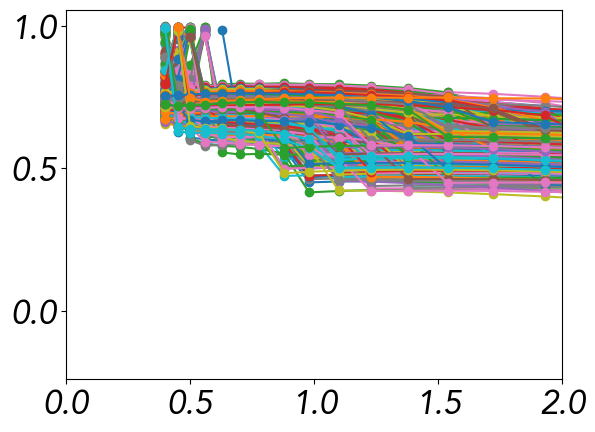

In [199]:
mean_corr_q0 = np.nanmean(
    corr100,
    axis=0
)
plt.plot(taus,corr100_.T, '-o');
#plt.xscale('log')
plt.xlim(0,2)

In [29]:
taus = np.round(np.logspace(-0.4, 2),2)
taus[0]

np.float64(0.4)

In [20]:
sub_tot

[]

## runnare anche questo immagino

In [191]:
taus = np.logspace(-.45,2,)

taus[0]


np.float64(0.35481338923357547)

In [28]:
asym_norm(np.random.randn(10,10))

np.float64(0.6974778110762655)

In [ ]:
import os
import numpy as np
from scipy import signal
from tqdm import tqdm
taus = np.logspace(-.45,2,)

number = 1013
# ==========================================================
# Utilities
# ==========================================================

def upper_triangle_vector(matrix):
    """
    Extract the independent off-diagonal elements of an
    antisymmetric or symmetric matrix.
    """
    indices = np.triu_indices(matrix.shape[0], k=1)
    return matrix[indices]


def safe_corr(x, y):
    """
    Pearson correlation robust to NaNs and constant vectors.
    """
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()

    valid = np.isfinite(x) & np.isfinite(y)

    x = x[valid]
    y = y[valid]

    if len(x) < 2:
        return np.nan

    if np.std(x) == 0 or np.std(y) == 0:
        return np.nan

    return np.corrcoef(x, y)[0, 1]


# ==========================================================
# Output variables
# ==========================================================

corr100 = [[] for _ in range((number))]
corr100_ = [[] for _ in range((number))]
ass100 = [[] for _ in range((number))]

# New directional measures
corr_S_Q1asym = [[] for _ in range((number))]
asym_S = [[] for _ in range((number))]
             
converged  = [[] for _ in range((number))]
my_info_ec  = [[] for _ in range((number))]
MAX_ITER = 100


# ==========================================================
# Main loop
# ==========================================================

for l, sub in enumerate(tqdm(sub_tot[:number])):

    file_path = (
        f'/home/benedetta/hcp_parcellated/{sub}/'
        f'{sub}_REST1_LR_Schaefer100+AAL.npy'
    )

    if not os.path.exists(file_path):
        continue

    data_1 = np.load(file_path)

    b, a = signal.butter(
        2,
        [0.01, 0.1],
        btype='bandpass',
        fs=1 / 0.72
    )

    data_ref = signal.filtfilt(
        b,
        a,
        data_1,
        axis=0
    )

    Y = cluster_regions(data_ref[:, :100], aggregate[:100])


    # Empirical covariance and lagged covariance
    Q0 = calc_Corr0(Y)
    Q1 = calc_Corrlag(Y, 1)

    # Empirical directional pattern at lag 1
    Q1_asym = 0.5 * (Q1 - Q1.T)

    Q1_asym_vector = upper_triangle_vector(
        Q1_asym
    )

    for _,tau_ in enumerate(taus):
    
        m = MOU()

        m.fit_LO(
            Q0,
            Q1,
            lag=1,
            prior=0.0,
            tau=float(tau_),
            eta_C=0.005,
            max_iter=MAX_ITER
        )

        J_prior = m.J.copy()
        #if _ ==0:
        #    plt.imshow(dediag(J_prior), vmin=-.1, vmax=.1, cmap='bwr')
        #\    plt.show()
        #plt.close()
        #if m.d_fit['iterations'] == MAX_ITER:
        #    print(
        #        tau_,
        #        sub,
        #        MAX_ITER,
        #        "iterations"
        #    )
        if m.d_fit['iterations'] == MAX_ITER:
            val = False
        else:
            val = True

        # --------------------------------------------------
        # EC asymmetry
        # --------------------------------------------------

        ass100[l].append(
            asym_norm(J_prior)
        )

        # --------------------------------------------------
        # Correlation with precision matrix
        # --------------------------------------------------

        corr100[l].append(
            safe_corr(
                dediag(J_prior).flatten(),
                dediag(m.Sigma@np.linalg.pinv(Q0)).flatten()
            )
        )

        
        J =m.J.copy()
        R2=(J@Q0 + Q0@J.T+ m.Sigma)
        
        q_rel= np.linalg.norm(R2, ord='fro') / (
        np.linalg.norm(J @ Q0, ord='fro')
        + np.linalg.norm(Q0 @ J.T, ord='fro')
        + np.linalg.norm(m.Sigma, ord='fro')
        )


        
        my_info_ec[l].append(q_rel) 
        # --------------------------------------------------
        # Correlation with empirical covariance
        # --------------------------------------------------

        corr100_[l].append(
            safe_corr(
                dediag(J_prior).flatten(),
                dediag(Q0).flatten()
            )
        )

        # --------------------------------------------------
        # Differential cross-covariance
        #
        # D = J Q0
        #
        # S is its antisymmetric component:
        #
        # S = 1/2 (J Q0 - Q0 J^T)
        # --------------------------------------------------

        S = 0.5 * (
            J_prior @ Q0
            - Q0 @ J_prior.T
        )

        # Magnitude of the modeled directional flow
        asym_S[l].append(
            asym_norm(S)
        )

        # Agreement between modeled and empirical
        # directional patterns
        corr_S_Q1asym[l].append(
            safe_corr(
                upper_triangle_vector(S),
                Q1_asym_vector
            )
        )
        if np.sum(dediag(m.J))==0:
            #print(m.J)
            print(l, 'doing........')
            val = False
            converged[l].append(val)
            print(tau_, val, l, _)
        #print('here')
        else:
            converged[l].append(val)
            
        
# ==========================================================
# Convert to arrays
# ==========================================================

corr100 = np.asarray(corr100, dtype=float)
corr100_ = np.asarray(corr100_, dtype=float)
ass100 = np.asarray(ass100, dtype=float)

corr_S_Q1asym = np.asarray(
    corr_S_Q1asym,
    dtype=float
)

asym_S = np.asarray(
    asym_S,
    dtype=float
)

  0%|          | 0/1013 [00:00<?, ?it/s]

Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Max

/tmp/ipykernel_31933/1114696791.py:3: RuntimeWarning: invalid value encountered in scalar divide
  return np.sum(np.abs(a - a.T))/np.sum(np.abs(a))/2


0 doing........
63.09573444801933 False 0 45
0 doing........
70.79457843841384 False 0 46
0 doing........
79.43282347242817 False 0 47


  0%|          | 1/1013 [00:27<7:40:25, 27.30s/it]

...

Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Max

  9%|▊         | 88/1013 [40:24<7:29:15, 29.14s/it]

87 doing........
100.0 False 87 49
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.

  9%|▉         | 89/1013 [40:52<7:25:36, 28.94s/it]

88 doing........
89.12509381337463 False 88 48
88 doing........
100.0 False 88 49
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not 

In [143]:
for i in range(11):
    print(len(converged[i]))

50
50
50
50
50
50
50
50
50
50


IndexError: list index out of range

np.float64(0.31622776601683794)

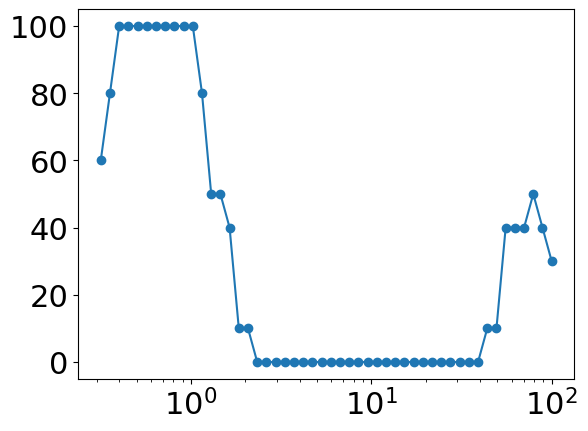

In [146]:
plt.plot(taus,np.sum(converged,0)/10*100,'o-')
plt.xscale('log');
taus[0]

In [ ]:
corr

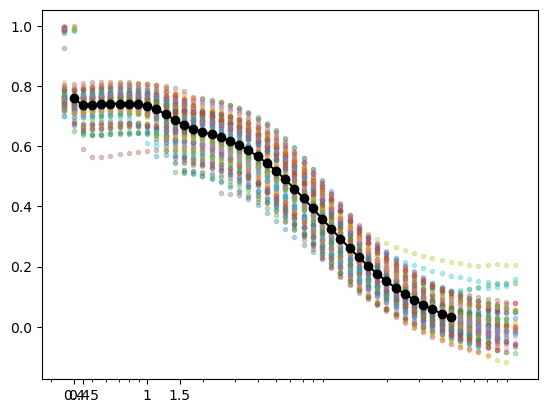

In [48]:
np.asarray(converged).shape

plt.plot(taus, corr100_.T,'.', alpha=.3);
plt.plot(taus, np.mean(corr100_,0),'-o',color='black');

plt.xscale('log');

plt.xticks([0.4,.45,1,1.5,],labels = [0.4,0.45,1,1.5,]);

In [ ]:
np.asarray(converged).shape

plt.plot(taus, -corr100.T,'o');
plt.xscale('log');

plt.xticks([0.35,.45,1,1.5,],labels = [0.35,0.45,1,1.5,]);

In [ ]:
converged = np.load('../numpy files/converged.npy')
converged.shape

In [ ]:
np.where(np.sum(converged,0)/1013*100>=60)[0], taus[-1]
converged.shape

In [33]:
plt.plot(taus,my_info_ec.T,'-o', alpha=.3);
plt.plot(taus,-np.mean(my_info_ec,
                       0),'k-o')#, alpha=.3);
plt.xscale('log');


NameError: name 'my_info_ec' is not defined

In [80]:

v=np.load('../numpy files/corr__74_102sub_log.npy')

(0.35, 10)

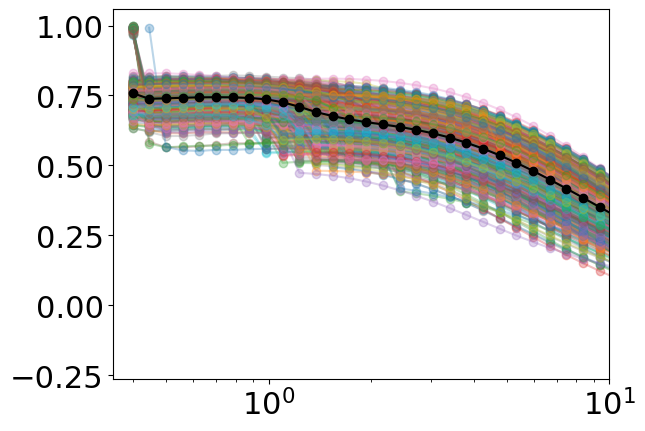

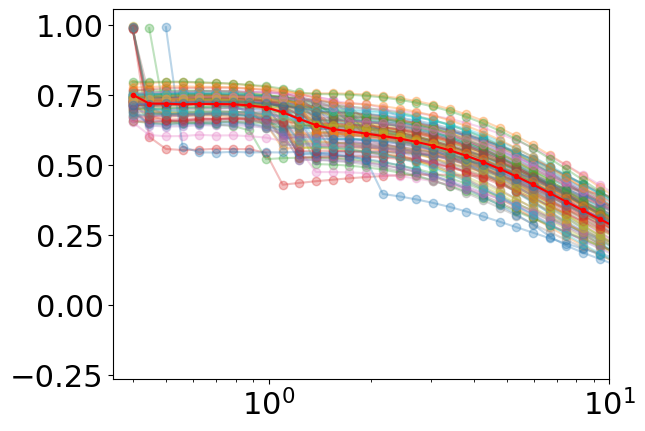

In [81]:
v2=np.load('../numpy files/corr__62_1013_log.npy')
taus =np.logspace(-.4,2)

plt.plot(taus,v2.T,'-o', alpha=.3);
plt.xscale('log');
taus =np.logspace(-.4,2)
plt.plot(taus,np.nanmean(v2,0),'k-o')#, alpha=.3);
plt.xlim(.35,10)

taus =np.logspace(-.4,2)
plt.figure()
taus =np.logspace(-.4,2)
plt.plot(taus,v.T,'-o', alpha=.3);

plt.plot(taus,np.nanmean(v,0),'r-o', ms=3)#, alpha=.3);
plt.xscale('log');

corr100_.shape
plt.xlim(.35,10)

In [126]:
np.asarray(converged)[:,0]

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True])

1.2067926406393288
9
80.0


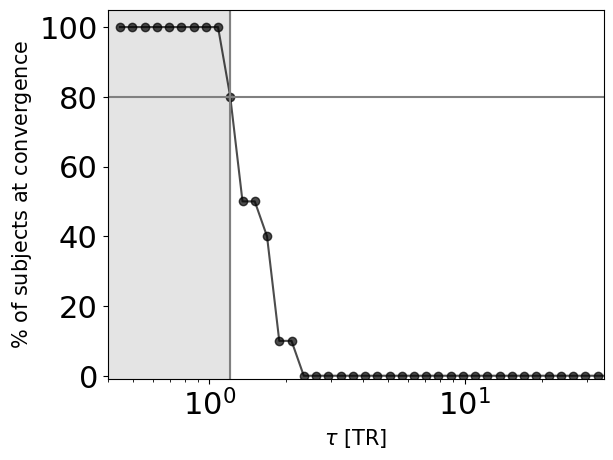

In [124]:
plt.rcParams['font.size'] = 22
taus =np.logspace(-.35,2)
converged = np.asarray(converged)
plt.plot(taus,np.sum(converged,0)/number*100,'o-', color='black', alpha=.7);
plt.xscale('log');
plt.xlim(0.4,35);
#plt.xlim(0.45,2)
tau_soglia = taus[np.where(np.sum(converged[:,:20],0)/number*100>=70)[0][-1]]
print(tau_soglia)
index = np.where(np.sum(converged[:,:20],0)/number*100>=70)[0][-1]
print(index)
val_y = np.sum(converged,0)[index]/number*100
plt.vlines(tau_soglia,-1,110, color='gray')
plt.hlines(val_y,0,1013,color='gray')
#plt.vlines(1,-1,110, color='gray')
print(val_y)
plt.ylabel(r'$\%$ of subjects at convergence', fontsize =15)
plt.axvspan(0.4,tau_soglia,color='lightgray', alpha=.6)
plt.xlabel(r"$\tau$ [TR]", fontsize = 15)
plt.ylim(-1,105);
#plt.savefig('../Figures/subject_converged.jpg', dpi= 300, bbox_inches='tight');

In [63]:
converged = np.asarray(converged)
converged.shape


np.save('../numpy files/converged.npy',converged)

In [77]:
np.sum(converged,0)

array([1013, 1013, 1013, 1013, 1013, 1013, 1013, 1012,  998,  944,  794,
        566,  353,  171,   73,   29,   10,    3,    2,    2,    1,    1,
          0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
          0,    0,    0,    0,    0,    2,   11,   26,   70,  139,  264,
        418,  612,  772,  897,  975, 1005])

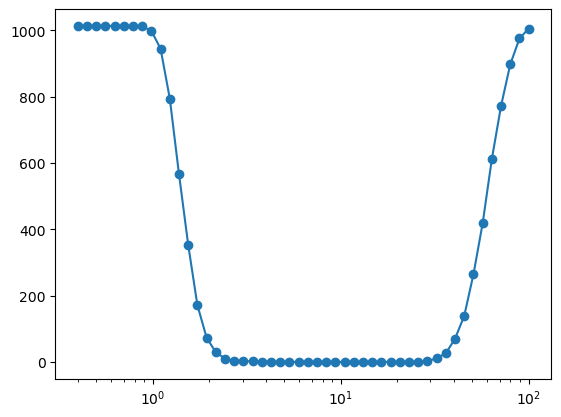

In [48]:
converged = np.asarray(converged)
plt.plot(taus,np.sum(converged,0), '-o');
plt.xscale('log');

In [63]:
m.J.shape

(100, 100)

In [91]:
converged = np.asarray(converged[:])
converged.shape, len(taus)

((1013, 50), 50)

In [93]:
data_ref.shape, len(taus), taus[-2], m.J.shape

((1200, 112), 50, np.float64(89.54489186289914), (62, 62))

In [98]:
taus[np.where(np.sum(converged,0)/1013*100<=55)[0][0]]


np.float64(1.5050503199697136)

In [89]:
taus[np.where(np.sum(converged,0)<=55)[0][0]]

np.float64(1.5050503199697136)

1.5050503199697136


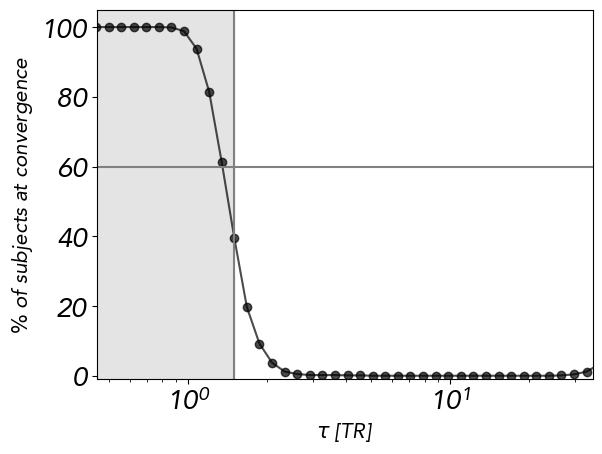

In [135]:
y_recovered = np.array([
    100.0, 100.0, 100.0, 100.0, 100.0, 100.0,
     99.4,  93.8,  81.5,  61.5,  39.7,  19.9,
      9.3,   3.9,   1.5,   0.7,   0.3,   0.3,
      0.3,   0.3,   0.3,   0.3,   0.1,   0.1,
      0.1,   0.1,   0.1,   0.1,   0.1,   0.1,
      0.1,   0.1,   0.1,   0.1,   0.1,   0.1,
      0.3,   0.7,   1.3
])
plt.plot(taus,np.sum(converged,0)/1013*100,'o-', color='black', alpha=.7);
plt.xscale('log');
plt.xlim(0.45,35);
#plt.xlim(0.45,2)
tau_soglia = taus[np.where(np.sum(converged,0)/1013*100<=60)[0][0]]
print(tau_soglia)
plt.vlines(tau_soglia,-1,110, color='gray')
plt.hlines(60,0,1013,color='gray')
#plt.vlines(1,-1,110, color='gray')

plt.ylabel(r'$\%$ of subjects at convergence', fontsize =15)
plt.axvspan(0.45,1.5,color='lightgray', alpha=.6)
plt.xlabel(r"$\tau$ [TR]", fontsize = 15)
plt.ylim(-1,105);

In [189]:
## SOME QUANTITIES TO PLOT

In [271]:
np.save('../numpy files/my_info_ec_1013_100.npy', np.asarray(my_info_ec[:1009]))

## Some quantities to plot

In [82]:
to_plot=np.load('../numpy files/my_info_ec_1013_62.npy')
to_plot_=np.load('../numpy files/my_info_ec_1013_100.npy')


In [ ]:
np.logspace(-.35,2,)[0,]

In [ ]:
plt.plot(np.mean(to_plot_,0), color='red');
plt.plot(np.mean(to_plot,0), color='black');
#plt.plot(-to_plot[::100].T, alpha=.8);




(0.0, 3.0)

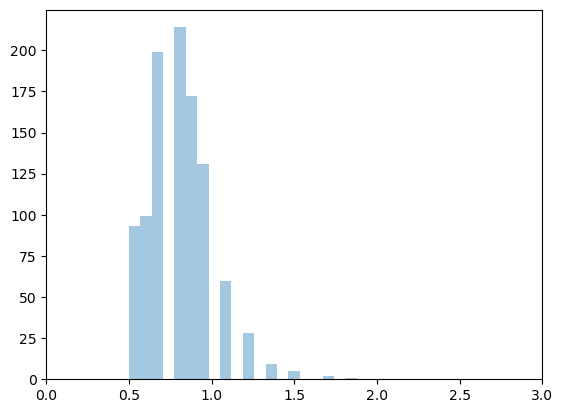

In [60]:
#plt.hist(taus_est,bins = 50)
plt.hist(taus_est_2, alpha=.4, bins = 20);
plt.xlim(0,3)

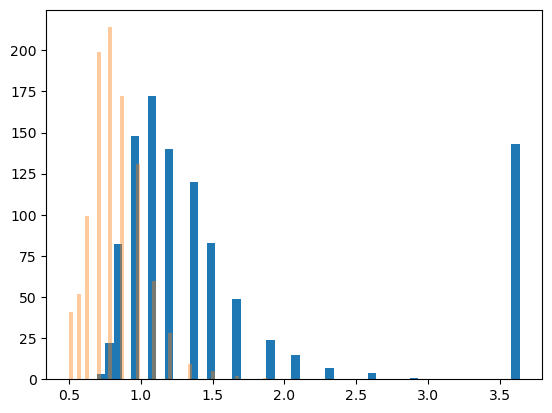

In [63]:
plt.hist(taus_est,bins = 50)
plt.hist(taus_est_2, alpha=.4, bins = 50);
#plt.xlim(0,3)

In [50]:
taus_est=[]
taus_est_2=[]

for _,i in enumerate(to_plot_):
    taus_est.append(taus[1:][np.argmin(to_plot_[_,1:])])
    taus_est_2.append(taus[1:][np.argmax(to_plot[_,1:20])])
    

/tmp/ipykernel_41270/4071677311.py:20: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


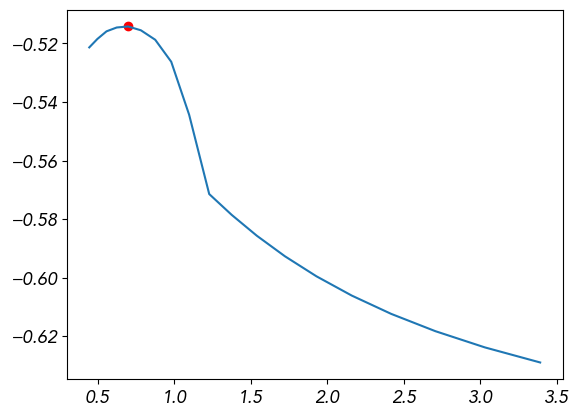

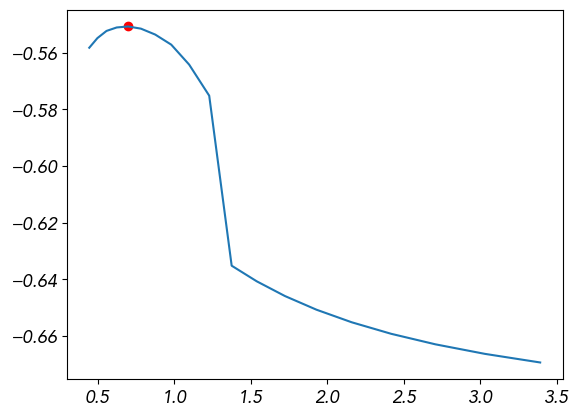

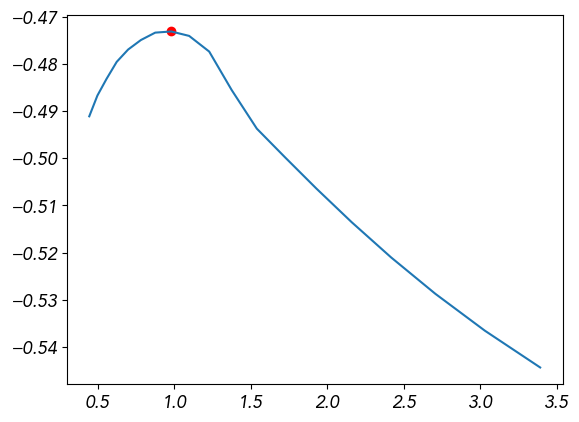

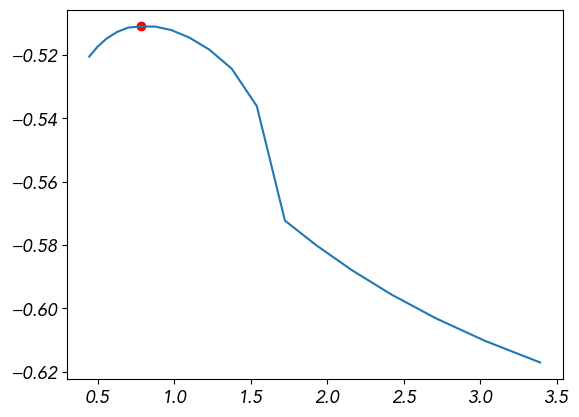

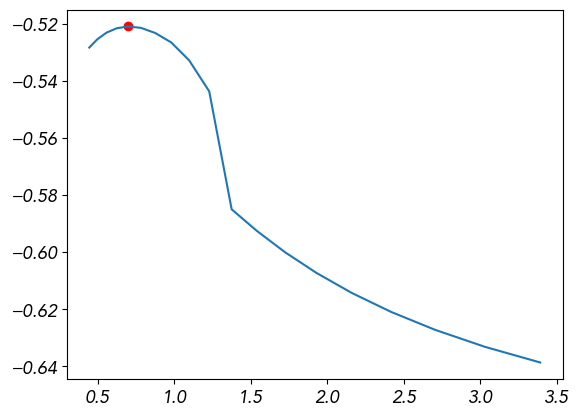

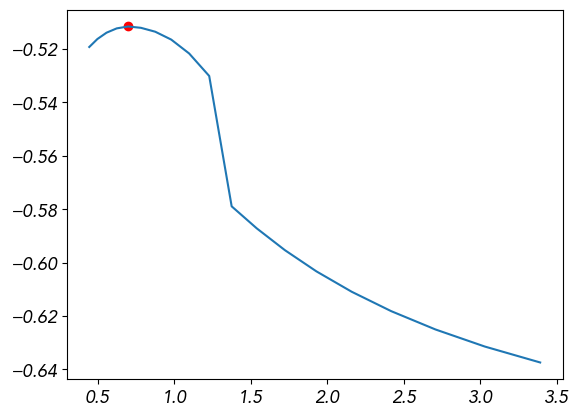

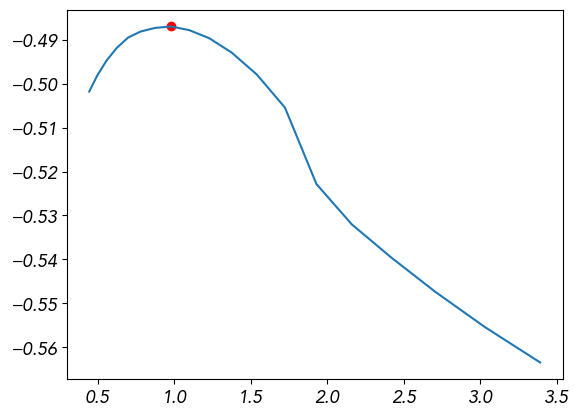

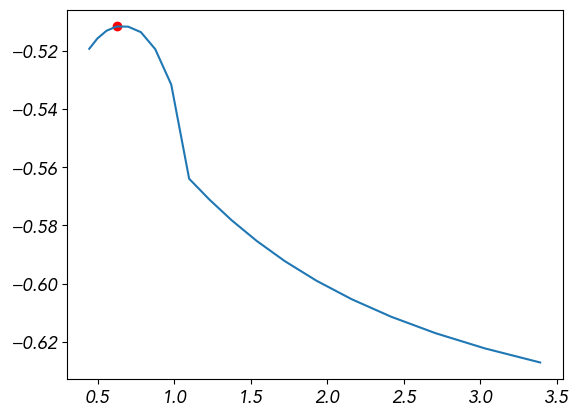

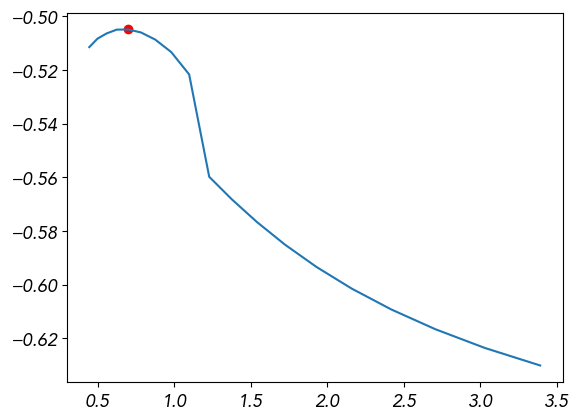

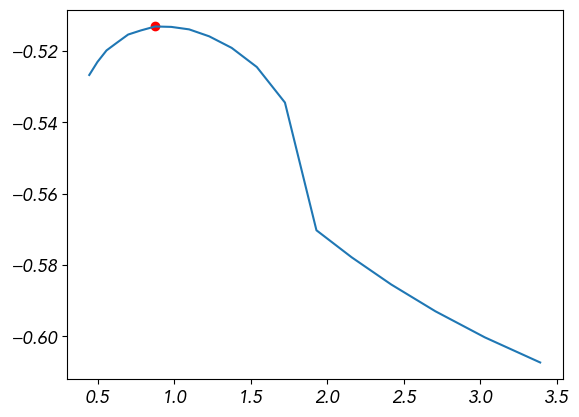

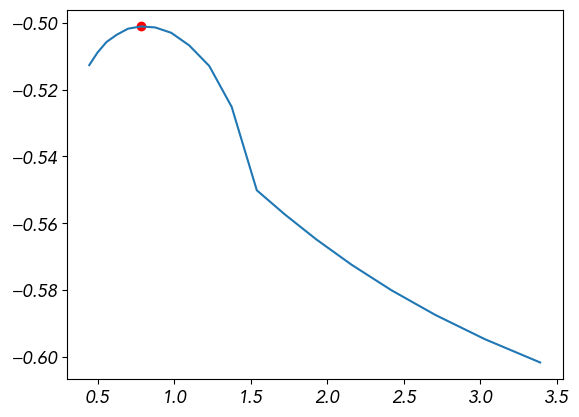

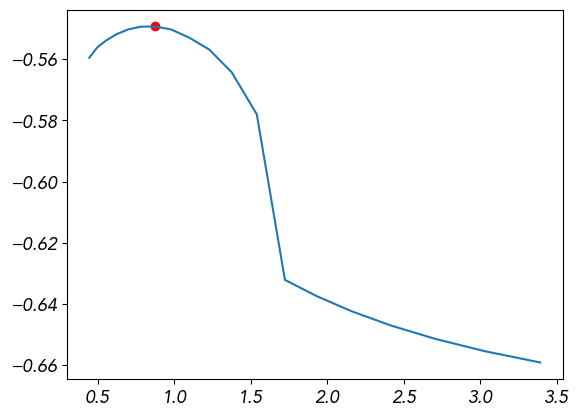

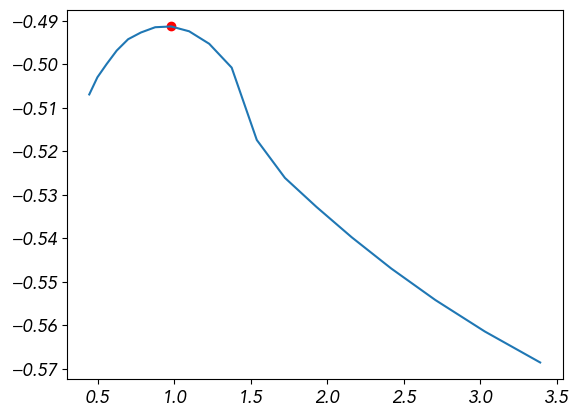

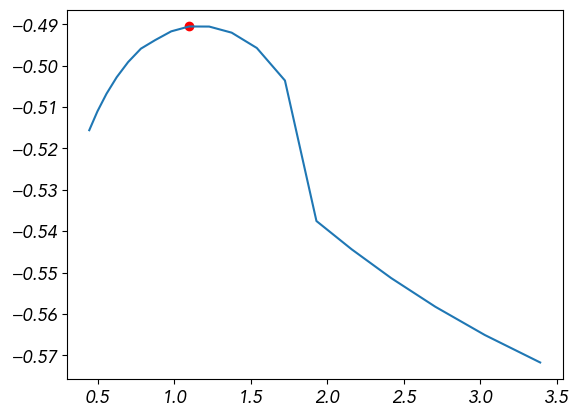

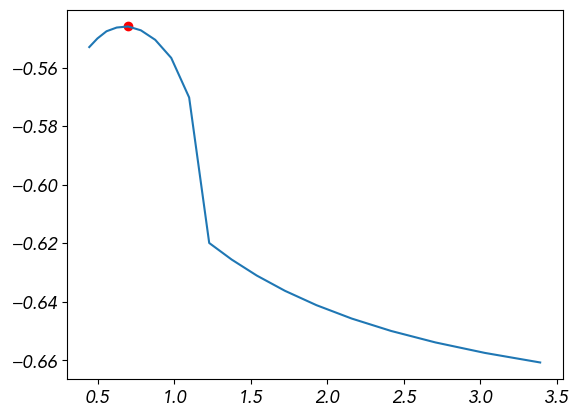

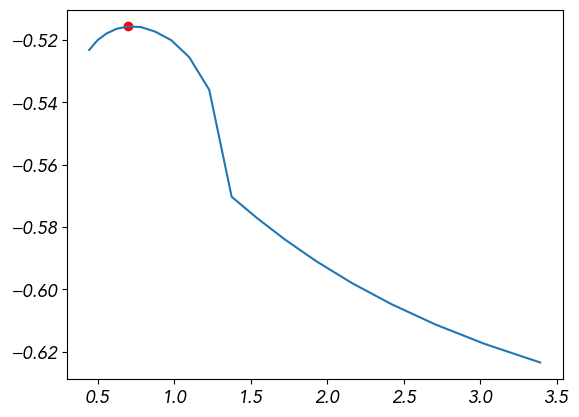

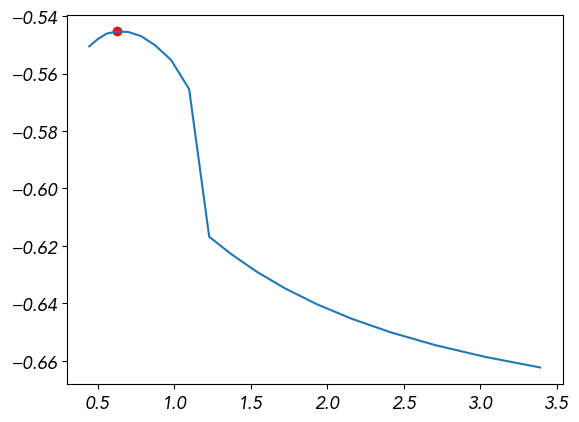

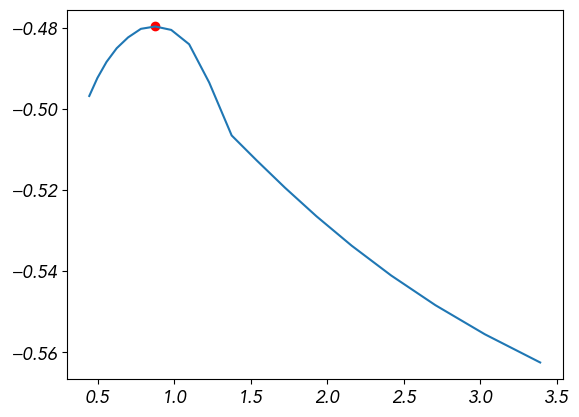

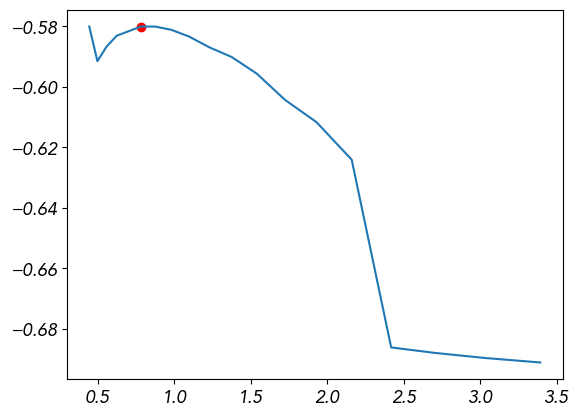

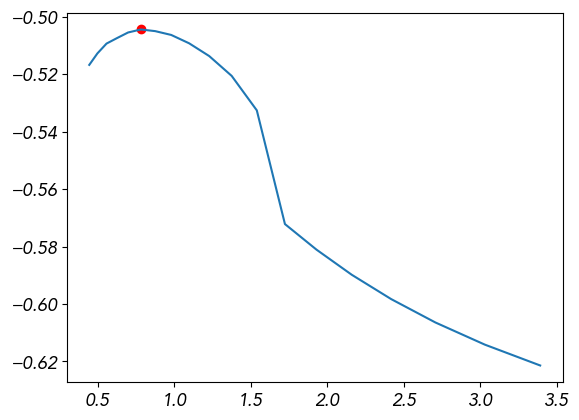

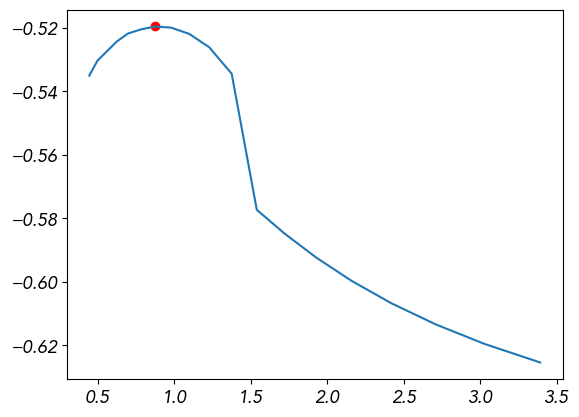

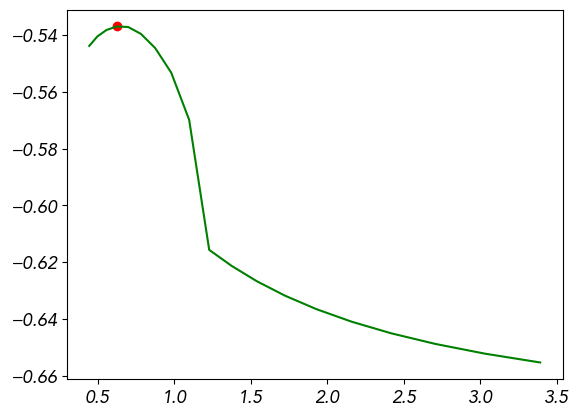

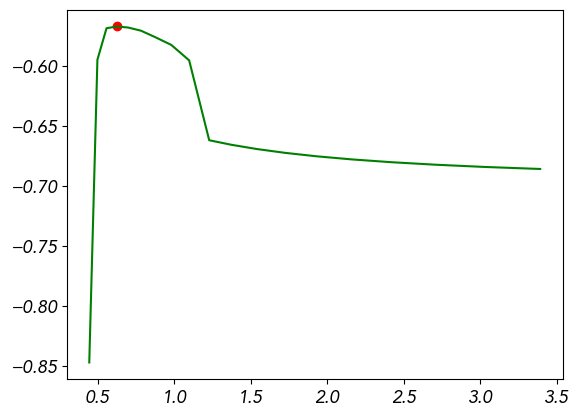

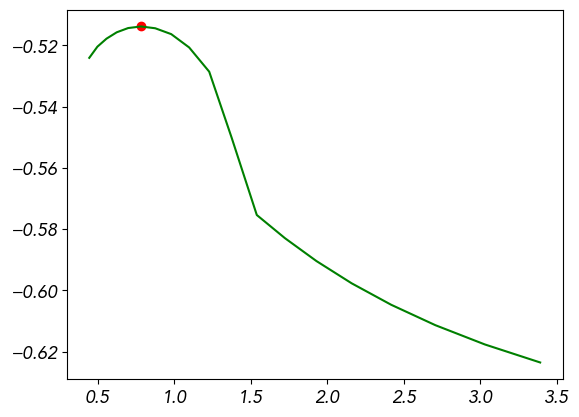

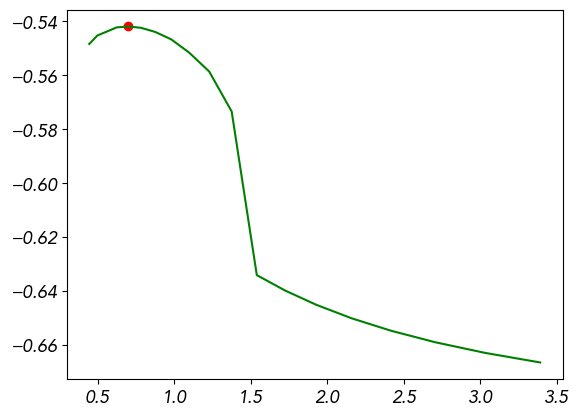

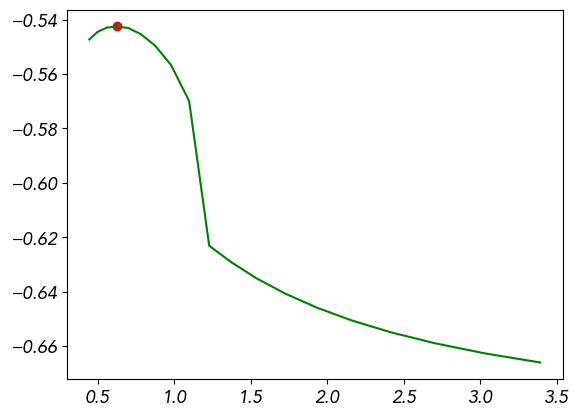

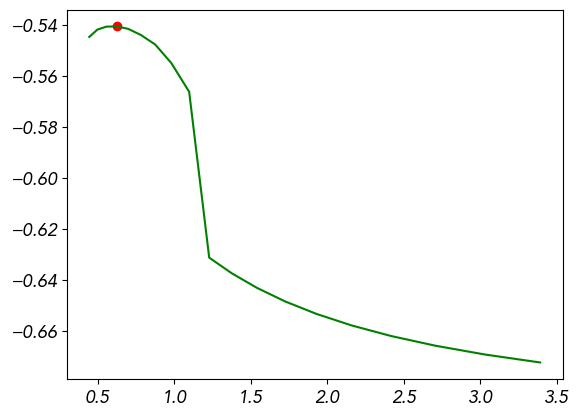

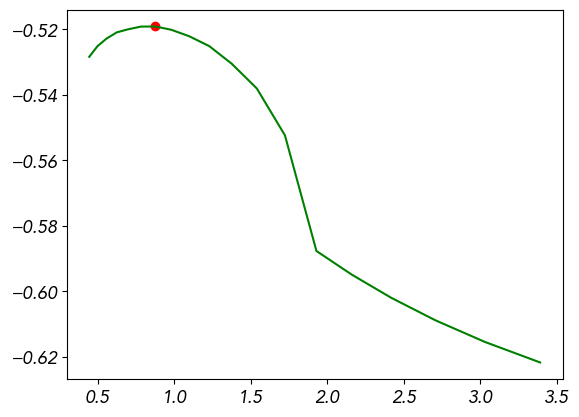

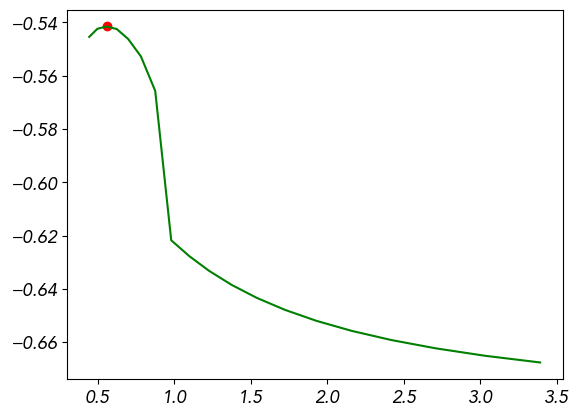

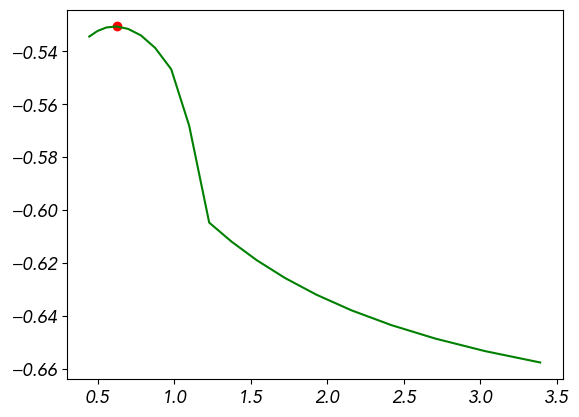

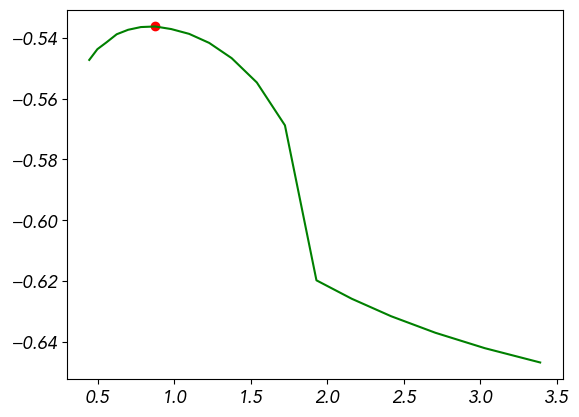

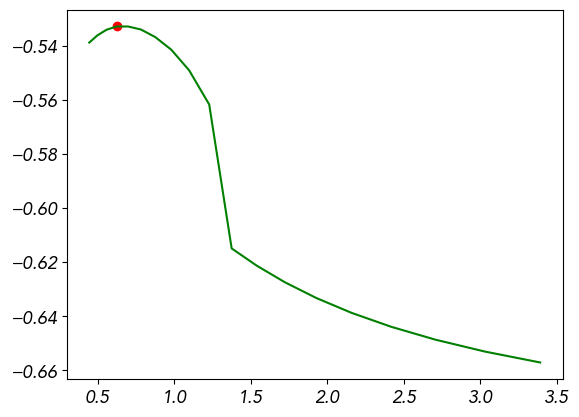

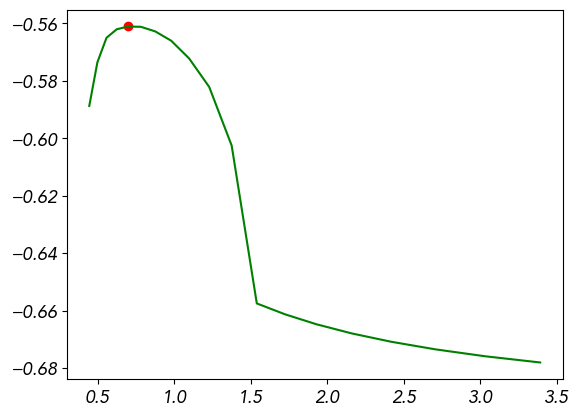

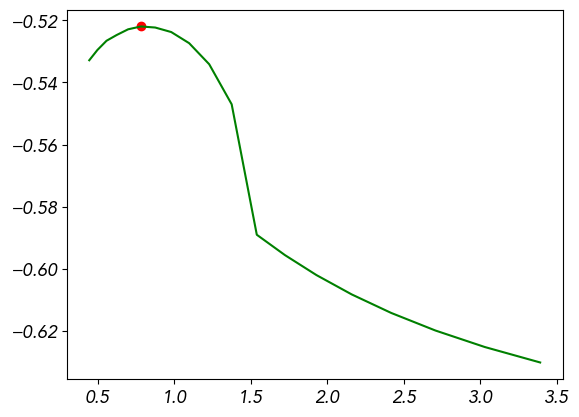

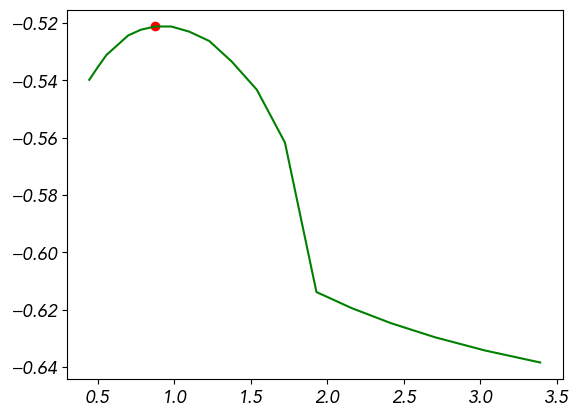

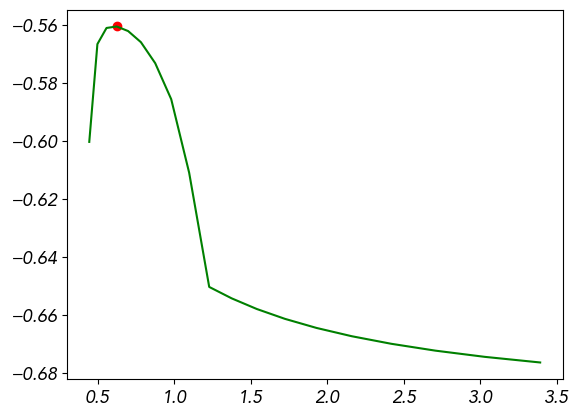

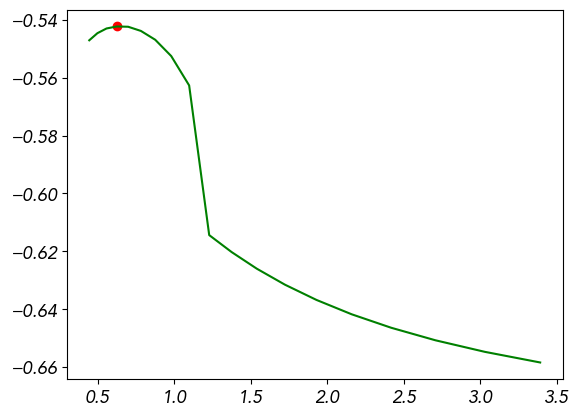

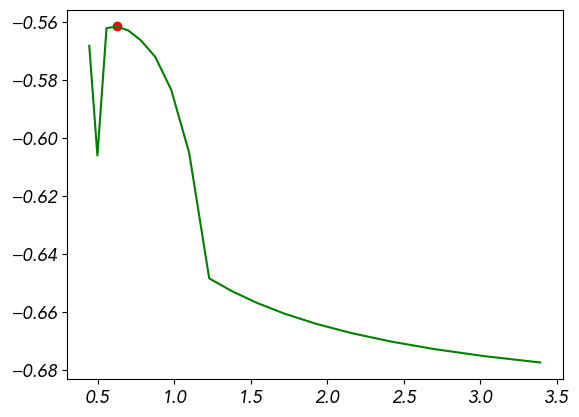

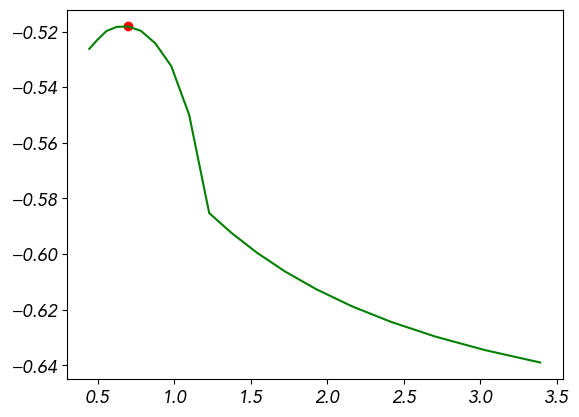

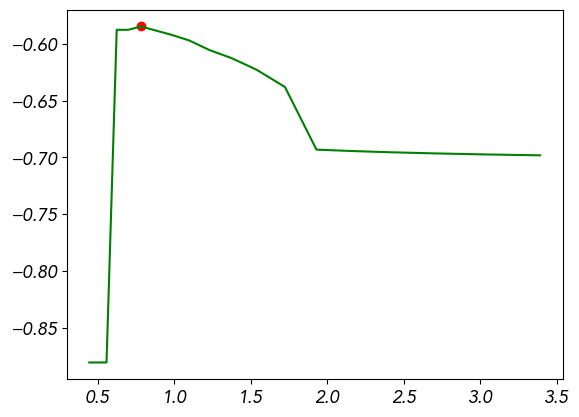

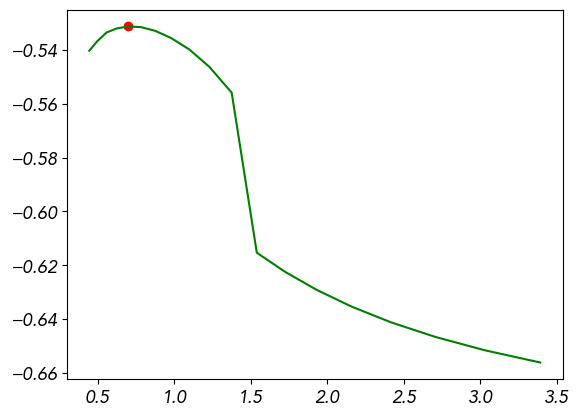

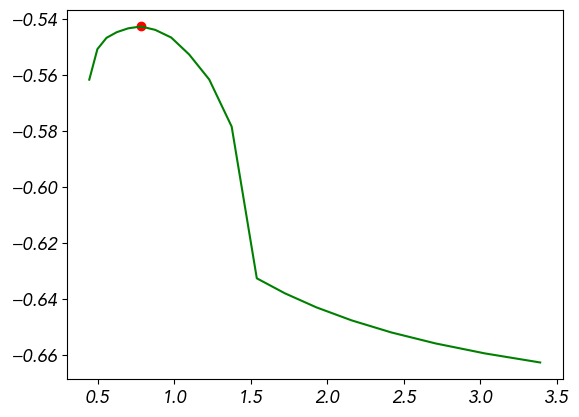

In [300]:
import numpy as np
from scipy.signal import find_peaks

def first_local_max(x, prominence=0.01, width = None):
    peaks, _ = find_peaks(x, prominence=prominence, width= width)

    if len(peaks) == 0:
        return np.argmax(x)  # fallback sul massimo globale

    return peaks[0]
taus_est_2=[]

for _,i in enumerate(to_plot_):
    x = -to_plot[_, 1:20]
    idx_peak = first_local_max(x, prominence=0.01)
    
    taus_est_2.append(taus[1:20][idx_peak])

    if _%50==0:
        plt.figure()
        plt.plot(taus[1:20][idx_peak], x[idx_peak], 'ro');
        plt.plot(taus[1:20], x, );


taus_est=[]

for _,i in enumerate(to_plot_):
    x = -to_plot_[_, 1:20]
    idx_peak = first_local_max(x, prominence=0.01)
    
    taus_est.append(taus[1:20][idx_peak])
    if _%50==0:
        plt.figure()
        plt.plot(taus[1:20][idx_peak], x[idx_peak], 'ro');
        plt.plot(taus[1:20], x, color='green');
        

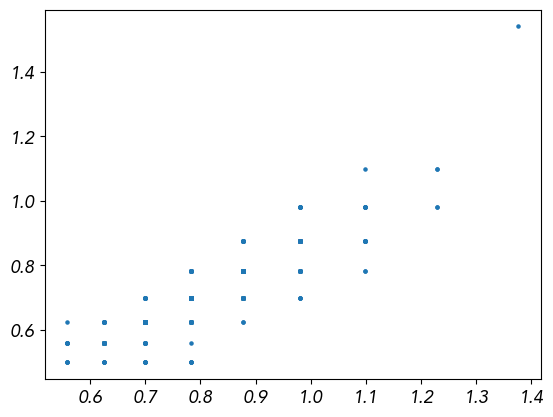

In [312]:
plt.scatter(taus_est_2, taus_est[:1009], s=5);


In [309]:
np.mean(taus_est), np.median(taus_est_2)

(np.float64(0.7160022909751991), np.float64(0.7832087865456271))

(array([115., 206., 257., 240.,   0., 153.,  33.,   0.,   4.,   1.]),
 array([0.55839147, 0.6402021 , 0.72201273, 0.80382336, 0.88563399,
        0.96744462, 1.04925525, 1.13106588, 1.21287651, 1.29468713,
        1.37649776]),
 <BarContainer object of 10 artists>)

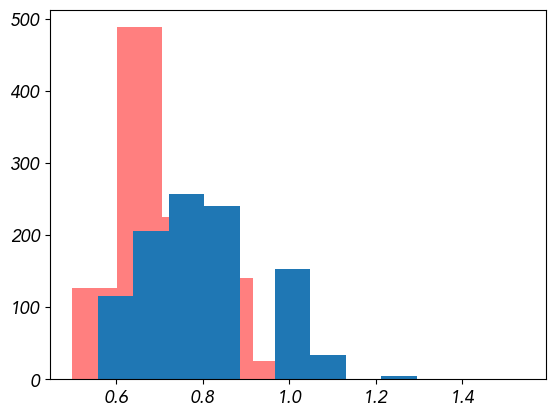

In [287]:
plt.hist(taus_est, color='red', alpha=.5)
plt.hist(taus_est_2)


In [173]:
np.save('../numpy files/est_tau.npy',np.array(taus_est_2),)

(array([ 93.,  99., 199.,   0., 214., 172., 131.,   0.,  60.,   0.,  28.,
          0.,   9.,   0.,   5.,   0.,   0.,   2.,   0.,   1.]),
 array([0.5  , 0.569, 0.638, 0.707, 0.776, 0.845, 0.914, 0.983, 1.052,
        1.121, 1.19 , 1.259, 1.328, 1.397, 1.466, 1.535, 1.604, 1.673,
        1.742, 1.811, 1.88 ]),
 <BarContainer object of 20 artists>)

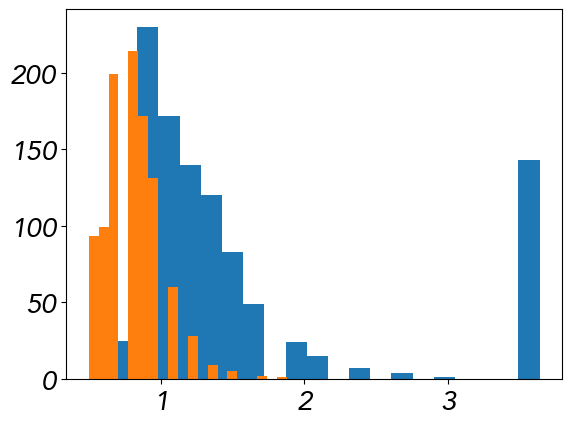

In [9]:
import os


In [118]:
import os
import numpy as np
from scipy import signal
from tqdm import tqdm


# ==========================================================
# UTILITIES
# ==========================================================

def offdiag_vector(matrix):
    """
    Return all off-diagonal elements.
    """
    matrix = np.asarray(matrix)
    mask = ~np.eye(matrix.shape[0], dtype=bool)
    return matrix[mask]


def upper_triangle_vector(matrix):
    """
    Return the independent upper-triangular off-diagonal elements.
    Useful for antisymmetric matrices.
    """
    indices = np.triu_indices(matrix.shape[0], k=1)
    return matrix[indices]


def safe_corr(x, y):
    """
    Pearson correlation robust to NaNs and constant vectors.
    """
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()

    valid = np.isfinite(x) & np.isfinite(y)

    x = x[valid]
    y = y[valid]

    if len(x) < 2:
        return np.nan

    if np.std(x) == 0 or np.std(y) == 0:
        return np.nan

    return np.corrcoef(x, y)[0, 1]

number = 102
# ==========================================================
# OUTPUT VARIABLES
# ==========================================================
my_info = [[] for _ in range(number)]
my_info_ec = [[] for _ in range(number)]


corr = [[] for _ in range(number)]
corr_ = [[] for _ in range(number)]
ass = [[] for _ in range(number)]

# Previously introduced directional measure
corr_S_Q1asym_ = [[] for _ in range(number)]

# New quantities
neq_to_diss_ratio = [[] for _ in range(number)]
S_amplitude_ratio = [[] for _ in range(number)]


MAX_ITER = 100


# ==========================================================
# MAIN LOOP
# ==========================================================

for l, sub in enumerate(tqdm(sub_tot[::100])):

    file_path = (
        f'/home/benedetta/hcp_parcellated/{sub}/'
        f'{sub}_REST1_LR_Schaefer100+AAL.npy'
    )

    if not os.path.exists(file_path):
        continue

    data_1 = np.load(file_path)

    b, a = signal.butter(
        2,
        [0.01, 0.1],
        btype='bandpass',
        fs=1 / 0.72
    )

    data_ref = signal.filtfilt(
        b,
        a,
        data_1,
        axis=0
    )

    Y = data_ref[:, :100]

    Q0 = calc_Corr0(Y)
    Q1 = calc_Corrlag(Y, 1)

    Q0_inv = np.linalg.pinv(Q0)

    # Empirical antisymmetric lagged covariance
    Q1_asym = 0.5 * (Q1 - Q1.T)

    q1_asym_norm = np.linalg.norm(
        Q1_asym,
        ord='fro'
    )

    for tau_ in taus:

        m = MOU()

        m.fit_LO(
            Q0,
            Q1,
            lag=1,
            prior=0.0,
            tau=float(tau_),
            eta_C=0.005,
            max_iter=MAX_ITER
        )

        J = m.J.copy()

        if m.d_fit['iterations'] == MAX_ITER:
            print(
                sub,
                tau_,
                MAX_ITER,
                "iterations"
            )

        # --------------------------------------------------
        # Standard quantities
        # --------------------------------------------------

        ass[l].append(
            asym_norm(J)
        )

        corr[l].append(
            safe_corr(
                offdiag_vector(J),
                offdiag_vector(Q0_inv)
            )
        )
        J_asym = 0.5 * (J - J.T)
        
        my_info[l].append(safe_corr(
                upper_triangle_vector(J_asym),
                upper_triangle_vector(Q1_asym)
            )
        )
        corr_[l].append(np.linalg.norm(
        dediag(Q0)/np.linalg.norm(
        dediag(Q0),
        ord='fro'
        )- dediag(J)/np.linalg.norm(
        dediag(J),
        ord='fro'
        ),
        ord='fro'
    ))
        
        
        q_ =np.sum(np.abs(J@Q0 + Q0@J.T+ m.Sigma))
        
        # --------------------------------------------------
        # Differential cross-covariance / probability current
        #
        # S = 1/2 (J Q0 - Q0 J^T)
        # --------------------------------------------------

        S = 0.5 * (
            J @ Q0
            - Q0 @ J.T
        )
        
        # safe_corr(
        #        offdiag_vector(J),
        #        offdiag_vector(S@np.linalg.inv(Q0))
        #    )
        my_info_ec[l].append(q_
        )
        corr_S_Q1asym_[l].append(
            safe_corr(
                upper_triangle_vector(S),
                upper_triangle_vector(Q1_asym)
            )
        )

        # --------------------------------------------------
        # Noise covariance
        # --------------------------------------------------
        #
        # Replace m.Sigma with the actual attribute used by
        # your MOU implementation, if it has a different name.
        #
        # If the model stores only diagonal noise variances,
        # convert them into a diagonal matrix.
        # --------------------------------------------------

        Sigma = np.asarray(m.Sigma)
        print(np.std(np.diag(Sigma)))
        if Sigma.ndim == 1:
            Sigma = np.diag(Sigma)

        
        k_ = Q0
        p_ = m.Sigma
        commutator_T = k_ @ p_.T - p_.T @ k_
        
        relative_comm_T = (
            np.linalg.norm(commutator_T, ord="fro")
            / (
                np.linalg.norm(k_ @ p_.T, ord="fro")
                + np.linalg.norm(p_.T @ k_, ord="fro")
            )
        )
        
        print(tau_, "Relative commutator Q0,Sigma:", relative_comm_T)
        # --------------------------------------------------
        # Decomposition:
        #
        # J = J_diss + J_neq
        #
        # J_diss = -1/2 Sigma Q0^-1
        # J_neq  = S Q0^-1
        # --------------------------------------------------

        J_diss = -0.5 * Sigma @ Q0_inv
        J_neq = S @ Q0_inv

        diss_norm = np.linalg.norm(
            J_diss,
            ord='fro'
        )

        neq_norm = np.linalg.norm(
            J_neq,
            ord='fro'
        )

        # --------------------------------------------------
        # 1. Relative non-equilibrium contribution
        # --------------------------------------------------

        neq_to_diss_ratio[l].append(
            neq_norm / diss_norm
            if diss_norm > 0
            else np.nan
        )

        # --------------------------------------------------
        # 2. Relative amplitude of modeled directional flow
        # --------------------------------------------------

        S_norm = np.linalg.norm(
            S,
            ord='fro'
        )

        S_amplitude_ratio[l].append(
            S_norm / q1_asym_norm
            if q1_asym_norm > 0
            else np.nan
        )


# ==========================================================
# CONVERT TO ARRAYS
# ==========================================================

corr = np.asarray(
    corr,
    dtype=float
)

corr_ = np.asarray(
    corr_,
    dtype=float
)

ass = np.asarray(
    ass,
    dtype=float
)

corr_S_Q1asym_ = np.asarray(
    corr_S_Q1asym_,
    dtype=float
)

neq_to_diss_ratio = np.asarray(
    neq_to_diss_ratio,
    dtype=float
)

S_amplitude_ratio = np.asarray(
    S_amplitude_ratio,
    dtype=float
)

  0%|          | 0/11 [00:00<?, ?it/s]

0.2978315932527113
0.44668359215096315 Relative commutator Q0,Sigma: 0.06092815259977864
0.27887580211360735
0.4988376029699983 Relative commutator Q0,Sigma: 0.0676852513036162
0.25813902163044145
0.5570810267254118 Relative commutator Q0,Sigma: 0.07286085422869207
0.23825318663250142
0.6221248528373347 Relative commutator Q0,Sigma: 0.07809446628789624
0.21906368826926703
0.6947630846322991 Relative commutator Q0,Sigma: 0.08324997897861124
0.2006539581233871
0.7758824319047037 Relative commutator Q0,Sigma: 0.08825883118429394
0.18381858380306132
0.866473135165148 Relative commutator Q0,Sigma: 0.0947715268171736
0.16795121898737173
0.9676410537094535 Relative commutator Q0,Sigma: 0.10250246534903351
0.1530207010486803
1.080621165069912 Relative commutator Q0,Sigma: 0.11390688180322424
Optimization did not converge. Maximum number of iterations arrived.
100206 1.2067926406393288 100 iterations
0.13481355502612444
1.2067926406393288 Relative commutator Q0,Sigma: 0.1499563832296675
Optimiz

/tmp/ipykernel_8620/2174178214.py:166: RuntimeWarning: invalid value encountered in divide
  )- dediag(J)/np.linalg.norm(


2.475007258447266e-17
80.182876587383 Relative commutator Q0,Sigma: 6.714533817454526e-16
2.1978337156769245e-17
89.54489186289914 Relative commutator Q0,Sigma: 6.673649732681834e-16


  9%|▉         | 1/11 [01:03<10:33, 63.31s/it]

...

 91%|█████████ | 10/11 [10:38<01:03, 63.75s/it]

0.010563318120316368
100.0 Relative commutator Q0,Sigma: 0.2481483036632725
0.29843695854400676
0.44668359215096315 Relative commutator Q0,Sigma: 0.05128689690332748
0.3285709278487844
0.4988376029699983 Relative commutator Q0,Sigma: 0.08244565302327717
0.308103452461136
0.5570810267254118 Relative commutator Q0,Sigma: 0.09304653649737586
0.28283314236428364
0.6221248528373347 Relative commutator Q0,Sigma: 0.09820397001088613
0.25969885334491666
0.6947630846322991 Relative commutator Q0,Sigma: 0.10372185664009843
0.23806630293968822
0.7758824319047037 Relative commutator Q0,Sigma: 0.10936633969899572
0.2191273915943657
0.866473135165148 Relative commutator Q0,Sigma: 0.11802936524634301
0.19973672502653303
0.9676410537094535 Relative commutator Q0,Sigma: 0.1235631077614339
0.18238769571546043
1.080621165069912 Relative commutator Q0,Sigma: 0.13182528863691134
0.16631503149689636
1.2067926406393288 Relative commutator Q0,Sigma: 0.1424182484481346
0.1512738127197276
1.3476956814990977 Rel

100%|██████████| 11/11 [11:41<00:00, 63.76s/it]

0.011240506723676835
89.54489186289914 Relative commutator Q0,Sigma: 0.21335920477279754
1.8180696540712057e-17
100.0 Relative commutator Q0,Sigma: 6.291570069389952e-16


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (102,) + inhomogeneous part.

(0.4, 3.0)

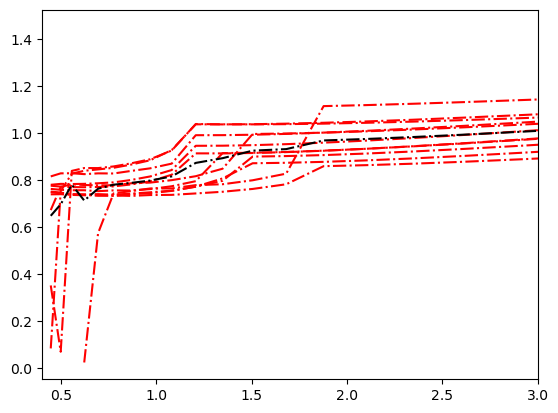

In [98]:
fig,ax=plt.subplots(1,1)
ax.plot(
    taus,
(np.asarray(corr_[::10])).T,
    'r-.',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
);


ax.plot(
    taus,
np.nanmean(np.asarray(corr_[::10]),0),
    'k-.',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
);
#plt.ylim(0,)
plt.xlim(0.4,3)
#plt.xscale('log')

(0.0, 3.0)

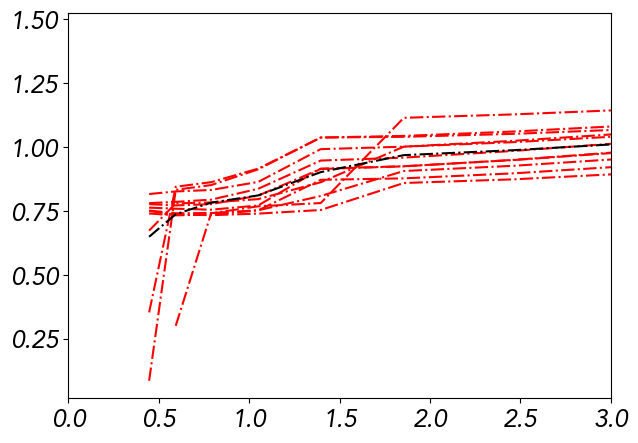

In [342]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)





/tmp/ipykernel_8620/2245742994.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


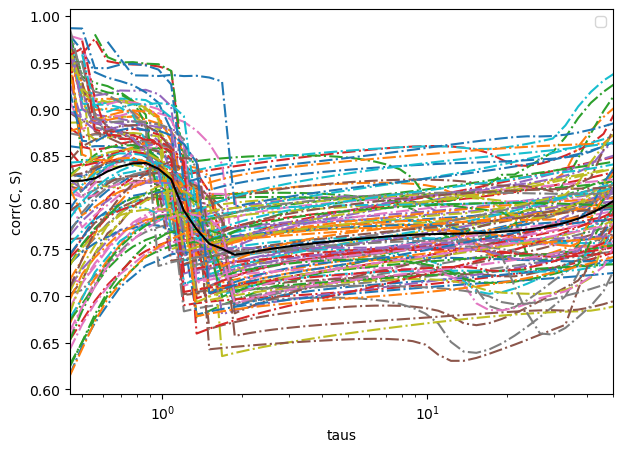

In [109]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.plot(
    taus,
    np.asarray(corr_S_Q1asym_[:]).T,
    '-.',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
ax.plot(
    taus,
    np.nanmean(corr_S_Q1asym_[:],0),
    'k-',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
plt.xscale('log');
plt.ylabel('corr(C, S)')
plt.xlabel('taus')
#plt.vlines(1.38,0,1,color='red', label ='convergence limit')
plt.xlim(0.45,50)
#plt.ylim(0,.1)
plt.legend()


In [175]:
import os
import numpy as np
from scipy import signal
from tqdm import tqdm


# ==========================================================
# UTILITIES
# ==========================================================

def offdiag_vector(matrix):
    """
    Return all off-diagonal elements.
    """
    matrix = np.asarray(matrix)
    mask = ~np.eye(matrix.shape[0], dtype=bool)
    return matrix[mask]


def upper_triangle_vector(matrix):
    """
    Return the independent upper-triangular off-diagonal elements.
    Useful for antisymmetric matrices.
    """
    indices = np.triu_indices(matrix.shape[0], k=1)
    return matrix[indices]


def safe_corr(x, y):
    """
    Pearson correlation robust to NaNs and constant vectors.
    """
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()

    valid = np.isfinite(x) & np.isfinite(y)

    x = x[valid]
    y = y[valid]

    if len(x) < 2:
        return np.nan

    if np.std(x) == 0 or np.std(y) == 0:
        return np.nan

    return np.corrcoef(x, y)[0, 1]

In [319]:
m.d_fit

{'status': 'fitted',
 'iterations': 100,
 'distance': np.float64(0.833206395577263),
 'correlation': np.float64(0.8518424021749491),
 'distance history': array([0.95697248, 0.95028311, 0.94410118, 0.93830724, 0.93283963,
        0.92766031, 0.92274293, 0.91806764, 0.91361855, 0.9093823 ,
        0.90534732, 0.90150332, 0.89784094, 0.89435161, 0.89102734,
        0.88786067, 0.88484457, 0.88197241, 0.87923789, 0.87663503,
        0.87415811, 0.87180171, 0.86956063, 0.86742991, 0.8654048 ,
        0.86348076, 0.86165343, 0.85991866, 0.85827243, 0.85671093,
        0.85523048, 0.85382755, 0.85249876, 0.85124087, 0.85005076,
        0.84892543, 0.84786202, 0.84685774, 0.84590996, 0.84501611,
        0.84417374, 0.84338049, 0.84263409, 0.84193236, 0.84127319,
        0.84065456, 0.84007454, 0.83953124, 0.83902287, 0.83854769,
        0.83810405, 0.83769034, 0.83730501, 0.83694659, 0.83661366,
        0.83630483, 0.8360188 , 0.8357543 , 0.83551012, 0.83528509,
        0.83507809, 0.83488805,

In [401]:
taus = np.logspace(-.2,2,)
#len(taus),taus[0]

In [16]:
number = 900
# ==========================================================
# OUTPUT VARIABLES
# ==========================================================
my_info = [[] for _ in range(number)]
my_info_ec = [[] for _ in range(number)]
my_info_ec_sym =[[] for _ in range(number)]

corr = [[] for _ in range(number)]
corr_ = [[] for _ in range(number)]
ass = [[] for _ in range(number)]

# Previously introduced directional measure
corr_S_Q1asym_ = [[] for _ in range(number)]
corr_plus = [[] for _ in range(number)]

# New quantities
neq_to_diss_ratio = [[] for _ in range(number)]
S_amplitude_ratio = [[] for _ in range(number)]
norm = [[] for _ in range(number)]
distances = [[] for _ in range(number)]

ecs2=[]

taus=[1]
MAX_ITER = 300
def offdiag_vector(matrix):
    """
    Return all off-diagonal elements.
    """
    matrix = np.asarray(matrix)
    mask = ~np.eye(matrix.shape[0], dtype=bool)
    return matrix[mask]


def upper_triangle_vector(matrix):
    """
    Return the independent upper-triangular off-diagonal elements.
    Useful for antisymmetric matrices.
    """
    indices = np.triu_indices(matrix.shape[0], k=1)
    return matrix[indices]


def safe_corr(x, y):
    """
    Pearson correlation robust to NaNs and constant vectors.
    """
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()

    valid = np.isfinite(x) & np.isfinite(y)

    x = x[valid]
    y = y[valid]

    if len(x) < 2:
        return np.nan

    if np.std(x) == 0 or np.std(y) == 0:
        return np.nan

    return np.corrcoef(x, y)[0, 1]



# ==========================================================
# MAIN LOOP
# ==========================================================

for l, sub in enumerate(tqdm(sub_tot[:number])):

    file_path = (
        f'/home/benedetta/hcp_parcellated/{sub}/'
        f'{sub}_REST2_LR_Schaefer100+AAL.npy'
    )

    if not os.path.exists(file_path):
        continue

    data_1 = np.load(file_path)

    b, a = signal.butter(
        2,
        [0.01, 0.1],
        btype='bandpass',
        fs=1 / 0.72
    )
 
    """
    data_ref = signal.filtfilt(
            b,
        a,
        data_1,
        axis=0
    )
    """
    data_ref = data_1
    Y = cluster_regions(data_ref[:, :100], aggregate[:100])

    Q0 = calc_Corr0(Y)
    Q1 = calc_Corrlag(Y, 1)

    Q0_inv = np.linalg.pinv(Q0)

    # Empirical antisymmetric lagged covariance
    Q1_asym = 0.5 * (Q1 - Q1.T)

    q1_asym_norm = np.linalg.norm(
        Q1_asym,
        ord='fro'
    )

    for tau_ in taus:

        m = MOU()

        m.fit_LO(
            Q0,
            Q1,
            lag=1,
            prior=0.0,
            tau=float(1),
            eta_C=0.005,
            max_iter=MAX_ITER,
        )

        J = m.J.copy()

        if m.d_fit['iterations'] == MAX_ITER:
            print(
                sub,
                tau_,
                MAX_ITER,
                "iterations"
            )

        # --------------------------------------------------
        # Standard quantities
        # --------------------------------------------------

        ass[l].append(
            asym_norm(J)
        )

        corr[l].append(
            safe_corr(
                offdiag_vector(J),
                offdiag_vector(m.Sigma@Q0_inv)
            )
        )
        J_asym = 0.5 * (J - J.T)

        #my_info[l].append(safe_corr(
        #        upper_triangle_vector(J_asym),
        #        upper_triangle_vector(Q1_asym)
        #    )
        #)
        corr_[l].append( safe_corr(
                offdiag_vector(J),
                offdiag_vector(Q0)
            ))
        corr_plus[l].append( safe_corr(
                offdiag_vector(J),
                offdiag_vector(-(m.Sigma@Q0_inv)/2 +(J@Q0 -Q0@J.T)@Q0_inv/2)
            ))
        
        
        R=(J@Q0 + Q0@J.T+ m.Sigma)
        
        # --------------------------------------------------
        # Differential cross-covariance / probability current
        #
        # S = 1/2 (J Q0 - Q0 J^T)
        # --------------------------------------------------

        S = 0.5 * (
            J @ Q0
            - Q0 @ J.T
        )
        
        # safe_corr(
        #        offdiag_vector(J),
        #        offdiag_vector(S@np.linalg.inv(Q0))
        #    
        q_rel = np.linalg.norm(R, ord='fro') / (
        np.linalg.norm(J @ Q0, ord='fro')
        + np.linalg.norm(Q0 @ J.T, ord='fro')
        + np.linalg.norm(m.Sigma, ord='fro')
        )
        R2=(J@Q0 + Q0@J+ m.Sigma)
        
        q_rel_2 = np.linalg.norm(R2, ord='fro') / (
        np.linalg.norm(J @ Q0, ord='fro')
        + np.linalg.norm(Q0 @ J, ord='fro')
        + np.linalg.norm(m.Sigma, ord='fro')
        )


        
        q_ =np.sum(np.abs(R))#,ord='fro')
        my_info_ec[l].append(q_rel) 
        my_info_ec_sym[l].append(q_rel_2)
        
        my_info[l].append(q_)


        distances[l].append(m.d_fit['distance'])
        

        norm[l].append(np.linalg.norm(S, ord='fro')/np.linalg.norm(J @ Q0, ord ='fro'))
        
        corr_S_Q1asym_[l].append(
            safe_corr(
                upper_triangle_vector(S),
                upper_triangle_vector(Q1_asym)
            )
        )
        ecs2.append(m.J)
        """
        # --------------------------------------------------
        # Noise covariance
        # --------------------------------------------------
        #
        # Replace m.Sigma with the actual attribute used by
        # your MOU implementation, if it has a different name.
        #
        # If the model stores only diagonal noise variances,
        # convert them into a diagonal matrix.
        # --------------------------------------------------

        Sigma = np.asarray(m.Sigma)
        print(np.std(np.diag(Sigma)))
        if Sigma.ndim == 1:
            Sigma = np.diag(Sigma)

        
        k_ = Q0
        p_ = m.Sigma
        commutator_T = k_ @ p_.T - p_.T @ k_
        
        relative_comm_T = (
            np.linalg.norm(commutator_T, ord="fro")
            / (
                np.linalg.norm(k_ @ p_.T, ord="fro")
                + np.linalg.norm(p_.T @ k_, ord="fro")
            )
        )
        
        print(tau_, "Relative commutator Q0,Sigma:", relative_comm_T)
        # --------------------------------------------------
        # Decomposition:
        #
        # J = J_diss + J_neq
        #
        # J_diss = -1/2 Sigma Q0^-1
        # J_neq  = S Q0^-1
        # --------------------------------------------------
        """
        Sigma = np.asarray(m.Sigma)
        
        J_diss = -0.5 * Sigma @ Q0_inv
        J_neq = S @ Q0_inv

        diss_norm = np.linalg.norm(
            J_diss,
            ord='fro'
        )

        neq_norm = np.linalg.norm(
            J_neq,
            ord='fro'
        )

        # --------------------------------------------------
        # 1. Relative non-equilibrium contribution
        # --------------------------------------------------

        neq_to_diss_ratio[l].append(
            neq_norm / diss_norm
            if diss_norm > 0
            else np.nan
        )

        # --------------------------------------------------
        # 2. Relative amplitude of modeled directional flow
        # --------------------------------------------------

        S_norm = np.linalg.norm(
            S,
            ord='fro'
        )

        S_amplitude_ratio[l].append(
            S_norm / q1_asym_norm
            if q1_asym_norm > 0
            else np.nan
        )
    
    if False:
        plt.plot(taus,my_info_ec[l])
        plt.plot(taus,-np.asarray(corr[l]))
        plt.plot(taus,np.asarray(corr_[l]))
        
        plt.xscale('log')
        plt.show()
# ==========================================================
# CONVERT TO ARRAYS
# ==========================================================

corr = np.asarray(
    corr,
    dtype=float
)

corr_ = np.asarray(
    corr_,
    dtype=float
)

ass = np.asarray(
    ass,
    dtype=float
)

corr_S_Q1asym_ = np.asarray(
    corr_S_Q1asym_,
    dtype=float
)

neq_to_diss_ratio = np.asarray(
    neq_to_diss_ratio,
    dtype=float
)

S_amplitude_ratio = np.asarray(
    S_amplitude_ratio,
    dtype=float
)

100%|██████████| 900/900 [25:37<00:00,  1.71s/it]


In [407]:
import numpy as np

def fingerprinting(A, B):
    n_subj, N, _ = A.shape

    # mask off-diagonal
    mask = ~np.eye(N, dtype=bool)

    # flatten senza diagonale
    A_vec = A[:, mask]
    B_vec = B[:, mask]

    # correlation matrix: subjects A x subjects B
    corr = np.corrcoef(A_vec, B_vec)[:n_subj, n_subj:]

    # identificazione: per ogni soggetto in A,
    # quale soggetto di B ha correlazione massima?
    predicted = np.argmax(corr, axis=1)

    accuracy = np.mean(predicted == np.arange(n_subj))

    return corr, predicted, accuracy

ecs2= np.asarray(ecs2)
A = ecs
B = ecs2
corr, predicted, accuracy = fingerprinting(A, B)

print("Fingerprinting accuracy:", accuracy)

Fingerprinting accuracy: 0.24222222222222223


In [415]:
np.mean(np.diag(corr))

np.float64(0.5109898206629887)

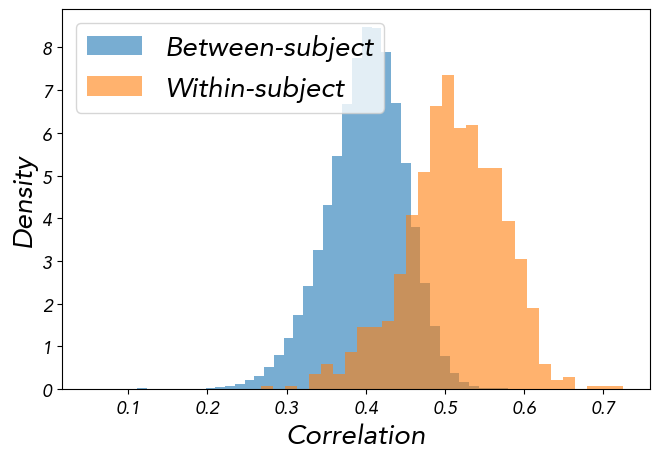

Within-subject:  mean = 0.511 ± 0.061
Between-subject: mean = 0.400 ± 0.050


In [416]:
import numpy as np
import matplotlib.pyplot as plt

diag = np.diag(corr)
offdiag = corr[~np.eye(corr.shape[0], dtype=bool)]

plt.figure(figsize=(7, 5))

plt.hist(offdiag, bins=50, alpha=0.6, density=True, label="Between-subject")
plt.hist(diag, bins=30, alpha=0.6, density=True, label="Within-subject")

plt.xlabel("Correlation")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Within-subject:  mean = {diag.mean():.3f} ± {diag.std():.3f}")
print(f"Between-subject: mean = {offdiag.mean():.3f} ± {offdiag.std():.3f}")

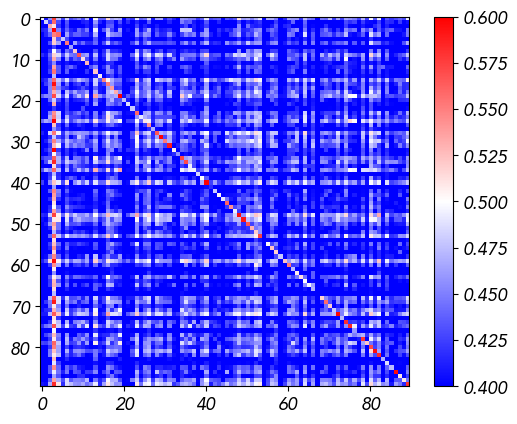

In [417]:
plt.imshow(corr[::10,::10], vmin=.4,vmax=.6, cmap='bwr');
plt.colorbar();

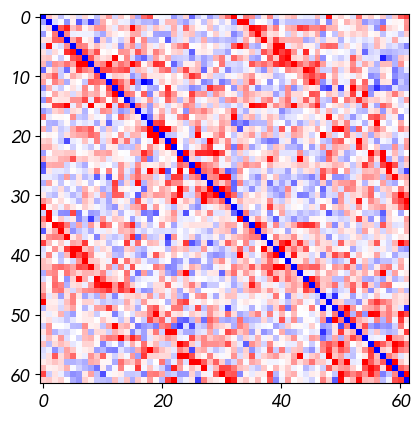

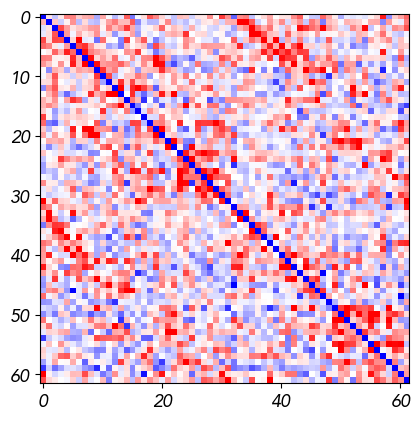

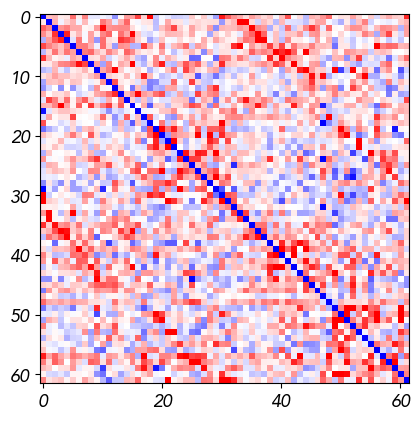

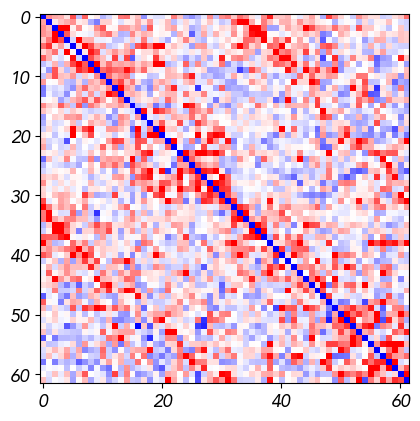

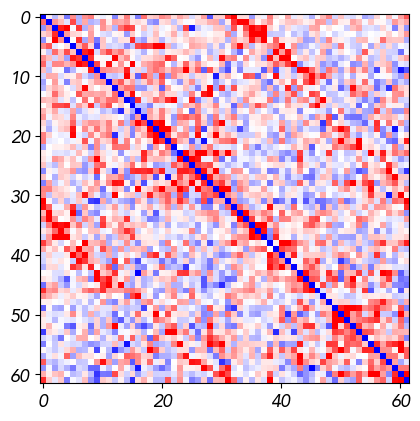

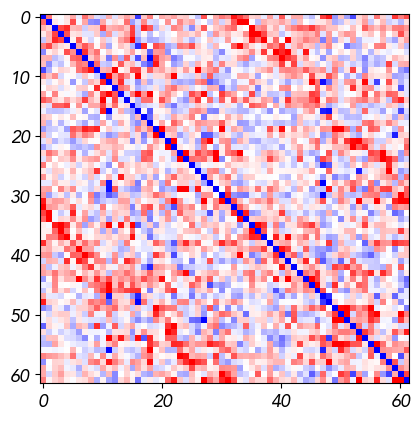

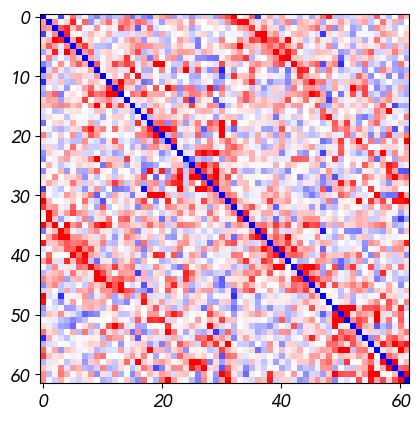

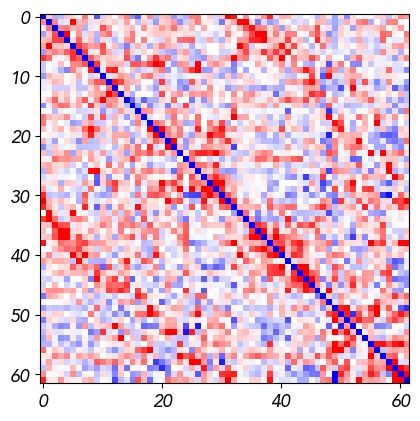

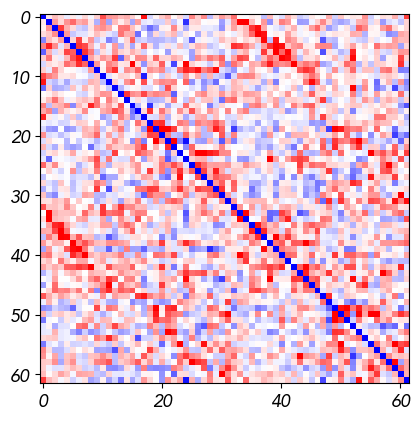

In [399]:
for i in ecs2:
    plt.figure()
    plt.imshow(i, cmap='bwr',vmin=-.1,vmax=.1);

[-1. -1. -1. -1. -1. -1. -1. -1. -1. -1.]


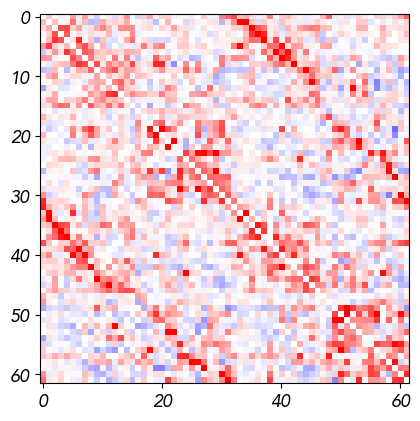

In [395]:
ecs2 = np.asarray(ecs2)
print(1/np.diag(m.J))
plt.imshow(dediag(np.mean(ecs2,0)), cmap='bwr', vmin=-.1, vmax=.1);

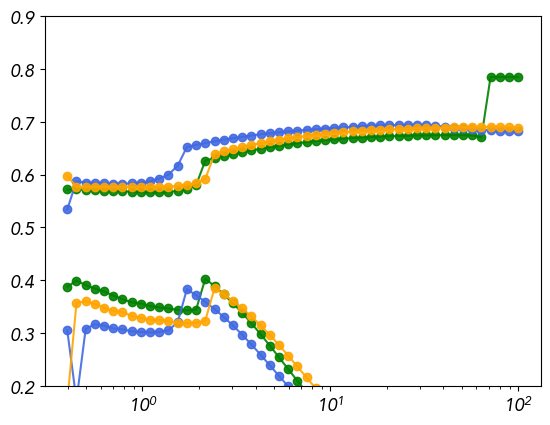

In [364]:
colors=['green','royalblue','orange']
for i in range(3):
    
    plt.plot(taus,-np.asarray(corr[::20]).T[:,i],'-o', alpha=.9,color=colors[i] );
    #plt.plot(taus,-np.mean(np.asarray(corr),0)+0.3,'-o');
    #.mean(np.asarray(corr_),0),'-o');
    #plt.xscale('log');
    #plt.ylim(0.4,0.9)
    #plt.figure()
    
    #plt.plot(taus,np.asarray(corr_[::20]).T[:,i],'-o', alpha=.9, color=colors[i])
    plt.plot(taus,np.asarray(my_info_ec[::20]).T[:,i],'-o', alpha=.9, color=colors[i])
    
    #plt.plot(taus,np.mean(np.asarray(corr_),0),'-o');
    plt.xscale('log');
    plt.ylim(0.2,0.9)

In [366]:
corr.shape

(50, 50)

In [367]:
np.save('../numpy files/regul_C/corr_100.npy', np.asarray(corr))
np.save('../numpy files/regul_C/corr__100.npy', np.asarray(corr_))
np.save('../numpy files/regul_C/my_info_ec_100.npy', np.asarray(my_info_ec))


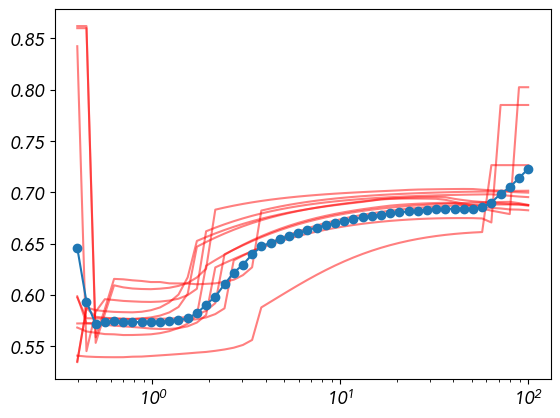

In [334]:
plt.plot(taus,np.asarray(my_info_ec[::5]).T,'-', alpha=.5, color='red');
plt.plot(taus,np.mean(np.asarray(my_info_ec),0),'-o');
plt.xscale('log');


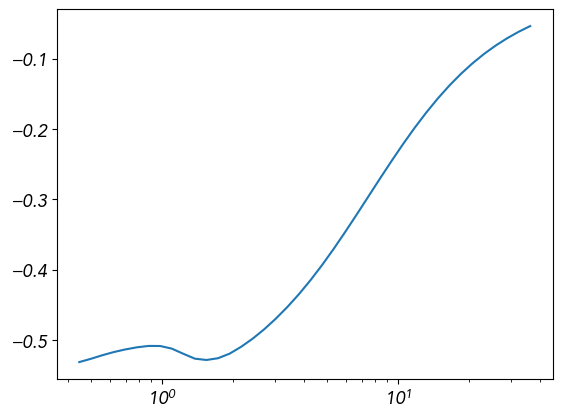

In [190]:
plt.plot(taus,np.mean(corr,0));
plt.xscale('log');

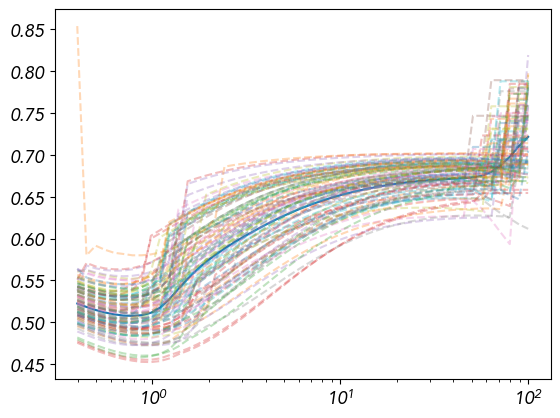

In [257]:
plt.plot(taus,np.mean(my_info_ec,0))
plt.plot(taus,my_info_ec[::10].T,'--', alpha=.3);
;
plt.xscale('log');



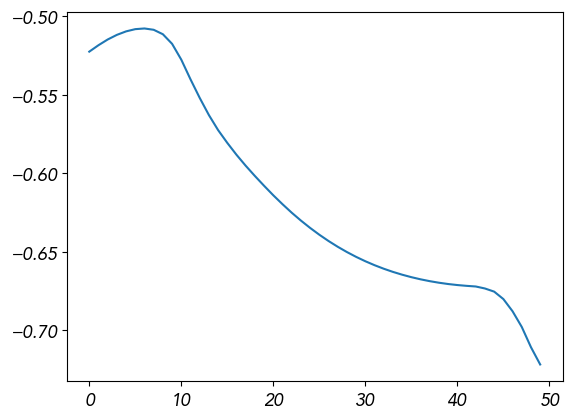

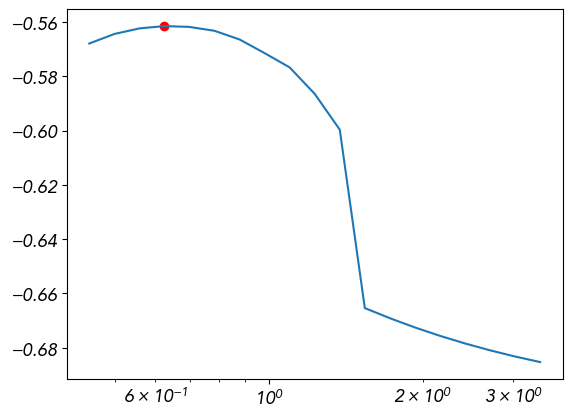

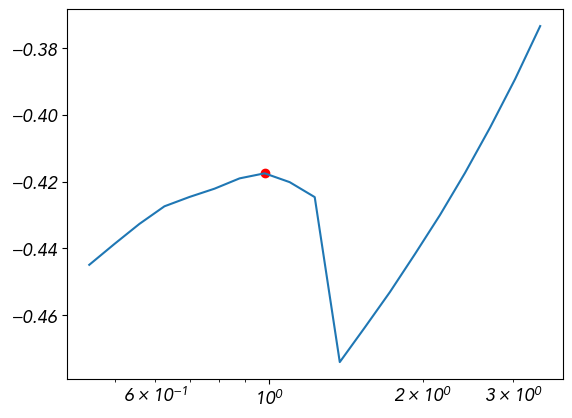

In [249]:
corr = np.asarray(corr)
corr.shape
my_info_ec = np.asarray(my_info_ec)


_2 = np.load('../numpy files/corr_100_1013_log.npy')

to_plot = -my_info_ec
plt.plot(np.nanmean(to_plot,0))
#plt.plot(np.nanmean(_2,0))
to_plot_ = -_2
import numpy as np
from scipy.signal import find_peaks

def first_local_max(x, prominence=0.01):
    peaks, _ = find_peaks(x, prominence=prominence)

    if len(peaks) == 0:
        return np.argmax(x)  # fallback sul massimo globale

    return peaks[0]
taus_est_62=[]
plt.figure()
for _,i in enumerate(to_plot_):
    x = to_plot[_, 1:20]
    idx_peak = first_local_max(x, prominence=0.01)
    
    taus_est_62.append(taus[1:20][idx_peak])
    if _ ==30:
        plt.plot(taus[1:20][idx_peak], x[idx_peak], 'ro');
        plt.plot(taus[1:20], x)
        plt.xscale('log')
    

taus_est_100=[]
plt.figure()
for _,i in enumerate(to_plot_):
    x = to_plot_[_, 1:20]
    idx_peak = first_local_max(x, prominence=0.01)
    
    taus_est_100.append(taus[1:20][idx_peak])
    if _ ==100:
        plt.plot(taus[1:20][idx_peak], x[idx_peak], 'ro');
        plt.plot(taus[1:20], x)
        plt.xscale('log')
    

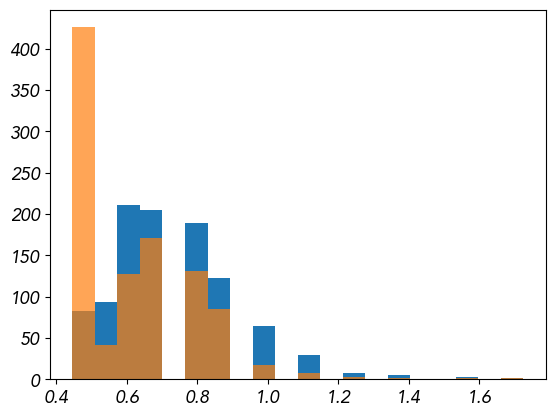

In [234]:
plt.hist(taus_est_62,bins=20)
plt.hist(taus_est_100, alpha =.7, bins=20);


In [222]:
np.save('../numpy files/est_tau_delta.npy', np.asarray(taus_est))
np.save('../numpy files/my_info_ec_1013_62.npy', np.asarray(my_info_ec))


In [221]:
np.min(taus_est),np.min(taus_est_2)
my_info_ec.shape

(1013, 50)

(array([  1.,  25.,  74.,   0., 154.,   0., 167.,   0., 141.,   0., 121.,
          0.,   0.,  83.,   0.,   0.,  45.,   0.,   0.,  25.,   0.,   0.,
          0.,  14.,   0.,   0.,   0.,   7.,   0.,   0.,   0.,   0.,   4.,
          0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0., 151.]),
 array([0.62505519, 0.68041852, 0.73578186, 0.79114519, 0.84650852,
        0.90187185, 0.95723518, 1.01259851, 1.06796185, 1.12332518,
        1.17868851, 1.23405184, 1.28941517, 1.3447785 , 1.40014183,
        1.45550517, 1.5108685 , 1.56623183, 1.62159516, 1.67695849,
        1.73232182, 1.78768516, 1.84304849, 1.89841182, 1.95377515,
        2.00913848, 2.06450181, 2.11986515, 2.17522848, 2.23059181,
        2.28595514, 2.34131847, 2.3966818 , 2.45204513, 2.50740847,
        2.5627718 , 2.61813513, 2.67349846, 2.72886179, 2.78422512,
        2.83958846, 2.89495179, 2.95031512, 3.00567845, 3.06104178,
        3.11640511, 3.17176845, 3.22713178, 3.

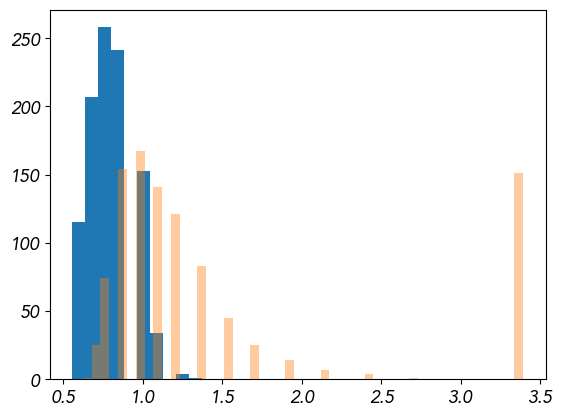

In [207]:
plt.hist(taus_est, bins=10)
plt.hist(taus_est_2, bins=50,alpha =.4);

In [347]:
my_info_ec =np.asarray(my_info_ec[:])
corr_plus =np.asarray(corr_plus[:])

my_info_ec_sym =np.asarray(my_info_ec_sym[:])

my_info = np.asarray(my_info[:])
corr = np.asarray(corr[:])
corr_ = np.asarray(corr_[:])
corr_plus = np.asarray(corr_plus[:])


TypeError: list indices must be integers or slices, not tuple

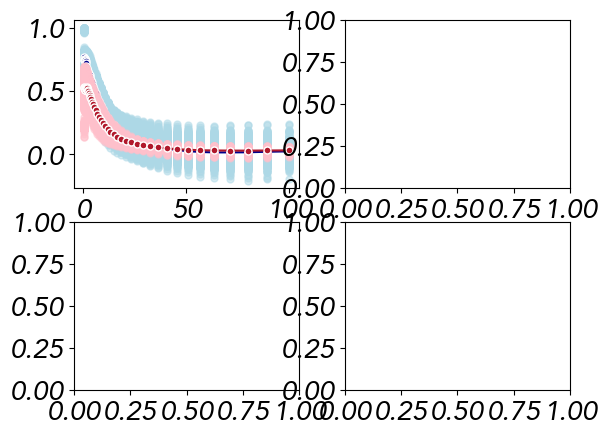

In [179]:
# Mean curve, excluding first trivial point
from matplotlib import cm
alpha=.5
fig,axes = plt.subplots(2,2)
cmap_div = cm.RdBu_r
cmap_blue = cm.Blues
plt.rcParams['xtick.labelsize']=13
plt.rcParams['ytick.labelsize']=13

colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))

# Individual correlations with precision matrix
axes[0,0].plot(
    taus,
    corr_.T,
    'o',
    markersize=5,
    color='lightblue',
    alpha=alpha
)
# Colors used in panel (i)
axes[0,0].plot(
    taus[:],
    np.nanmean(corr_,0),
    '-o',
    ms=5,
    color='darkblue',
    markeredgecolor='white',
    label=r"X = $Q_0$"
)






# Mean curve, excluding first trivial point

# Individual correlations with precision matrix
axes[0,0].plot(
    taus,
    -corr.T,
    'o',
    markersize=5,
    color='pink',
    alpha=alpha
)
# Mean curve, excluding first trivial point
axes[0,0].plot(
    taus,
    -np.nanmean(corr,0),
    '-o',
    ms=5,
    color=colors[9],
    markeredgecolor='white',
    label=r"X = $-\Sigma Q_0^{-1}$"
)





# Mean curve, excluding first trivial point

# Individual correlations with precision matrix
axes[0,1].plot(
    taus,
    my_info_ec[::50,:].T,
    '-',
    markersize=1,
    color='gray',
    #alpha=0.5
)
# Mean curve, excluding first trivial point
axes[0,1].plot(
    taus,
    np.nanmean(my_info_ec,0),
    '-o',
    ms=5,
    color=colors[9],
    markeredgecolor='white',
    label=r"X = $-\Sigma Q_0^{-1}$"
)



# Individual correlations with precision matrix
axes[1,0].plot(
    taus,
    corr_plus[:,:].T,
    '-.',
    markersize=5,
    color='pink',
    alpha=0.5
)
# Mean curve, excluding first trivial point
axes[1,0].plot(
    taus,
    np.nanmean(corr_plus,0),
    '-o',
    ms=5,
    color=colors[9],
    markeredgecolor='white',
    label=r"X = $-\Sigma Q_0^{-1}$"
)


norm = np.asarray(norm)
distances=np.asarray(distances)

# Individual correlations with precision matrix
axes[1,1].plot(
    taus,
    distances[::20,:].T,
    '-',lw=.7,
    markersize=5,
    color='gray', #alpha=.3
)

# Mean curve, excluding first trivial point
axes[1,1].plot(
    taus,
    np.nanmean(distances[::100],0),
    '-o',
    ms=5,
    color=colors[9],
    markeredgecolor='white',
    label=r"X = $-\Sigma Q_0^{-1}$"
)

axes[0,0].set_xscale('log')
axes[1,0].set_xscale('log')
axes[0,1].set_xscale('log')
axes[1,1].set_xscale('log')
axes[1,1].set_ylim(0.5,1.)

axes[0,0].set_xlim(0,40)
axes[1,0].set_xlim(0,40)
axes[1,1].set_xlim(0.,5)

In [413]:
corr_S_Q1asym.shape

(1013, 50)

/tmp/ipykernel_8620/3443649510.py:110: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  axes[0,0].set_xlim(0,40)
/tmp/ipykernel_8620/3443649510.py:111: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  axes[1,0].set_xlim(0,40)


(0.0, 1.2)

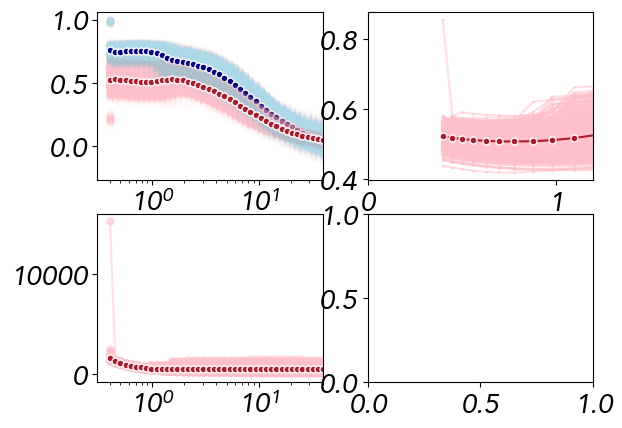

In [401]:
# Mean curve, excluding first trivial point
from matplotlib import cm
alpha=.01
fig,axes = plt.subplots(2,2)
cmap_div = cm.RdBu_r
cmap_blue = cm.Blues

colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))

# Individual correlations with precision matrix
axes[0,0].plot(
    taus,
    corr_.T,
    'o',
    markersize=5,
    color='lightblue',
    alpha=alpha
)
# Colors used in panel (i)
axes[0,0].plot(
    taus[:],
    np.nanmean(corr_,0),
    '-o',
    ms=5,
    color='darkblue',
    markeredgecolor='white',
    label=r"X = $Q_0$"
)






# Mean curve, excluding first trivial point

# Individual correlations with precision matrix
axes[0,0].plot(
    taus,
    -corr.T,
    'o',
    markersize=5,
    color='pink',
    alpha=alpha
)
# Mean curve, excluding first trivial point
axes[0,0].plot(
    taus,
    -np.nanmean(corr,0),
    '-o',
    ms=5,
    color=colors[9],
    markeredgecolor='white',
    label=r"X = $-\Sigma Q_0^{-1}$"
)





# Mean curve, excluding first trivial point

# Individual correlations with precision matrix
axes[0,1].plot(
    taus,
    my_info_ec.T,
    '-o',
    markersize=1,
    color='pink',
    alpha=0.5
)
# Mean curve, excluding first trivial point
axes[0,1].plot(
    taus,
    np.nanmean(my_info_ec,0),
    '-o',
    ms=5,
    color=colors[9],
    markeredgecolor='white',
    label=r"X = $-\Sigma Q_0^{-1}$"
)



# Individual correlations with precision matrix
axes[1,0].plot(
    taus,
    my_info[::10,:].T,
    '-o',
    markersize=5,
    color='pink',
    alpha=0.5
)
# Mean curve, excluding first trivial point
axes[1,0].plot(
    taus,
    np.nanmean(my_info,0),
    '-o',
    ms=5,
    color=colors[9],
    markeredgecolor='white',
    label=r"X = $-\Sigma Q_0^{-1}$"
)

axes[0,0].set_xscale('log')
axes[1,0].set_xscale('log')
#axes[0,1].set_xscale('log')

axes[0,0].set_xlim(0,40)
axes[1,0].set_xlim(0,40)
axes[0,1].set_xlim(0.,1.2)
#plt.xlim(0,10)

In [228]:
my_info.shape

(102, 50)

In [201]:
import numpy as np
from scipy.signal import find_peaks

def first_local_max(x, prominence=0.01):
    peaks, _ = find_peaks(x, prominence=prominence)

    if len(peaks) == 0:
        return np.argmax(x)  # fallback sul massimo globale

    return peaks[0]

to_plot = corr_
to_plot_ = -my_info_ec

taus_est_2=[]

for _,i in enumerate(to_plot_):
    x = to_plot[_, 1:20]
    idx_peak = first_local_max(x, prominence=0.01)
    
    taus_est_2.append(taus[1:20][idx_peak])


taus_est=[]
for _,i in enumerate(to_plot_):
    x = to_plot_[_, 1:20]
    idx_peak = first_local_max(x, prominence=0.01)
    
    taus_est.append(taus[1:20][idx_peak])

to_plot3 = corr
taus_est3=[]
for _,i in enumerate(to_plot_):
    x = to_plot3[_, 1:20]
    idx_peak = first_local_max(x, prominence=0.01)
    
    taus_est3.append(taus[1:20][idx_peak])

np.float64(0.7871793465585007)

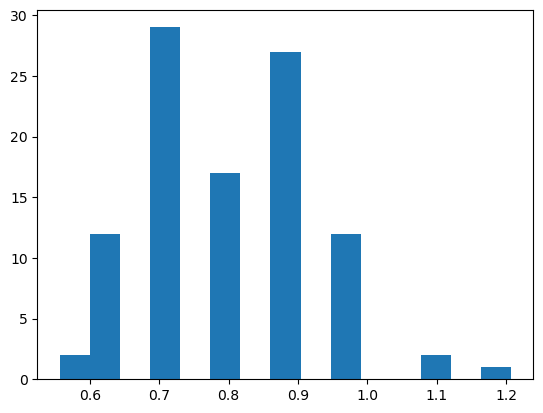

In [232]:
plt.hist(taus_est, bins=15);
np.mean(taus_est)

In [405]:
norm_1  = np.random.normal(0,1,np.shape(taus_est_2))
norm_2 = np.random.normal(0,1,np.shape(taus_est_2))

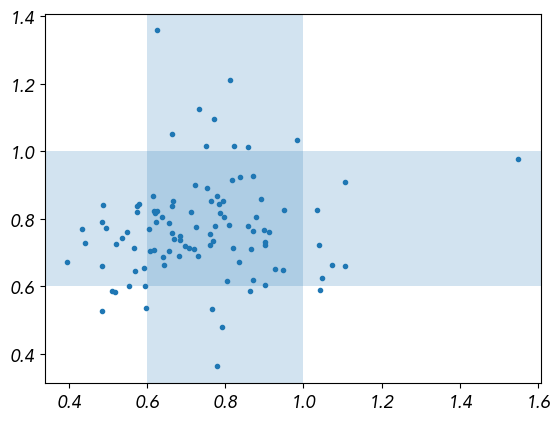

In [411]:
plt.plot(taus_est_2+0.1*norm_1, taus_est+0.1*norm_2,'.');
plt.axvspan(0.6,1,alpha=0.2)
plt.axhspan(0.6,1,alpha=0.2);
#plt.xlim(0,2)
#plt.ylim(0,2);

In [418]:
np.median(taus_est_2), np.median(taus_est)

(np.float64(0.6947630846322991), np.float64(0.7758824319047037))

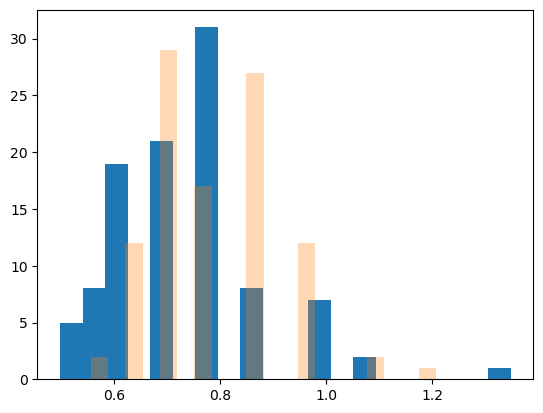

In [203]:
plt.hist(taus_est_2,bins=20)# alpha=.3)
plt.hist(taus_est, alpha=.3, bins=20);
#plt.hist(taus_est3, alpha=.3, bins=20);




/tmp/ipykernel_8620/2377684921.py:27: RuntimeWarning: Mean of empty slice
  -np.nanmean(corr[:2],0),
/tmp/ipykernel_8620/2377684921.py:43: RuntimeWarning: Mean of empty slice
  np.nanmean(corr_[:2],0),
/tmp/ipykernel_8620/2377684921.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


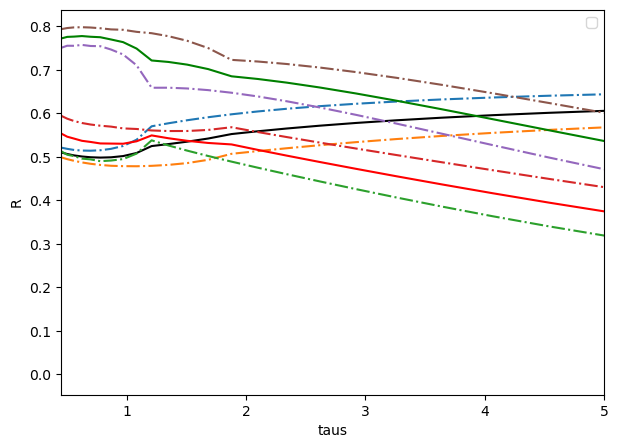

In [164]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(taus,np.asarray(my_info_ec[:2]).T,'-.',)
ax.plot(taus,np.nanmean(my_info_ec[:2],0),'k-',)

ax.plot(taus,-np.asarray(corr[:2]).T,'-.',)
ax.plot(taus,-np.nanmean(corr[:2],0),'r-',)

ax.plot(taus, np.asarray(corr_[:2]).T, '-.',)
ax.plot(taus, np.nanmean(corr_[:2],0), 'g-', )

plt.ylabel('R')
plt.xlabel('taus')
#plt.vlines(1.38,0,1,color='red', label ='convergence limit')
plt.xlim(0.45,5)
#plt.ylim(0.3,.75)
plt.legend()

/tmp/ipykernel_8620/2965671684.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


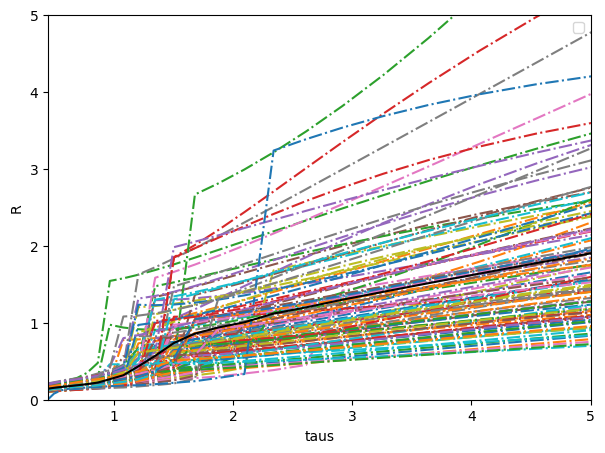

In [241]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.plot(taus, np.asarray(neq_to_diss_ratio[:]).T,
    '-.',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
ax.plot(taus,np.nanmean(neq_to_diss_ratio[:],0),'k-',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
plt.ylabel('R')
plt.xlabel('taus')
#plt.vlines(1.38,0,1,color='red', label ='convergence limit')
plt.xlim(0.45,5)
plt.ylim(0,5)
plt.legend()

/tmp/ipykernel_8620/1851655763.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


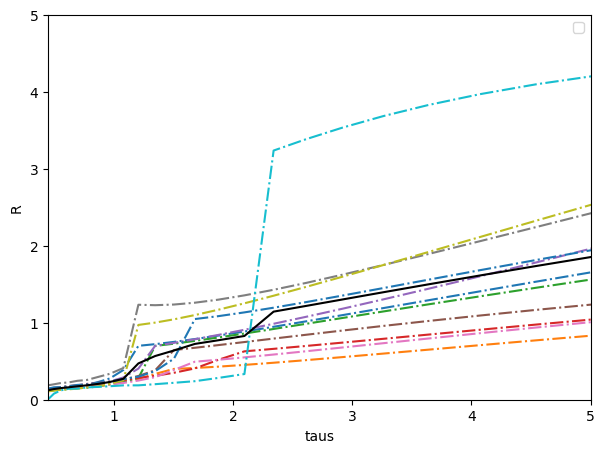

In [151]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.plot(taus, np.asarray(neq_to_diss_ratio[:11]).T,
    '-.',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
ax.plot(taus,np.nanmean(neq_to_diss_ratio[:11],0),'k-',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
plt.ylabel('R')
plt.xlabel('taus')
#plt.vlines(1.38,0,1,color='red', label ='convergence limit')
plt.xlim(0.45,5)
plt.ylim(0,5)
plt.legend()

/tmp/ipykernel_8620/4164916763.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


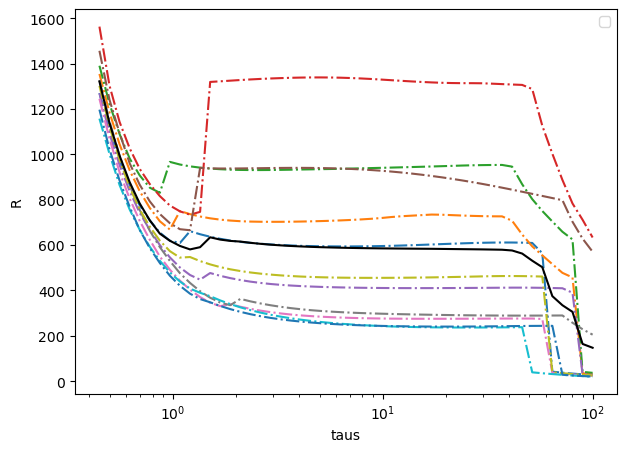

In [171]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.plot(
    taus,
    np.asarray(my_info[:11]).T,
    '-.',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
ax.plot(
  taus,
    np.nanmean(my_info[:11],0),
    'k-',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
plt.xscale('log');
plt.ylabel('R')
plt.xlabel('taus')
#plt.vlines(1.38,0,1,color='red', label ='convergence limit')
#plt.xlim(0.45,80)
#plt.ylim(0.4,1)
plt.legend()


/tmp/ipykernel_8620/843910552.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


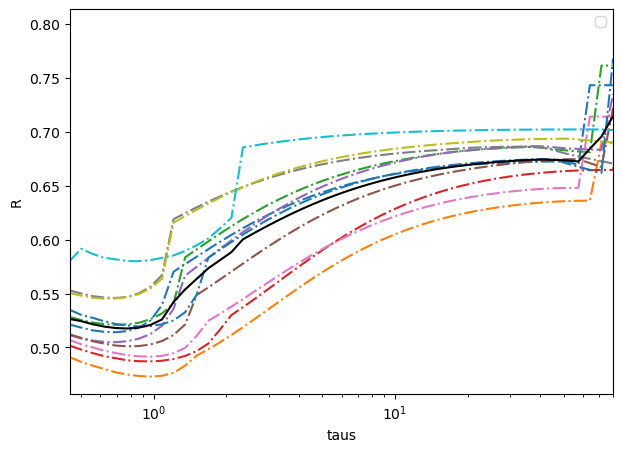

In [146]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.plot(
    taus,
    np.asarray(my_info_ec[:11]).T,
    '-.',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
ax.plot(
    taus,
    np.nanmean(my_info_ec[:11],0),
    'k-',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
plt.xscale('log');
plt.ylabel('R')
plt.xlabel('taus')
#plt.vlines(1.38,0,1,color='red', label ='convergence limit')
plt.xlim(0.45,80)
#plt.ylim(0.4,1)
plt.legend()


/tmp/ipykernel_8620/2553358127.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


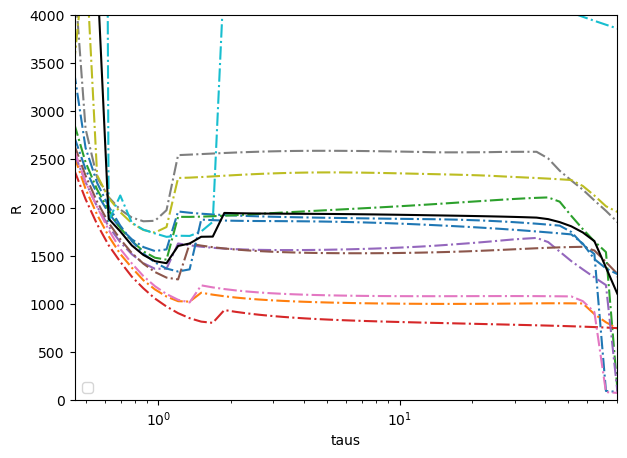

In [126]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.plot(
    taus,
    np.asarray(my_info_ec[:11]).T,
    '-.',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
ax.plot(
    taus,
    np.nanmean(my_info_ec[:11],0),
    'k-',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
plt.xscale('log');
plt.ylabel('R')
plt.xlabel('taus')
#plt.vlines(1.38,0,1,color='red', label ='convergence limit')
plt.xlim(0.45,80)
plt.ylim(0,4000)
plt.legend()


/tmp/ipykernel_8620/1029179640.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


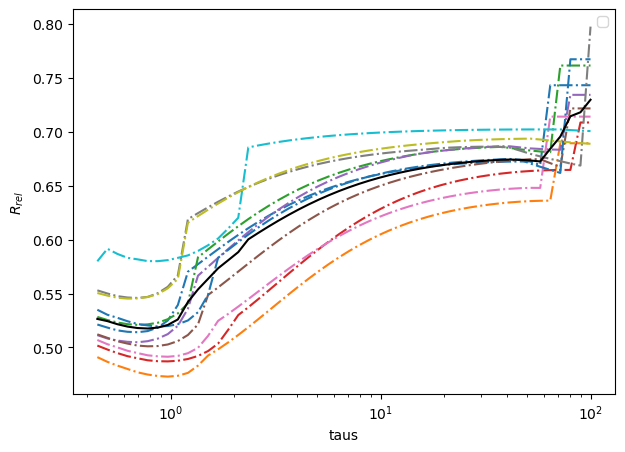

In [137]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.plot(
    taus,
    np.asarray(my_info_ec[:11]).T,
    '-.',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
ax.plot(
    taus,
    np.mean(my_info_ec[:11],0),
    'k-',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
plt.xscale('log');
plt.ylabel(r'$R_{rel}$')
plt.xlabel('taus')
#plt.vlines(1.38,0,1,color='red', label ='convergence limit')
#plt.xlim(0.4,100)
#plt.ylim(0,.1)
plt.legend()

#plt.xlabel('')


/tmp/ipykernel_8620/1591082673.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


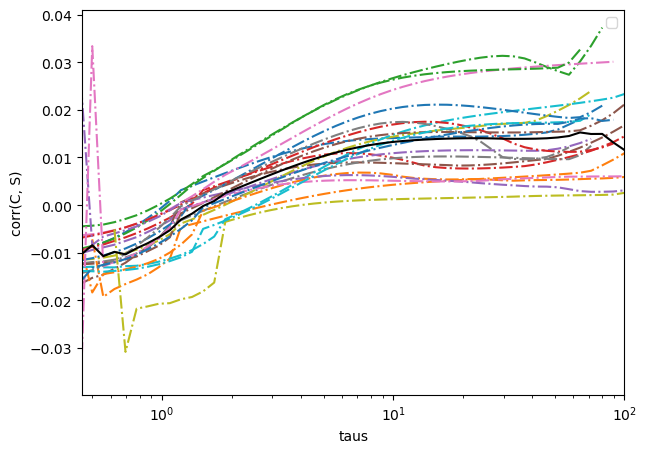

In [104]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.plot(
    taus,
    np.asarray(my_info_ec[::5]).T,
    '-.',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
ax.plot(
    taus,
    np.nanmean(my_info_ec[::5],0),
    'k-',
    #label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)
plt.xscale('log');
plt.ylabel('corr(C, S)')
plt.xlabel('taus')
#plt.vlines(1.38,0,1,color='red', label ='convergence limit')
plt.xlim(0.45,100)
#plt.ylim(0,.1)
plt.legend()

#plt.xlabel('')


/tmp/ipykernel_1239/1816083458.py:34: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0,3);


(0.0, 3.0)

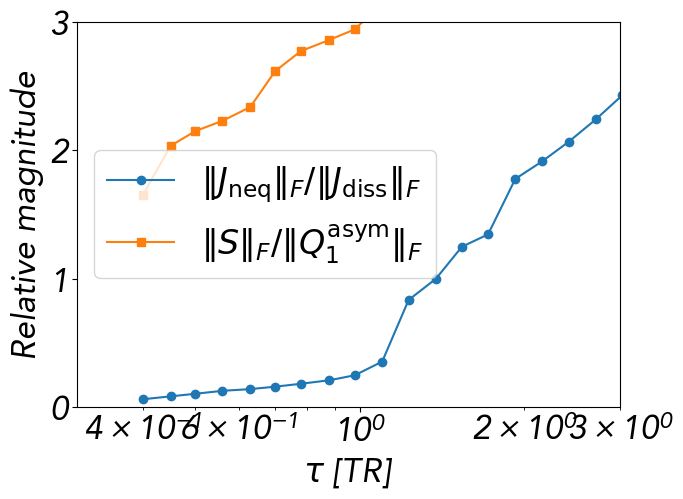

In [165]:
mean_neq_to_diss = np.nanmean(
    neq_to_diss_ratio,
    axis=0
)

mean_S_amplitude = np.nanmean(
    S_amplitude_ratio,
    axis=0
)

fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.plot(
    taus,
    mean_neq_to_diss,
    '-o',
    label=r'$\|J_{\mathrm{neq}}\|_F / \|J_{\mathrm{diss}}\|_F$'
)

ax.plot(
    taus,
    mean_S_amplitude,
    '-s',
    label=r'$\|S\|_F / \|Q_1^{\mathrm{asym}}\|_F$'
)

ax.set_xscale('log')
ax.set_xlabel(r'$\tau$ [TR]')
ax.set_ylabel('Relative magnitude')
ax.legend()

plt.xlim(0,3);
plt.ylim(0,3)

In [282]:
corrshape

NameError: name 'corrshape' is not defined

In [ ]:
## farlo con Schaefer 100

In [110]:
corr100.shape

(102, 50)

# Final figure

In [114]:
ls '../numpy files/'*my_info_ec*

'../numpy files/my_info_ec_1013_100.npy'
'../numpy files/my_info_ec_1013_62.npy'


/tmp/ipykernel_47671/3450605126.py:45: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False)


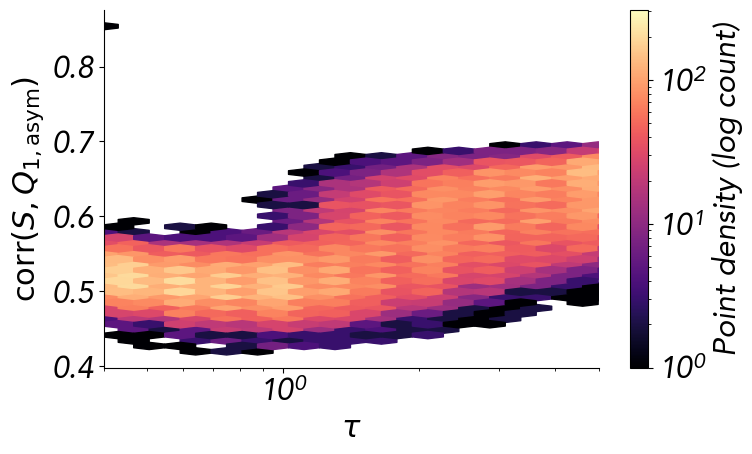

In [121]:
import numpy as np
import matplotlib.pyplot as plt

Y = np.asarray(my_info_ec)   # (n_subjects, n_parameters)
params = np.asarray(params)     # valori reali positivi, per esempio 0.01, 0.1, 1, 10

X = np.tile(params, Y.shape[0])
Y_flat = Y.ravel()

valid = (
    np.isfinite(X)
    & np.isfinite(Y_flat)
    & (X > 0)
)

fig, ax = plt.subplots(figsize=(8, 5))

hb = ax.hexbin(
    X[valid],
    Y_flat[valid],
    gridsize=(35, 30),
    xscale="log",          # bin uniformi in log10(x)
    cmap="magma",
    mincnt=1,
    bins="log"             # colore proporzionale al log del conteggio
)

#mean = np.nanmean(Y, axis=0)
q05, q95 = np.nanpercentile(Y, [5, 95], axis=0)

#ax.fill_between(
#    params, q05, q95,
#    color="cyan", alpha=0.2,
#    label="5th–95th percentile"
#)
#ax.plot(params, mean, color="cyan", lw=2.5, label="Mean")

ax.set_xscale("log")

cbar = fig.colorbar(hb, ax=ax)
cbar.set_label("Point density (log count)")

ax.set_xlabel(r"$\tau$")
ax.set_ylabel(r"$\mathrm{corr}(S,Q_{1,\mathrm{asym}})$")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(.4,5)
plt.tight_layout()
plt.show()

(0.4, 15)

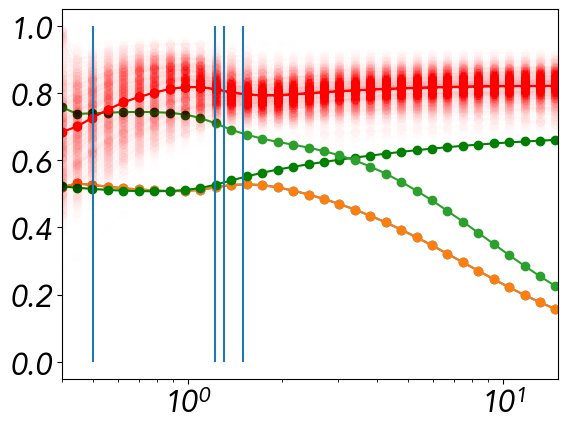

In [106]:
taus = np.logspace(-.4,2,)
plt.plot(taus,np.nanmean(corr100,0),'-o');
plt.plot(taus,np.nanmean(corr100,0),'-o');
plt.plot(taus,np.nanmean(my_info_ec,0),'g-o');
plt.plot(taus,np.nanmean(corr100_,0),'-o');
plt.plot(taus,np.nanmean(corr_S_Q1asym,0),'r-o');
plt.plot(taus,corr_S_Q1asym.T,'r-o',alpha=.005);

plt.xscale('log')
plt.vlines(1.22,0.,1)
plt.vlines(1.3,0.,1)

plt.vlines(1.5,0.,1)
plt.vlines(.5,0.,1)
plt.xlim(.4,15)

In [84]:
corr100= -np.load('../numpy files/corr_62_1013_log.npy')
corr100_= np.load('../numpy files/corr__62_1013_log.npy')
ass100= np.load('../numpy files/ass_62_1013_log.npy')
print(ass100.shape)

corr_S_Q1asym = np.load('../numpy files/corr_S_Q1asym_62_1013_log.npy')
print(corr_S_Q1asym.shape)
my_info_ec = np.load('../numpy files/my_info_ec_1013_62.npy')

(1013, 50)
(1013, 50)


In [298]:
labels100=[]
for i in labels:
    labels100.append(i[10:])

In [113]:
plt.rcParams['xtick.labelsize'] = 20
plt.rcParams['ytick.labelsize'] = 20


In [125]:
taus = np.logspace(-.35,2)
taus[0]

np.float64(0.44668359215096315)

Mapping: (100,) range = 1 - 62
62
62
62
62
62
62
Automatic sweet spot: 0.45 1.54
Plotted sweet spot: 0.45 1.54


<Figure size 2100x1800 with 0 Axes>

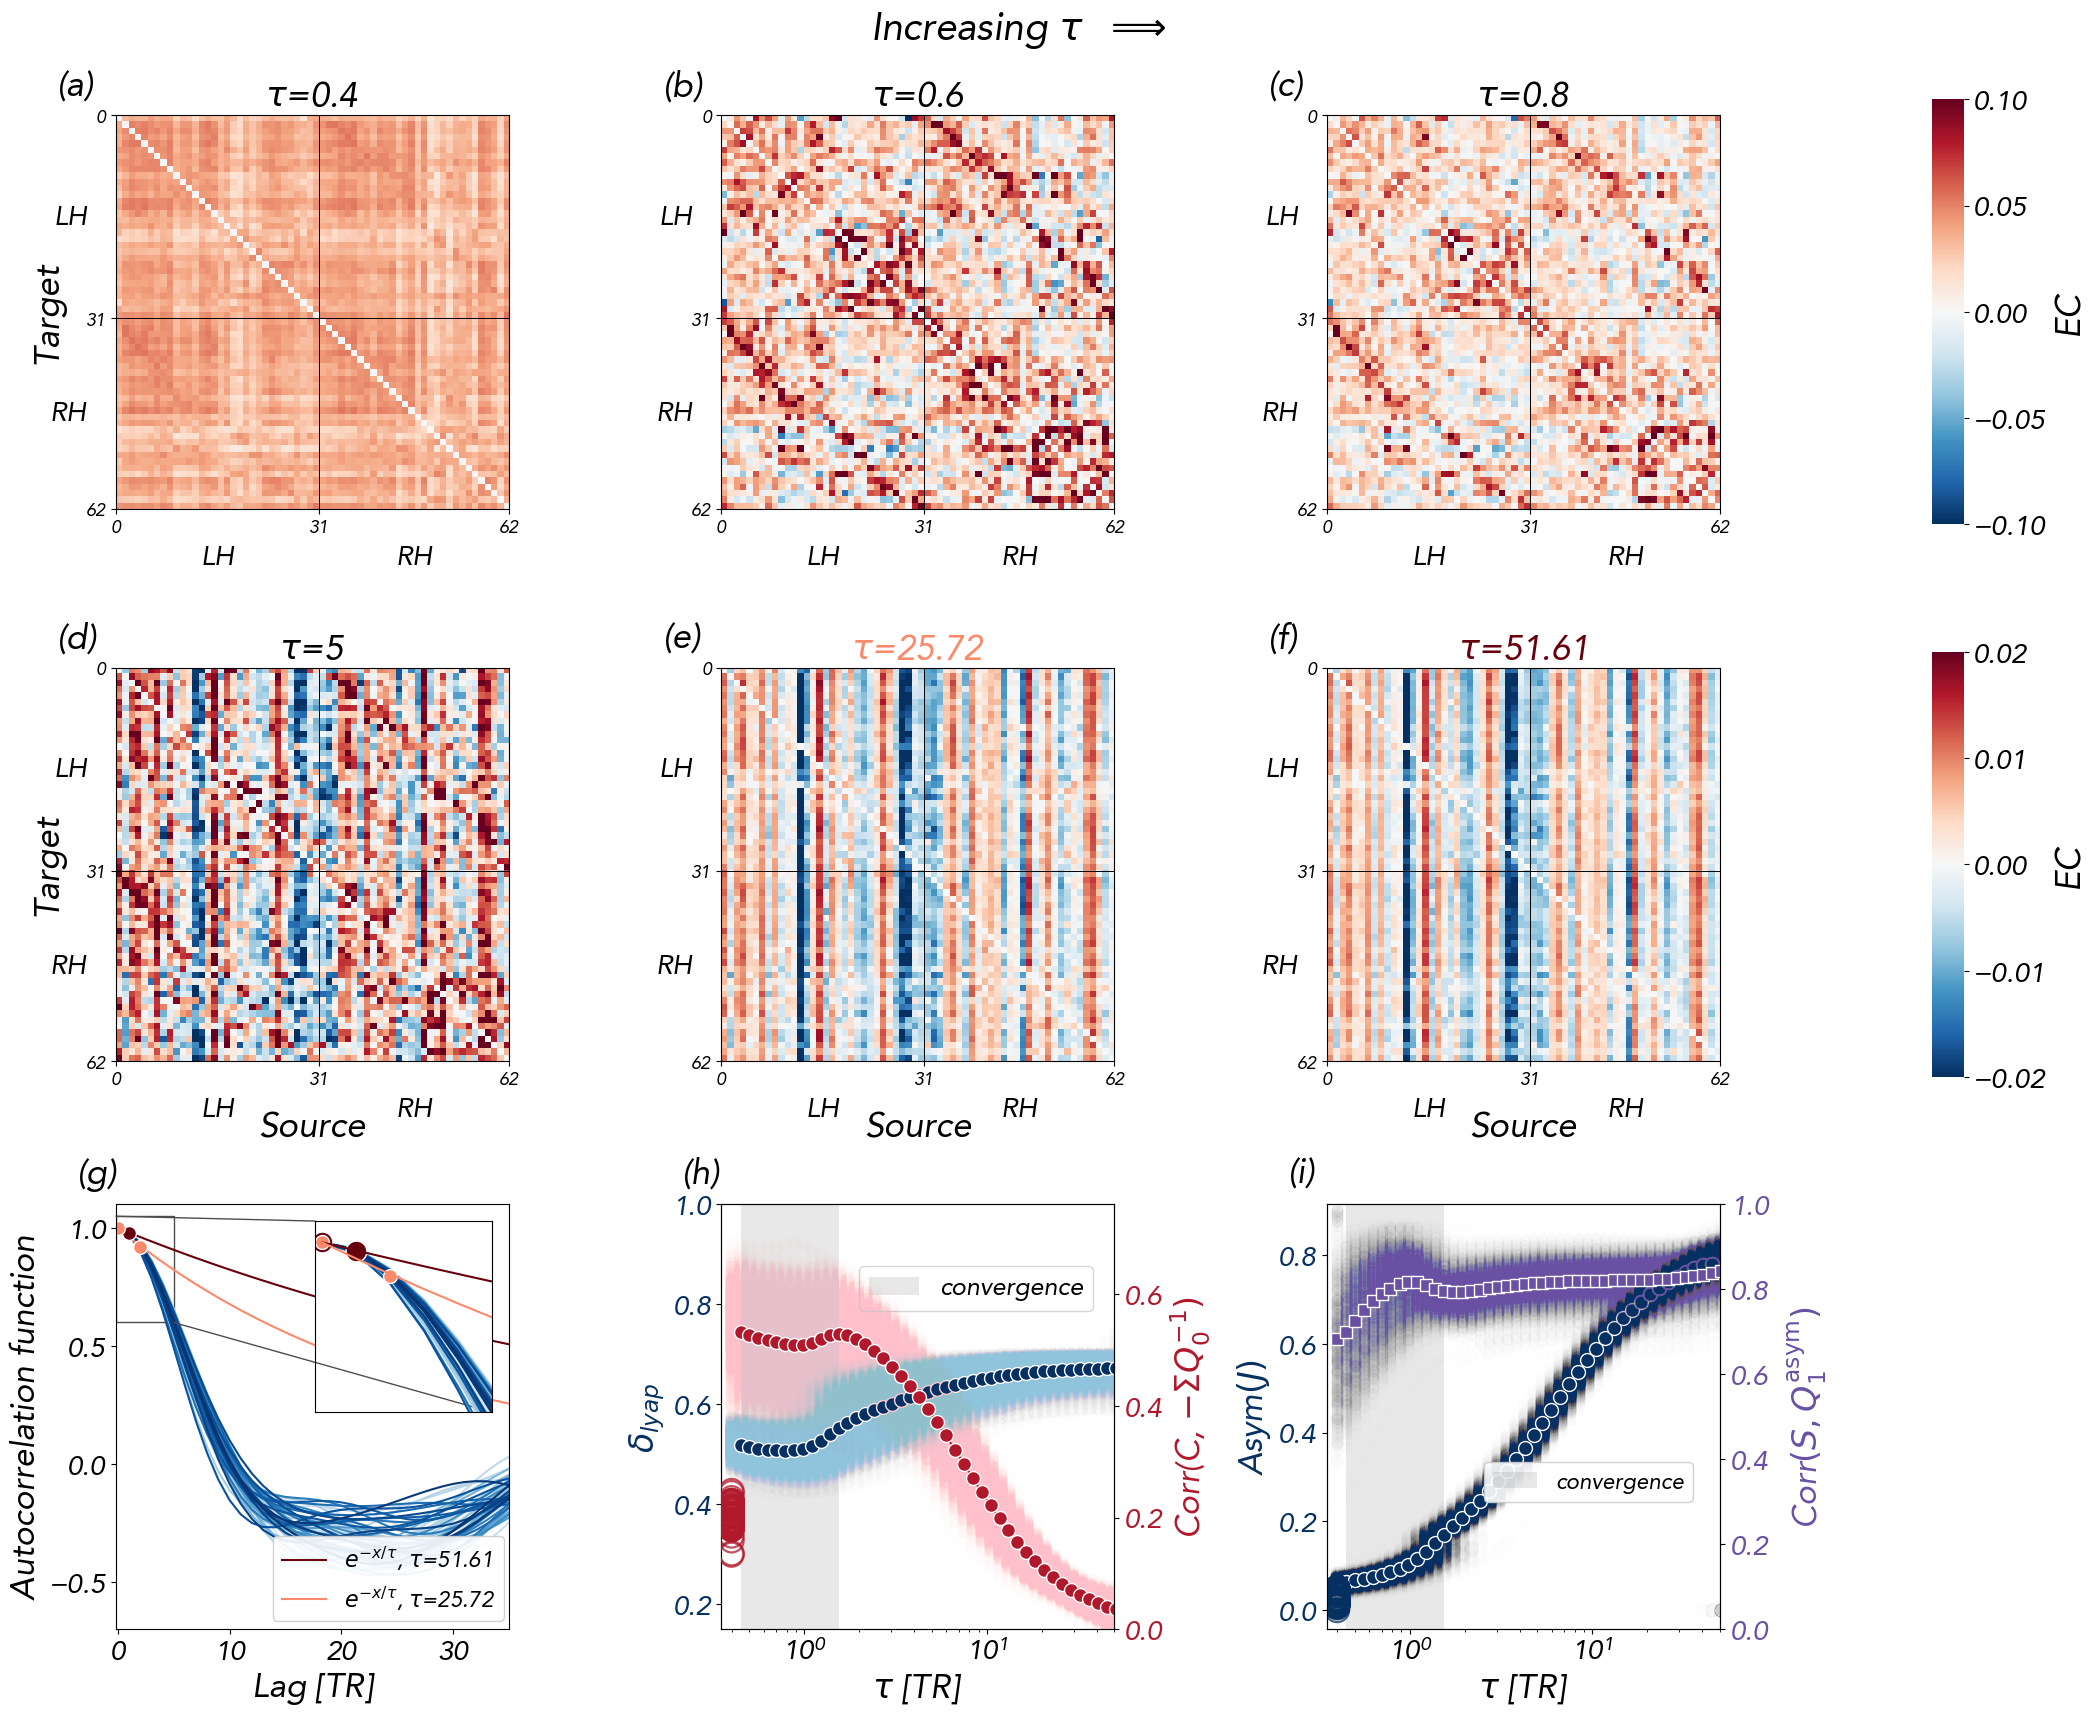

In [190]:
taus = np.logspace(-.35,2)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from collections import OrderedDict
alpha = 0.005
# ==========================================================
# STYLE
# ==========================================================

vmin = min(np.percentile(js[i], 2) for i in range(6))
vmax = max(np.percentile(js[i], 98) for i in range(6))

plt.rcParams['font.size'] = 24
fontsize = 25

cmap_div = cm.RdBu_r
cmap_blue = cm.Blues

colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))

# Colors used in panel (i)
asym_color = colors[0]
directionality_color = cm.Purples(0.75)


# ==========================================================
# THRESHOLDS FOR THE FIRST TAU POINT
# ==========================================================

q0_threshold = 0.7
precision_threshold = 0.25
asymmetry_threshold = 0.05
delta_threshold = 0.05


highlight_size = 300
highlight_linewidth = 1.6
highlight_alpha = 0.75


# ==========================================================
# FUNCTION TO IDENTIFY THE SWEET SPOT
# ==========================================================

def get_sweet_spot(
    taus,
    correlation,
    fraction_of_peak=0.87
):
    """
    Return the contiguous tau interval around the maximum correlation
    for which the curve remains above a specified fraction of its peak.
    """

    taus = np.asarray(taus, dtype=float)
    correlation = np.asarray(correlation, dtype=float)

    valid = np.isfinite(taus) & np.isfinite(correlation)

    taus_valid = taus[valid]
    corr_valid = correlation[valid]

    if len(taus_valid) == 0:
        return np.nan, np.nan

    peak_index = np.nanargmax(corr_valid)
    peak_value = corr_valid[peak_index]

    threshold = fraction_of_peak * peak_value
    high_mask = corr_valid >= threshold

    left_index = peak_index

    while left_index > 0 and high_mask[left_index - 1]:
        left_index -= 1

    right_index = peak_index

    while (
        right_index < len(corr_valid) - 1
        and high_mask[right_index + 1]
    ):
        right_index += 1

    return (
        taus_valid[left_index],
        taus_valid[right_index]
    )


# ==========================================================
# CONVERT RESULTS TO ARRAYS
# ==========================================================

corr100 = np.asarray(corr100, dtype=float)
corr100_ = np.asarray(corr100_, dtype=float)
ass100 = np.asarray(ass100, dtype=float)

# New directional measure:
# corr(S, Q1_asym), shape = subjects x taus
corr_S_Q1asym = np.asarray(
    corr_S_Q1asym,
    dtype=float
)


# ==========================================================
# FIGURE + GRID
# ==========================================================

fig = plt.figure(
    figsize=(21, 18),
    constrained_layout=False
)

fig.suptitle(
    r'Increasing $\tau$  $\Longrightarrow$',
    fontsize=28,
    fontweight='bold',
    y=0.98
)

gs = gridspec.GridSpec(
    3,
    4,
    height_ratios=[1, 1, 1],
    width_ratios=[1, 1, 1, 0.08],
    hspace=0.30,
    wspace=0.7
)


# ==========================================================
# (a)-(f): EC MATRICES
# ==========================================================

panel_labels = [
    '(a)', '(b)', '(c)',
    '(d)', '(e)', '(f)'
]
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from collections import OrderedDict
import numpy as np
import matplotlib.pyplot as plt
from collections import OrderedDict, Counter

# ============================================================
# MAPPING: SCHAEFER 100 -> 62 PARCELS
# ============================================================

mapping_100_to_62 = np.array([
     1,  2,  2,  2,  2,  2,  2,  2,  2,  3,
     3,  3,  4,  5,  5,  6,  7,  8,  7,  8,
     7,  9,  9, 10, 11, 12, 13, 14, 15, 16,
    17, 18, 19, 20, 21, 22, 23, 24, 24, 25,
    24, 26, 27, 28, 29, 28, 30, 31, 32, 32,
    33, 34, 34, 34, 35, 35, 34, 35, 36, 36,
    36, 37, 38, 38, 38, 38, 39, 40, 41, 41,
    42, 43, 43, 44, 45, 46, 47, 47, 48, 49,
    50, 51, 52, 52, 53, 52, 54, 55, 54, 56,
    57, 58, 58, 59, 59, 60, 60, 61, 62, 62
])

print("Mapping:", mapping_100_to_62.shape,
      "range =", mapping_100_to_62.min(), "-", mapping_100_to_62.max())


# ============================================================
# AGGREGATE FC: 100 x 100 -> 62 x 62
# ============================================================

def aggregate_fc(fc_100, mapping=mapping_100_to_62):

    fc_62 = np.full((62, 62), np.nan)

    for i in range(1, 63):
        ii = np.where(mapping == i)[0]

        for j in range(1, 63):
            jj = np.where(mapping == j)[0]

            fc_62[i-1, j-1] = np.nanmean(
                fc_100[np.ix_(ii, jj)]
            )

    return fc_62


# ============================================================
# AGGREGATE SCHAEFER LABELS: 100 -> 62
#
# Assumes labels like:
# LH_Vis_...
# LH_Default_...
# RH_Cont_...
# ============================================================

def aggregate_labels(labels_100, mapping=mapping_100_to_62):

    labels_100 = np.asarray(labels_100)
    labels_62 = []

    for k in range(1, 63):

        idx = np.where(mapping == k)[0]
        labs = labels_100[idx]

        hemis = [str(x).split("_")[0] for x in labs]
        nets  = [str(x).split("_")[1] for x in labs]

        # majority hemisphere/network
        hemi = Counter(hemis).most_common(1)[0][0]
        net  = Counter(nets).most_common(1)[0][0]

        labels_62.append(f"{hemi}_{net}_{k}")

    return np.array(labels_62)


# ============================================================
# PLOT
# ============================================================

def plot_fc_matrix(
    fc, labels, ax,
    cmap="bwr",
    vmin=-0.2,
    vmax=0.2,
    fontsize=13,
    pos=7,
    plot_networks=False,
    plot_emi_x=True,
    plot_emi_y=True
):

    labels = np.asarray(labels)

    def parse_label(lab):
        p = str(lab).split("_")
        return p[0], p[1]

    # group by hemisphere + network
    groups = OrderedDict()

    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        groups.setdefault(f"{hemi}_{net}", []).append(i)

    new_order = []
    bounds = []
    names = []

    start = 0

    for key, idxs in groups.items():
        new_order.extend(idxs)

        end = start + len(idxs)

        bounds.append((start, end))
        names.append(key)

        start = end

    # reorder
    fc_ord = fc[np.ix_(new_order, new_order)]
    labels_ord = labels[new_order]

    n = len(labels_ord)

    im = ax.imshow(
        fc_ord,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    # ------------------------------------------------------------
    # NETWORK BOUNDARIES
    # ------------------------------------------------------------
    #print(bounds[0])
    if plot_networks:

        for start, end in bounds:

            ax.axhline(end - .5, color="black", lw=.2)
            ax.axvline(end - .5, color="black", lw=.2)

        for (start, end), name in zip(bounds, names):
            #print(start)
            center = (start + end) / 2 - .5
            net = name.split("_", 1)[1]

            ax.text(
                center, n + 1, net,
                ha="center",
                va="top",
                rotation=70,
                fontsize=fontsize,
                clip_on=False
            )

            ax.text(
                -1, center, net,
                ha="right",
                va="center",
                fontsize=fontsize,
                clip_on=False
            )

    # ------------------------------------------------------------
    # LH / RH
    # ------------------------------------------------------------

    lh_count = np.sum([
        str(x).startswith("LH_")
        for x in labels_ord
    ])

    ax.axhline(lh_count - .5, color="black", lw=.7)
    ax.axvline(lh_count - .5, color="black", lw=.7)
    #print(lh_count)
    lh_center = lh_count / 2 - .5
    rh_center = lh_count + (n - lh_count) / 2 - .5

    if plot_emi_x:

        ax.text(
            lh_center, n + 1 + pos, "LH",
            ha="center", va="top",
            fontsize=20,
            fontweight="bold",
            clip_on=False
        )

        ax.text(
            rh_center, n + 1 + pos, "RH",
            ha="center", va="top",
            fontsize=20,
            fontweight="bold",
            clip_on=False
        )

    if plot_emi_y:

        ax.text(
            -1-pos, lh_center, "LH",
            ha="right", va="center",
            fontsize=20,
            fontweight="bold",
            clip_on=False
        )

        ax.text(
            -1-pos, rh_center, "RH",
            ha="right", va="center",
            fontsize=20,
            fontweight="bold",
            clip_on=False
        )

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_xlim(0, n-1)
    ax.set_ylim(n-1, 0)
    print(n)
    return im


# ============================================================
# USE
# ============================================================

# Le tue variabili:
# fc_100     -> matrice FC (100 x 100)
# labels_100 -> 100 Schaefer labels

#fc_62 = aggregate_fc(fc_100)
labels_62 = aggregate_labels(labels100)

#print("FC:", fc_100.shape, "->", fc_62.shape)
#print("Labels:", len(labels_100), "->", len(labels_62))
#print(labels_62)


# -----------------------
# STYLE
# -----------------------

vmin = min([np.percentile(js[i], 2) for i in range(6)])
vmax = max([ np.percentile(js[i], 98) for i in range(6)])


#plt.rcParams['font.size'] = 20
fontsize = 25

cmap_div = cm.RdBu_r
cmap_blue = cm.Blues
colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))

# -----------------------
# FIGURE + GRID (WITH COLORBAR COLUMN)
# -----------------------
fig = plt.figure(figsize=(21, 18), constrained_layout=False)
fig.suptitle(
    r'Increasing $\tau$  $\Longrightarrow$',
    fontsize=28,
    fontweight='bold',
    y=0.98
)
gs = gridspec.GridSpec(
    3, 4,
    height_ratios=[1, 1, 1],
    width_ratios=[1, 1, 1,0.08],
    hspace=0.3,
    wspace=0.7
)

# -----------------------
# (a)-(f): MATRICES
# -----------------------
panel_labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']
taus = [0.4, 0.6, 0.8, 5, round(tau_obj_, 2), round(tau_obj, 2)]

axes_mat = []
ims = []

for i in range(6):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    axes_mat.append(ax)

    ax.text(-0.15, 1.05, panel_labels[i],
            transform=ax.transAxes,
            fontsize=fontsize, fontweight='bold')

    if i % 3 == 0:
        ax.set_ylabel('Target', fontsize=fontsize,labelpad =15)
    if i // 3 == 1:
        ax.set_xlabel('Source', fontsize=fontsize,labelpad = 15)
    vmaxss=[0.1,0.1,0.1,0.02,0.02,0.02]

    im = plot_fc_matrix(dediag(js[i]).T,labels_62,ax,'RdBu_r',-vmaxss[i],vmaxss[i], plot_networks=False, pos=4)
    """
    im = ax.imshow(
        dediag(js[i]).T,
        cmap='RdBu_r',
        vmin=-vmaxss[i],
        #np.percentile(js[i], 98),
        vmax=vmaxss[i], # ànp.percentile(js[i], 98),
        aspect='equal'
    )
    """
    ims.append(im)
    ax.set_xticks([0-.5,31+.5,62-.5])
    ax.set_yticks([0-.5,31+.5,62-.5])
    ax.set_xticklabels([0,31,62], fontsize = 13)
    ax.set_yticklabels([0,31,62], fontsize = 13)
    
    if i not in [4,5]:
        ax.set_title(r'$\tau$=' + f'{taus[i]}', fontsize=fontsize, fontweight='bold' )
    elif i == 4:
        ax.set_title(r'$\tau$=' + f'{taus[i]}', fontsize=fontsize,fontweight='bold' , color =kk[2])
    
    elif i == 5:
        ax.set_title(r'$\tau$=' + f'{taus[i]}', fontsize=fontsize,fontweight='bold' ,color =kk[5])
        
        
# -----------------------
# GLOBAL COLORBAR (OUTSIDE GRID)
# -----------------------
cax = fig.add_subplot(gs[:1, 3])

cbar = fig.colorbar(ims[0], cax=cax)
cbar.set_label("EC", fontsize=fontsize)
cbar.outline.set_visible(False)



cax = fig.add_subplot(gs[1:2, 3])

cbar = fig.colorbar(ims[4], cax=cax)
cbar.set_label("EC", fontsize=fontsize)
cbar.outline.set_visible(False)
# -----------------------
# (g): AUTOCORRELATION
# -----------------------
ax0 = fig.add_subplot(gs[2, 0])

num_series = cc.shape[0]
x = np.arange(cc.shape[1])

for i in range(num_series):
    ax0.plot(x, cc[i, :], color=cmap_blue(i / num_series))

ax0.plot(x, np.exp(-x / tau_obj), color=kk[5],
         label=r'$e^{-x/\tau}$, $\tau$=' + f'{round(tau_obj,2)}')

ax0.plot(x, np.exp(-x / tau_obj_), color=kk[2],
         label=r'$e^{-x/\tau}$, $\tau$=' + f'{round(tau_obj_,2)}')

ax0.plot([x[0], x[1]], [cc[10, 0], cc[10, 1]],
         'o', color=kk[5], markersize=10, markeredgecolor='white')

ax0.plot([x[0], x[2]], [cc[10, 0], cc[10, 2]],
         'o', color=kk[2], markersize=10, markeredgecolor='white')

ax0.set_xlim(-0.2, 35)
ax0.set_ylim(-0.7, 1.1)
ax0.set_xlabel('Lag [TR]')
ax0.set_ylabel('Autocorrelation function')
ax0.text(-0.1, 1.05, '(g)', transform=ax0.transAxes,
         fontsize=fontsize, fontweight='bold')

ax0.legend(fontsize=16, loc=(0.4, 0.02), framealpha=0.9)

# -----------------------
# INSET (ZOOM AUTOCORRELATION)
# -----------------------
axins = inset_axes(ax0, width="45%", height="45%", loc="upper right")

for i in range(num_series):
    axins.plot(x, cc[i, :], color=cmap_blue(i / num_series))
axins.plot([x[0], x[1]], [cc[10, 0], cc[10, 1]],
         'o', color=kk[5], markersize=15, markeredgecolor='white')

axins.plot([x[0], x[2]], [cc[10, 0], cc[10, 2]],
         'o', color=kk[2], markersize=10, markeredgecolor='white')

axins.plot(x, np.exp(-x / tau_obj), color=kk[5])
axins.plot(x, np.exp(-x / tau_obj_), color=kk[2])

axins.set_xlim(-0.2, 5)
axins.set_ylim(0.6, 1.05)

axins.set_xticks([])
axins.set_yticks([])

mark_inset(ax0, axins, loc1=2, loc2=4, fc="none", ec="0.3")
taus = np.round(np.logspace(-0.4, 2),2)


# ==========================================================
# TAU VALUES FOR PANELS (h) AND (i)
# ==========================================================

taus = np.round(
    np.logspace(
        -0.4,
        2,
        corr100_.shape[1]
    ),
    2
)

if len(taus) != corr_S_Q1asym.shape[1]:
    raise ValueError(
        "corr_S_Q1asym must have one column for each tau value."
    )


# ==========================================================
# MEAN CURVES
# ==========================================================

mean_corr_q0 = np.nanmean(
    my_info_ec,
    axis=0
)

mean_corr_precision = np.nanmean(
    corr100,
    axis=0
)

mean_asymmetry = np.nanmean(
    ass100,
    axis=0
)

mean_directionality = np.nanmean(
    corr_S_Q1asym,
    axis=0
)


# ==========================================================
# SWEET-SPOT INTERVAL
# ==========================================================

sweet_tau_left, sweet_tau_right = get_sweet_spot(
    taus[1:],
    np.mean(corr_,0)[1:],
    fraction_of_peak=0.9
)

print(
    "Automatic sweet spot:",
    sweet_tau_left,
    sweet_tau_right
)

# Manual lower boundary
sweet_tau_left = 0.45

print(
    "Plotted sweet spot:",
    sweet_tau_left,
    sweet_tau_right
)


# ==========================================================
# MASKS FOR FIRST-TAU HIGHLIGHTED POINTS
# ==========================================================

first_q0_values = my_info_ec[:, 0]
first_precision_values = corr100[:, 0]
first_asymmetry_values = ass100[:, 0]
first_delta_values = my_info_ec[:, 0]


# Correlation with Q0 greater than 0.85
mask_q0_first = (
    np.isfinite(first_q0_values)
    & (first_q0_values > q0_threshold)
)

# Correlation with precision lower than 0.10
mask_precision_first = (
    np.isfinite(first_precision_values)
    & (first_precision_values < precision_threshold)
)

# Asymmetry lower than 0.10
mask_asymmetry_first = (
    np.isfinite(first_asymmetry_values)
    & (first_asymmetry_values < asymmetry_threshold)
)


# Asymmetry lower than 0.10
mask_delta_first = (
    np.isfinite(first_delta_values)
    & (first_delta_values < delta_threshold)
)


# ==========================================================
# (h): CORRELATION WITH Q0 AND -Q0^-1
# ==========================================================

ax2 = fig.add_subplot(
    gs[2, 1]
)


# Individual correlations with Q0
ax2.plot(
    taus,
    my_info_ec.T,
    'o',
    markersize=10,
    color=colors[3],
    alpha=alpha
)
"""
# Highlight selected first-tau points
ax2.scatter(
    np.full(
        np.sum(mask_q0_first),
        taus[0]
    ),
    first_q0_values[mask_q0_first],
    s=highlight_size,
    facecolors='none',
    edgecolors=colors[0],
    linewidths=highlight_linewidth,
    alpha=highlight_alpha,
    zorder=6
)

"""
# Mean curve, excluding first trivial point
ax2.plot(
    taus[1:],
    mean_corr_q0[1:],
    '-o',
    ms=10,
    color=colors[0],
    markeredgecolor='white',
    #label=r"X = $Q_0$"
)

axx = ax2.twinx()

# Individual correlations with precision matrix
axx.plot(
    taus,
    corr100.T,
    'o',
    markersize=10,
    color='pink',
    alpha=alpha
)


# Highlight selected first-tau points
axx.scatter(
    np.full(
        np.sum(mask_precision_first),
        taus[0]
    ),
    first_precision_values[mask_precision_first],
    s=highlight_size,
    facecolors='none',
    edgecolors=colors[9],
    linewidths=highlight_linewidth,
    alpha=highlight_alpha,
    zorder=6
)


# Mean curve, excluding first trivial point
axx.plot(
    taus[1:],
    mean_corr_precision[1:],
    '-o',
    ms=10,
    color=colors[9],
    markeredgecolor='white',
    #label=r"X = $-\Sigma Q_0^{-1}$"
)


# Sweet-spot shaded region
ax2.axvspan(
    sweet_tau_left,
    sweet_tau_right,
    color='grey',
    alpha=0.18,
    linewidth=0,
    label='convergence'
)

ax2.set_xlabel(r'$\tau$ [TR]')
ax2.set_ylabel(r'$\delta_{lyap}$', color = colors[0],)
axx.set_ylabel(r'Corr(C, $-\Sigma Q_0^{-1})$', color = colors[9], )

ax2.tick_params(
    axis='y',
    labelcolor=colors[0]
)


axx.tick_params(
    axis='y',
    labelcolor=colors[9]
)


ax2.set_ylim(0.15, 1)
axx.set_ylim(0, 0.76)

ax2.set_xlim(0.35, 50)
ax2.set_xscale('log')

axx.set_xlim(0.35, 50)
axx.set_xscale('log')

ax2.text(
    -0.1,
    1.05,
    '(h)',
    transform=ax2.transAxes,
    fontsize=fontsize,
    fontweight='bold'
)

ax2.legend(
    loc=(0.35, 0.75),
    fontsize=18
)


# ==========================================================
# (i): EC ASYMMETRY + DIRECTIONAL CONSISTENCY
# ==========================================================

ax1 = fig.add_subplot(
    gs[2, 2]
)


# ----------------------------------------------------------
# LEFT AXIS: EC asymmetry
# ----------------------------------------------------------

ax1.plot(
    taus[:],
    ass[:, :].T,
    'o',
    color=asym_color,
    alpha=alpha,
    markersize=10
)


# Highlight first-tau asymmetry values lower than 0.10
ax1.scatter(
    np.full(
        np.sum(mask_asymmetry_first),
        taus[0]
    ),
    first_asymmetry_values[mask_asymmetry_first],
    s=highlight_size,
    facecolors='none',
    edgecolors=asym_color,
    linewidths=highlight_linewidth,
    alpha=highlight_alpha,
    zorder=6
)


# Mean asymmetry, excluding first trivial point
asym_line = ax1.plot(
    taus[1:],
    np.mean(ass[:,1:],0),
    '-o',
    ms=10,
    linewidth=2,
    color=asym_color,
    markeredgecolor='white',
   # label=r'Asym$(J)$'
)[0]


# Sweet-spot shaded region
sweet_patch = ax1.axvspan(
    sweet_tau_left,
    sweet_tau_right,
    color='grey',
    alpha=0.18,
    linewidth=0,
    label='convergence'
)

ax1.set_xscale('log')
ax1.set_xlim(0.35, 50)

ax1.set_xlabel(r'$\tau$ [TR]')
ax1.set_ylabel(
    r'Asym$(J)$',
    color=asym_color
)

ax1.tick_params(
    axis='y',
    labelcolor=asym_color
)

ax1.text(
    -0.1,
    1.05,
    '(i)',
    transform=ax1.transAxes,
    fontsize=fontsize,
    fontweight='bold'
)


# ----------------------------------------------------------
# RIGHT AXIS: directional consistency
# corr(S, Q1_asym)
# ----------------------------------------------------------

ax1_dir = ax1.twinx()


# Individual subject values
ax1_dir.plot(
    taus,
    corr_S_Q1asym.T,
    'o',
    color=directionality_color,
    alpha=alpha,
    markersize=8
)


# Mean directional-consistency curve
directionality_line = ax1_dir.plot(
    taus,
    mean_directionality,
    '-s',
    ms=8,
    linewidth=2,
    color=directionality_color,
    markeredgecolor='white',
    #label=r'Corr$(S,Q_{1}^{\mathrm{asym}})$'
)[0]


ax1_dir.set_ylabel(
      r'Corr$(S,Q_{1}^{\mathrm{asym}})$',
    color=directionality_color,
    labelpad=12
)

ax1_dir.tick_params(
    axis='y',
    labelcolor=directionality_color
)

# Correlation range
ax1_dir.set_ylim(0., 1.0)

# Zero-reference line for the correlation
"""
ax1_dir.axhline(
    0,
    color='0.5',
    linestyle=':',
    linewidth=1,
    alpha=0.6,
    zorder=0
)
"""

# ----------------------------------------------------------
# Combined legend for panel (i)
# ----------------------------------------------------------

ax1.legend(
    handles=[
       # asym_line,
       # directionality_line,
        sweet_patch
    ],
    labels=[
        #r'Asym$(S)$',
        #r'Corr$(S,Q_{1}^{\mathrm{asym}})$',
        'convergence'
    ],
    fontsize=16,
    loc=(0.4,0.3),
    framealpha=0.9
)


# ==========================================================
# FINAL LAYOUT
# ==========================================================

plt.subplots_adjust(
    top=0.93,
    bottom=0.08,
    left=0.07,
    right=0.95
)
plt.savefig('../Figures/figure_1_final_versione2.jpg', dpi = 300, bbox_inches='tight');
plt.show()

In [63]:
ls '../numpy files/'*my_info_ec*

'../numpy files/my_info_ec_1013_100.npy'
'../numpy files/my_info_ec_1013_62.npy'


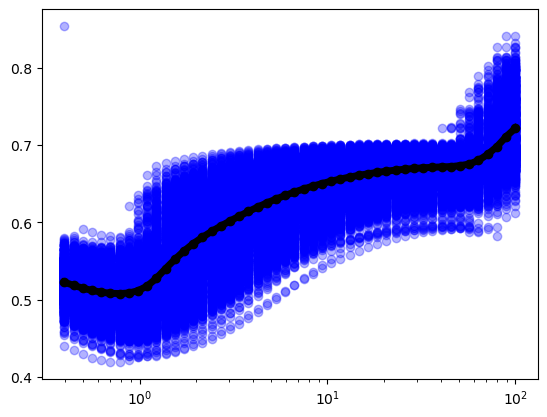

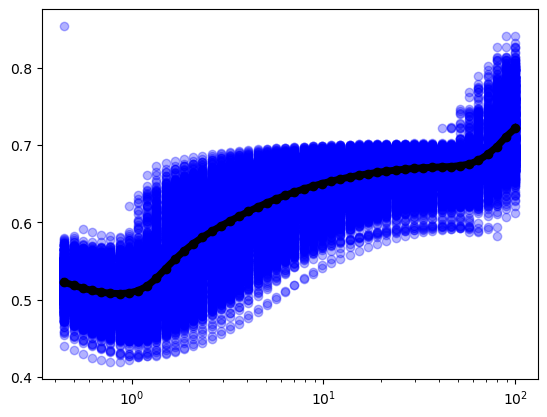

In [64]:
taus = np.logspace(-.4,2)
v = np.load('../numpy files/my_info_ec_1013_62.npy')
plt.plot(taus,v.T,'o', alpha=.3, color='blue')
plt.plot(taus,np.mean(v,0),'-o', lw=5, color='black')

plt.xscale('log');

plt.figure()
taus = np.logspace(-.35,2)
v = np.load('../numpy files/my_info_ec_1013_62.npy')

#v = -np.load('../numpy files/corr_62_1013_log.npy')
plt.plot(taus,v.T,'o', alpha=.3, color='blue')
plt.plot(taus,np.mean(v,0),'-o', lw=5, color='black')

plt.xscale('log');


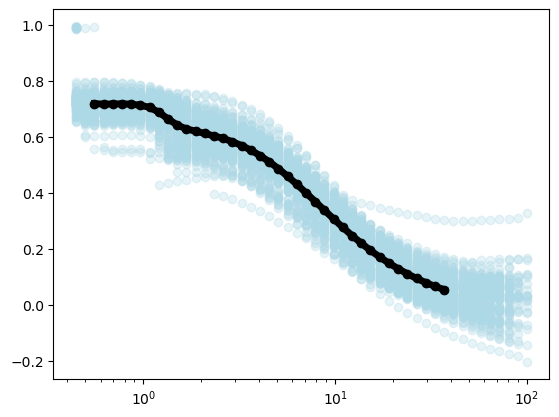

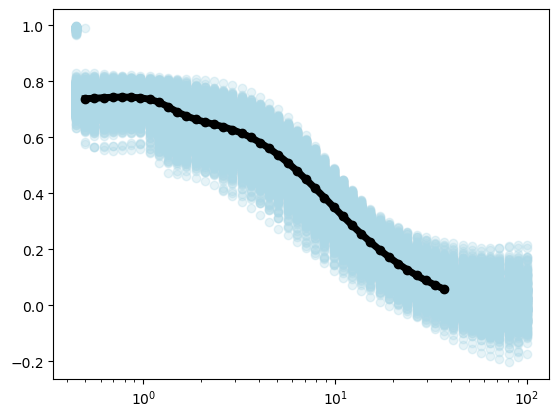

In [77]:
v =- np.load('../numpy files/corr__62_102sub_log.npy')
plt.plot(taus,v.T,'o',alpha=.3,color='lightblue')

plt.plot(taus,np.mean(v,0),'-o', lw=5, color='black')
plt.xscale('log')

plt.figure()

v = np.load('../numpy files/corr__62_1013_log.npy')
plt.plot(taus,v.T,'o',alpha=.3,color='lightblue')

plt.plot(taus,np.mean(v,0),'-o', lw=5, color='black')
plt.xscale('log')


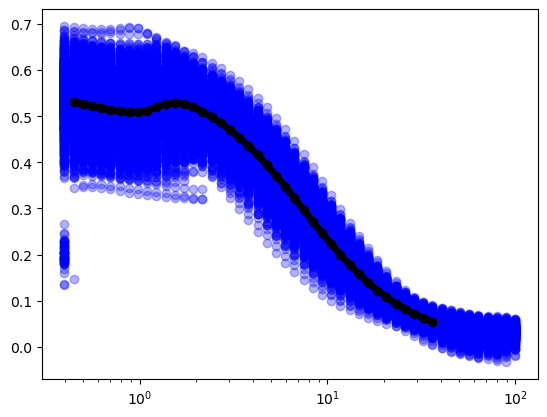

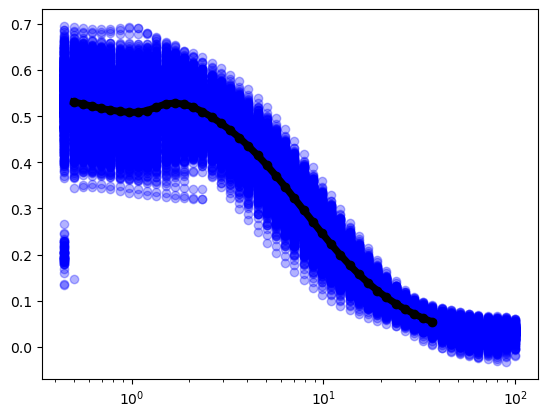

In [62]:
taus = np.logspace(-.4,2)
v = -np.load('../numpy files/corr_62_1013_log.npy')
plt.plot(taus,v.T,'o', alpha=.3, color='blue')
plt.plot(taus,np.mean(v,0),'-o', lw=5, color='black')

plt.xscale('log');

plt.figure()
taus = np.logspace(-.35,2)
v = -np.load('../numpy files/corr_62_1013_log.npy')
plt.plot(taus,v.T,'o', alpha=.3, color='blue')
plt.plot(taus,np.mean(v,0),'-o', lw=5, color='black')

plt.xscale('log');


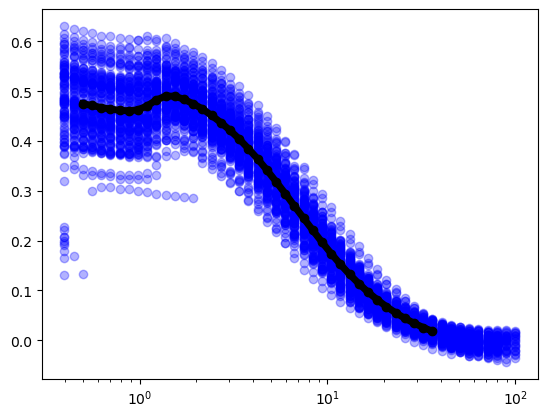

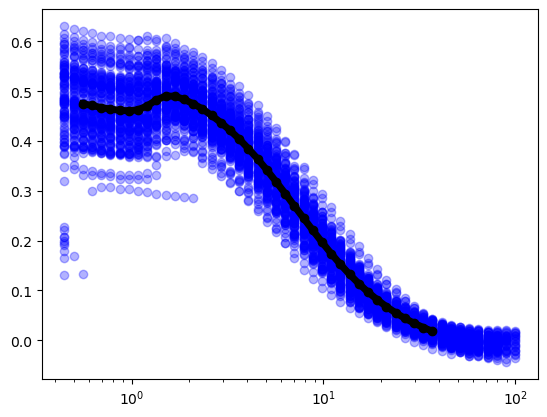

In [57]:
taus = np.logspace(-.4,2)
v = np.load('../numpy files/corr_62_102sub_log.npy')
plt.plot(taus,v.T,'o', alpha=.3, color='blue')
plt.plot(taus,np.mean(v,0),'-o', lw=5, color='black')

plt.xscale('log');

plt.figure()
taus = np.logspace(-.35,2)
v = np.load('../numpy files/corr_62_102sub_log.npy')
plt.plot(taus,v.T,'o', alpha=.3, color='blue')
plt.plot(taus,np.mean(v,0),'-o', lw=5, color='black')

plt.xscale('log');


In [95]:
my_info_ec=np.load('../numpy files/my_info_ec_1013_62.npy')
my_info_ec_=np.load('../numpy files/my_info_ec_1013_100.npy')

my_info_ec_.shape


(1009, 50)

In [102]:
from scipy.signal import find_peaks

def first_local_max(x, prominence=0.01):
    peaks, _ = find_peaks(x, prominence=prominence)

    if len(peaks) == 0:
        return np.argmax(x)  # fallback sul massimo globale

    return peaks[0]

taus_est_622=[]
taus =np.logspace(-.4,2,)
for i in range(1009):
    taus_est_622.append(taus[1:20][first_local_max(-my_info_ec_[i,1:20])])
print(np.mean(taus_est_622))


taus_est_62=[]
taus =np.logspace(-.4,2,)
for i in range(1013):
    taus_est_62.append(taus[1:20][first_local_max(-my_info_ec[i,1:20])])
print(np.mean(taus_est_62))

0.7160022909751991
0.8121752353620063


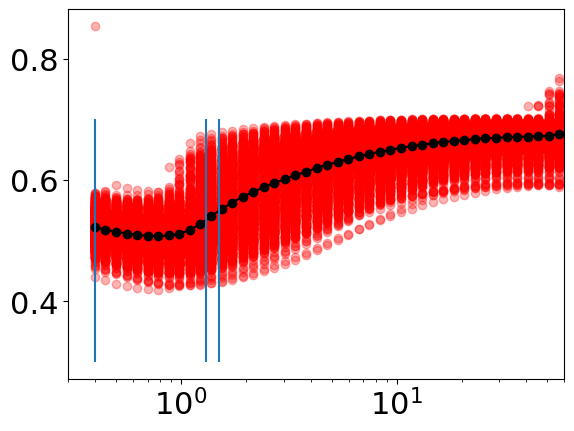

In [117]:
plt.plot(taus, my_info_ec.T, 'ro', alpha=.3);
plt.plot(taus, np.mean(my_info_ec,0), 'ko-');

plt.xscale('log')
plt.vlines(1.3,0.3,0.7)
plt.vlines(1.5,0.3,0.7)

plt.vlines(0.4,0.3,0.7)
plt.xlim(.3,60);

np.float64(0.7832087865456271)

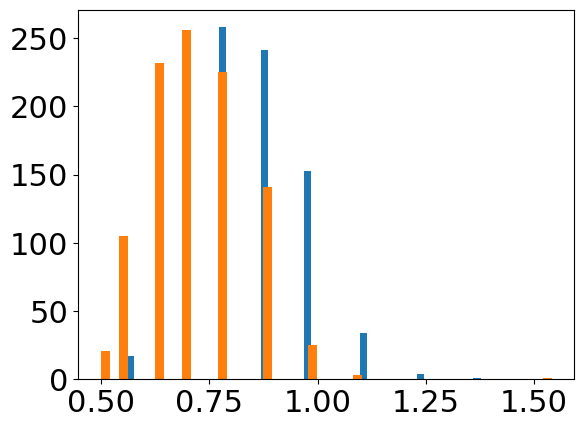

In [97]:
plt.hist(taus_est_62, bins=50
);

plt.hist(taus_est_622, bins=50
);
np.median(taus_est_62)

In [173]:
np.load('../numpy files/est_tau_delta.npy')

array([0.69967758, 1.09854114, 0.62505519, ..., 0.87671239, 1.09854114,
       0.78320879])

(0.4, 2.0)

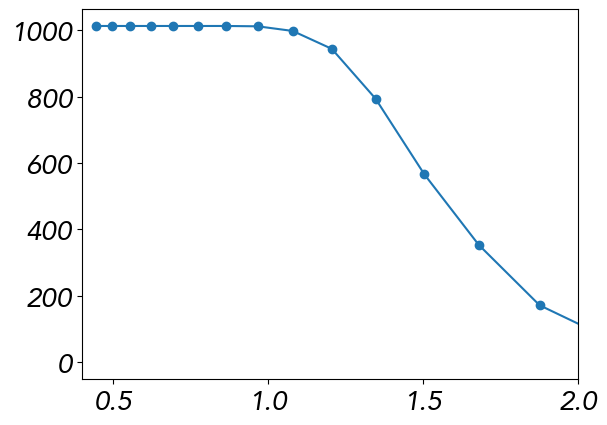

In [166]:
taus_=np.logspace(-.35,2)
plt.plot(taus_,np.sum(converged,0),'-o')
plt.xlim(0.4,2)

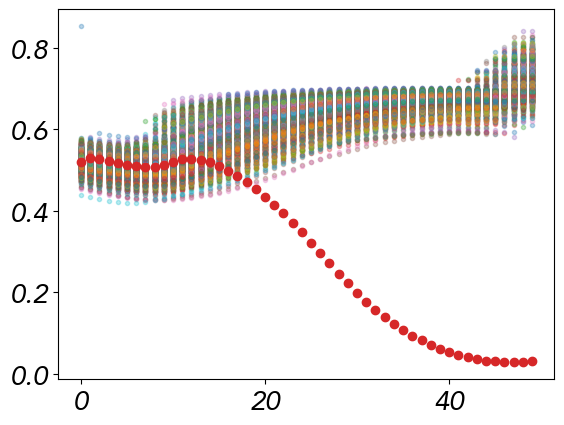

In [146]:
plt.plot(my_info_ec.T,'.',alpha=.3);
plt.plot(np.nanmean(corr,0),'o')

In [132]:
plt.rcParams['font.size']=24

In [118]:
corr_S_Q1asym = corr_S_Q1asym
corr_S_Q1asym_.shape,corr100.shape

((900, 1), (1013, 50))

In [393]:
corr100 = -corr

In [388]:
np.array_equal(corr100,-corr)

False

In [311]:
len(taus), len(corr[0]),len(corr_S_Q1asym_[0])
corr_S_Q1asym= corr
Y.shape

(1200, 100)

In [235]:
plt.rcParams['font.size'] =18

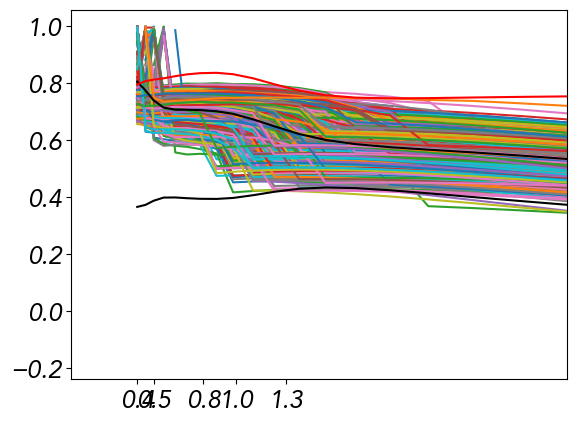

In [236]:
plt.plot(taus,corr100_.T, '-');
plt.plot(taus,np.nanmean(corr100_,0), 'k-');
plt.plot(taus,np.nanmean(corr100,0), 'k-');
plt.plot(taus,np.nanmean(corr_S_Q1asym,0), 'r-');
#plt.xscale('log')
plt.xlim(0,3)
plt.xticks([0.4,.5,.8,1,1.3]);

In [256]:
data_ref.shape, Y.shape

((1200, 112), (1200, 100))

## Calcolo di tau biologico

In [317]:
10**-.4, taus[0]

(0.3981071705534972, np.float64(0.3981071705534972))

In [257]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

# ==========================================================
# PARAMETERS
# ==========================================================

max_lag = 100
TR = 0.72
threshold = 1 / np.e

# ==========================================================
# COARSE-GRAIN DATA ONCE
# ==========================================================

Y_clustered = cluster_regions(
    Y[:, :100],
    aggregate[:100]
)

nroi = Y_clustered.shape[1]

autoc = []
taus_lag = []
taus_seconds = []

# ==========================================================
# AUTOCORRELATION AND 1/e CROSSING
# ==========================================================

for j in range(nroi):

    x_data = Y_clustered[:, j]

    auto_corr = acf(
        x_data,
        nlags=max_lag,
        fft=True,
        missing="drop"
    )

    autoc.append(auto_corr)

    # Indices at which ACF is below 1/e
    below_threshold = np.where(
        auto_corr < threshold
    )[0]

    if len(below_threshold) == 0:

        # ACF never crosses 1/e within max_lag
        tau_lag = np.nan
        tau_seconds = np.nan

    else:

        first_below = below_threshold[0]

        if first_below == 0:

            tau_lag = 0.0

        else:

            # Linear interpolation between the two ACF samples
            # surrounding the 1/e crossing
            lag_before = first_below - 1
            lag_after = first_below

            acf_before = auto_corr[lag_before]
            acf_after = auto_corr[lag_after]

            tau_lag = (
                lag_before
                + (
                    threshold - acf_before
                )
                / (
                    acf_after - acf_before
                )
            )

        tau_seconds = tau_lag * TR

    taus_lag.append(tau_lag)
    taus_seconds.append(tau_seconds)


autoc = np.asarray(autoc)
taus_lag = np.asarray(taus_lag)
taus_seconds = np.asarray(taus_seconds)

print(
    f"Mean tau: {np.nanmean(taus_lag):.2f} TR "
    f"({np.nanmean(taus_seconds):.2f} s)"
)

print(
    f"Median tau: {np.nanmedian(taus_lag):.2f} TR "
    f"({np.nanmedian(taus_seconds):.2f} s)"
)

Mean tau: 6.23 TR (4.49 s)
Median tau: 6.09 TR (4.39 s)


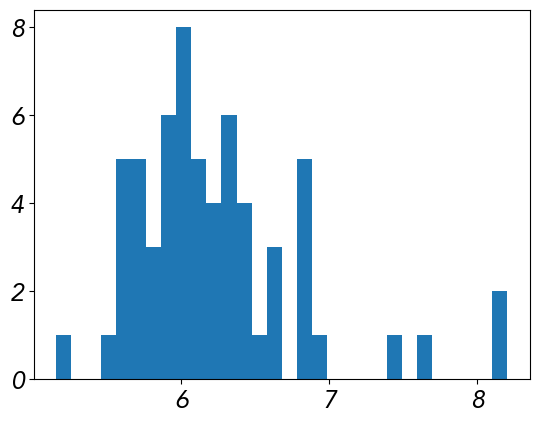

In [269]:
plt.hist(taus_lag, bins =30);

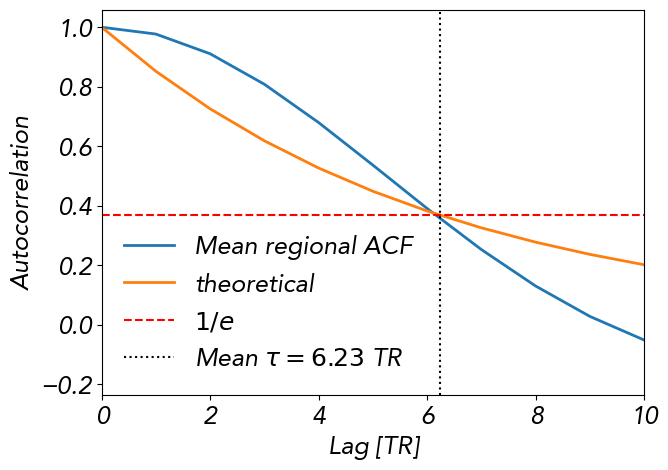

In [272]:
lags = np.arange(max_lag + 1)

mean_acf = np.nanmean(
    autoc,
    axis=0
)

plt.figure(figsize=(7, 5))

plt.plot(
    lags,
    mean_acf,
    linewidth=2,
    label="Mean regional ACF"
)


plt.plot(
    lags,
    np.exp(-lags/np.nanmean(taus_lag)),
    linewidth=2,
    label="theoretical"
)

plt.axhline(
    1 / np.e,
    color="red",
    linestyle="--",
    label=r"$1/e$"
)

plt.axvline(
    np.nanmean(taus_lag),
    color="black",
    linestyle=":",
    label=rf"Mean $\tau={np.nanmean(taus_lag):.2f}$ TR"
)
plt.xlim(0, 10)
plt.xlabel("Lag [TR]")
plt.ylabel("Autocorrelation")
plt.legend(frameon=False)
plt.show()

Median fitted tau: 9.355073971237964 s
Median R²: 0.9483793782995094
Correlation crossing vs exponential fit: 0.975764972783962
Median absolute difference: 4.933649984434914 s


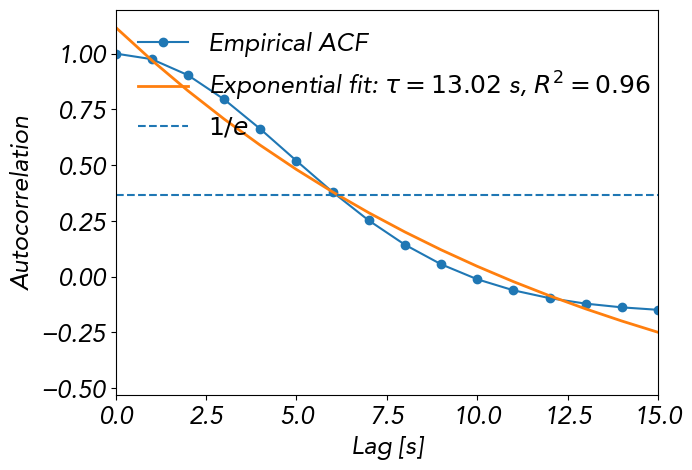

In [275]:
import numpy as np
from scipy.optimize import curve_fit


def exponential_acf(t, tau, amplitude, offset):
    return amplitude * np.exp(-t / tau) + offset


def estimate_acf_tau(
    auto_corr,
    TR=0.72,
    fit_max_lag=10
):
    """
    Stima tau mediante fit esponenziale dell'ACF.

    Parameters
    ----------
    auto_corr : array
        ACF, con auto_corr[0] = 1.
    TR : float
        Repetition time in seconds.
    fit_max_lag : int
        Numero massimo di lag incluso nel fit.

    Returns
    -------
    tau_seconds, r_squared, fitted_acf
    """

    n_fit = min(
        fit_max_lag + 1,
        len(auto_corr)
    )

    time = (
        np.arange(n_fit)
        * TR
    )

    y = np.asarray(
        auto_corr[:n_fit],
        dtype=float
    )

    valid = (
        np.isfinite(y)
        & (y > 0)
    )

    time_fit = time[valid]
    y_fit = y[valid]

    if len(y_fit) < 4:
        return np.nan, np.nan, np.full(n_fit, np.nan)

    try:

        parameters, _ = curve_fit(
            exponential_acf,
            time_fit,
            y_fit,
            p0=[
                2.0,   # tau iniziale, secondi
                1.0,   # amplitude
                0.0    # offset
            ],
            bounds=(
                [0.01, 0.0, -1.0],
                [100.0, 2.0, 1.0]
            ),
            maxfev=10000
        )

        tau, amplitude, offset = parameters

        fitted_acf = exponential_acf(
            time,
            tau,
            amplitude,
            offset
        )

        fitted_on_valid = exponential_acf(
            time_fit,
            tau,
            amplitude,
            offset
        )

        residual_sum_squares = np.sum(
            (y_fit - fitted_on_valid) ** 2
        )

        total_sum_squares = np.sum(
            (y_fit - np.mean(y_fit)) ** 2
        )

        if total_sum_squares > 0:
            r_squared = (
                1
                - residual_sum_squares
                / total_sum_squares
            )
        else:
            r_squared = np.nan

        return tau, r_squared, fitted_acf

    except (RuntimeError, ValueError):
        return np.nan, np.nan, np.full(n_fit, np.nan)
tau_fit_all = []
r2_all = []

for auto_corr in autoc:

    tau_fit, r2, fitted_acf = estimate_acf_tau(
        auto_corr,
        TR=0.72,
        fit_max_lag=10
    )

    tau_fit_all.append(tau_fit)
    r2_all.append(r2)

tau_fit_all = np.asarray(tau_fit_all)
r2_all = np.asarray(r2_all)

print(
    "Median fitted tau:",
    np.nanmedian(tau_fit_all),
    "s"
)

print(
    "Median R²:",
    np.nanmedian(r2_all)
)
valid = (
    np.isfinite(taus_seconds)
    & np.isfinite(tau_fit_all)
)

r_tau = np.corrcoef(
    taus_seconds[valid],
    tau_fit_all[valid]
)[0, 1]

print(
    "Correlation crossing vs exponential fit:",
    r_tau
)

print(
    "Median absolute difference:",
    np.nanmedian(
        np.abs(
            taus_seconds[valid]
            - tau_fit_all[valid]
        )
    ),
    "s"
)
import matplotlib.pyplot as plt

region = 0

auto_corr = autoc[region]

tau_fit, r2, fitted_acf = estimate_acf_tau(
    auto_corr,
    TR=1,
    fit_max_lag=20
)

time = (
    np.arange(len(auto_corr))
    
)

fit_time = (
    np.arange(len(fitted_acf))
    
)

plt.figure(figsize=(7, 5))

plt.plot(
    time,
    auto_corr,
    marker="o",
    label="Empirical ACF"
)

plt.plot(
    fit_time,
    fitted_acf,
    linewidth=2,
    label=(
        rf"Exponential fit: "
        rf"$\tau={tau_fit:.2f}$ s, "
        rf"$R^2={r2:.2f}$"
    )
)

plt.axhline(
    1 / np.e,
    linestyle="--",
    label=r"$1/e$"
)

plt.xlim(0, 15)
plt.xlabel("Lag [s]")
plt.ylabel("Autocorrelation")
plt.legend(frameon=False)
plt.show()

In [54]:
url = "https://github.com/omarwagih/scichat/raw/master/fonts/avenir/Avenir-Oblique.ttf"
import urllib.request
from matplotlib import font_manager as fm
# Salva localmente
font_file = "Avenir-Oblique.ttf"
urllib.request.urlretrieve(url, font_file)

# Registra il font in Matplotlib

fm.fontManager.addfont(font_file)

font_name = fm.FontProperties(fname=font_file).get_name()
print(font_name)
plt.rcParams["font.family"] = "Avenir"

Avenir


In [116]:
ass100.shape

(102, 50)